# Dysarthria Detection V4 — Mac / Apple Silicon Ready

This version keeps the original V4 pipeline, feature definitions, evaluation flow, and resumable checkpoints, while adding local macOS support.

**Designed for:** Apple Silicon Mac (including M5), 16 GB unified memory.

**Changes:** MPS GPU support; version-local outputs in `v4/outputs/`; version-local caches, checkpoints, and timestamped notebook backups in `v4/backups/`; default batch size 16; local dataset path override or KaggleHub download; path-independent exclusion of the two known unreadable TORGO files; safer classical delta extraction; checkpoint optimizer-state restoration for MPS/CPU portability.

> The first local run still has to build the Mac-side feature cache once. Later runs reuse successful per-file shards and resume training from checkpoints after interruptions.


In [36]:
# =====================================================================
# Dysarthria Detection V4 — Restart-Safe / Incremental Cache Pipeline
# =====================================================================
# IMPORTANT:
#   - This notebook is designed to be run with "Run All" after any fix.
#   - Expensive preprocessing is cached per audio file.
#   - Training is checkpointed during the epoch, not only at the end.
#   - Completed stages/models are automatically loaded and skipped.
#   - V4 uses its own cache root, so old V3 placeholder caches are ignored.

import os
import glob
import json
import copy
import pickle
import random
import hashlib
import warnings
import tempfile
import sys
import shutil
from datetime import datetime
from pathlib import Path

warnings.filterwarnings("ignore")

# Apple Silicon: let unsupported MPS operators fall back to CPU.
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

import numpy as np
import pandas as pd
import librosa
import librosa.display
import soundfile as sf

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from matplotlib.patches import Patch, FancyBboxPatch, FancyArrowPatch

from sklearn.model_selection import GroupShuffleSplit, GridSearchCV, GroupKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score, average_precision_score,
    brier_score_loss, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, roc_curve, classification_report
)
from sklearn.calibration import calibration_curve

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim

from scipy import stats
from tqdm.auto import tqdm

# ---------------------------------------------------------------------
# V4 configuration
# ---------------------------------------------------------------------
CONFIG = {
    "version": "V4",
    "seed_list": [42, 43, 44, 45, 46],
    "mel_bins": 80,
    "frames": 128,
    "embedding_dim": 256,
    "num_classes": 2,
    "speaker_classes": 8,
    "lambda_supcon": 0.10,
    "lambda_adv": 0.02,
    "lr_encoder": 1e-4,
    "lr_classifier": 5e-4,
    "weight_decay": 1e-4,
    "stream1_gate_init": 0.80,
    "use_gender_auxiliary": False,
}

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

# MPS uses the Apple GPU. CPU thread controls help only when PyTorch must train
# on CPU, and can slow the MPS submission path if forced unconditionally.
CPU_THREADS = max(1, int(os.environ.get("DYSARTHRIA_CPU_THREADS", os.cpu_count() or 1)))
if DEVICE.type == "cpu":
    torch.set_num_threads(CPU_THREADS)
    torch.set_num_interop_threads(min(4, CPU_THREADS))

SAMPLE_RATE  = 16000
N_MFCC       = 13
N_MELS       = 80
HOP_LENGTH   = 160
WIN_LENGTH   = 400
MAX_FRAMES   = 128
TRAJ_DIM     = 64

EMBED_DIM    = 256
# Batch size 16 is the measured fast, stable MPS baseline for this model.
# Larger batches can slow this Transformer/LSTM workload on unified-memory Macs.
BATCH_SIZE   = max(1, int(os.environ.get("DYSARTHRIA_BATCH_SIZE", 16)))
# Full checkpoints include optimizer state and are expensive on every batch.
# At most 24 completed batches are replayed after an interruption.
CHECKPOINT_INTERVAL_BATCHES = max(1, int(os.environ.get("DYSARTHRIA_CHECKPOINT_INTERVAL", 25)))
PRETRAIN_EPOCHS  = 50
FINETUNE_EPOCHS  = 100
LR_PRETRAIN  = 1e-3
LR_FINETUNE  = 5e-4
WEIGHT_DECAY = 1e-4
TEMPERATURE  = 0.07
WARMUP_EPOCHS = 5
EARLY_STOP_PATIENCE = 30

ALPHA_DYSARTHRIA = 1.0
BETA_GENDER      = 0.0
LAMBDA_SUPCON    = 0.10
LAMBDA_ADV       = 0.02

TRAIN_RATIO = 0.70
VAL_RATIO   = 0.15
TEST_RATIO  = 0.15

N_BOOTSTRAP = 1000
CI_LEVEL    = 0.95
SNR_LEVELS  = [30, 20, 10, 5, 0]

LABEL_MAP = {0: "Control", 1: "Dysarthric"}
GENDER_MAP = {0: "Female", 1: "Male"}
GENDER_TO_LABEL = {"female": 0, "male": 1, "unknown": 0}

# ---------------------------------------------------------------------
# Single source of truth for all persistent V4 caches
# ---------------------------------------------------------------------
PIPELINE_SIGNATURE = "v4_resumable_pipeline_1"

_signature_payload = {
    "pipeline_signature": PIPELINE_SIGNATURE,
    "config": CONFIG,
    "sample_rate": SAMPLE_RATE,
    "n_mfcc": N_MFCC,
    "n_mels": N_MELS,
    "hop_length": HOP_LENGTH,
    "win_length": WIN_LENGTH,
    "max_frames": MAX_FRAMES,
    "traj_dim": TRAJ_DIM,
    "embed_dim": EMBED_DIM,
    "batch_size": BATCH_SIZE,
    "pretrain_epochs": PRETRAIN_EPOCHS,
    "finetune_epochs": FINETUNE_EPOCHS,
    "lr_pretrain": LR_PRETRAIN,
    "lr_finetune": LR_FINETUNE,
    "temperature": TEMPERATURE,
}
RUN_ID = hashlib.sha256(
    json.dumps(_signature_payload, sort_keys=True, default=str).encode("utf-8")
).hexdigest()[:16]

# Resolve the version folder independently of the launch directory.
# DYSARTHRIA_V4_DIR and DYSARTHRIA_V4_CACHE_ROOT can override these paths.
VERSION = "v4"
NOTEBOOK_NAME = "dysarthria-v4.ipynb"
_cwd = Path.cwd().resolve()
_version_dir_override = os.environ.get("DYSARTHRIA_V4_DIR")
_version_candidates = [
    Path(_version_dir_override).expanduser().resolve() if _version_dir_override else None,
    _cwd,
    _cwd / VERSION,
    _cwd.parent / VERSION,
]
VERSION_DIR = next(
    (p for p in _version_candidates if p is not None and (p / NOTEBOOK_NAME).exists()),
    _cwd,
)
OUTPUT_DIR = VERSION_DIR / "outputs"
BACKUP_DIR = VERSION_DIR / "backups"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

# Keep a timestamped copy of the saved notebook before each run.
NOTEBOOK_PATH = VERSION_DIR / NOTEBOOK_NAME
if NOTEBOOK_PATH.exists():
    _backup_path = BACKUP_DIR / f"{NOTEBOOK_PATH.stem}_{datetime.now().strftime('%Y%m%d_%H%M%S')}.ipynb"
    if not _backup_path.exists():
        shutil.copy2(NOTEBOOK_PATH, _backup_path)

V4_ROOT = os.path.expanduser(
    os.environ.get("DYSARTHRIA_V4_CACHE_ROOT", str(BACKUP_DIR / "dysarthria_detection_v4"))
)
CACHE_DIR = os.path.join(V4_ROOT, f"run_{RUN_ID}")
CHECKPOINT_DIR = os.path.join(CACHE_DIR, "checkpoints")
DUAL_SHARD_DIR = os.path.join(CACHE_DIR, "dual_stream_shards")
CLASSICAL_SHARD_DIR = os.path.join(CACHE_DIR, "classical_feature_shards")
STAGE_DIR = os.path.join(CACHE_DIR, "stages")

for _d in [V4_ROOT, CACHE_DIR, CHECKPOINT_DIR, DUAL_SHARD_DIR, CLASSICAL_SHARD_DIR, STAGE_DIR]:
    os.makedirs(_d, exist_ok=True)

FEATURE_CACHE_PATH = os.path.join(CACHE_DIR, "dual_stream_features.npz")
CLASSICAL_FEATURE_CACHE_PATH = os.path.join(CACHE_DIR, "classical_features.npy")
SPLIT_CACHE_PATH = os.path.join(STAGE_DIR, "speaker_split.pkl")
SCALER_SELECTOR_CACHE_PATH = os.path.join(STAGE_DIR, "classical_scaler_selector.pkl")
CLASSICAL_MODELS_CACHE_PATH = os.path.join(STAGE_DIR, "classical_models.pkl")

PRETRAIN_RESUME_PATH = os.path.join(CHECKPOINT_DIR, "v4_pretrain_resume.pt")
PRETRAIN_FINAL_PATH  = os.path.join(CHECKPOINT_DIR, "v4_pretrain_final.pt")
FINETUNE_RESUME_PATH = os.path.join(CHECKPOINT_DIR, "v4_proposed_finetune_resume.pt")
FINETUNE_FINAL_PATH  = os.path.join(CHECKPOINT_DIR, "v4_proposed_final.pt")

# These names are retained for compatibility with later V3 code.
pretrained_ckpt_path = PRETRAIN_FINAL_PATH
finetune_ckpt_path = FINETUNE_FINAL_PATH

def _atomic_replace(tmp_path, final_path):
    os.makedirs(os.path.dirname(final_path), exist_ok=True)
    os.replace(tmp_path, final_path)

def atomic_pickle_dump(obj, path):
    tmp = path + ".tmp"
    with open(tmp, "wb") as f:
        pickle.dump(obj, f, protocol=pickle.HIGHEST_PROTOCOL)
        f.flush()
        os.fsync(f.fileno())
    _atomic_replace(tmp, path)

def atomic_json_dump(obj, path):
    tmp = path + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, sort_keys=True, default=str)
        f.flush()
        os.fsync(f.fileno())
    _atomic_replace(tmp, path)

def atomic_numpy_save(array, path):
    tmp = path + ".tmp.npy"
    np.save(tmp, array, allow_pickle=False)
    _atomic_replace(tmp, path)

def atomic_npz_save(path, **arrays):
    tmp = path + ".tmp.npz"
    np.savez_compressed(tmp, **arrays)
    _atomic_replace(tmp, path)

def atomic_torch_save(obj, path):
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    _atomic_replace(tmp, path)

def safe_torch_load(path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)

def move_optimizer_state_to_device(optimizer, device):
    """Move optimizer tensor state to the active device after checkpoint restore."""
    for state in optimizer.state.values():
        for key, value in list(state.items()):
            if torch.is_tensor(value):
                state[key] = value.to(device)


def capture_rng_state(extra_rng=None):
    state = {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
    }
    if torch.cuda.is_available():
        state["torch_cuda"] = torch.cuda.get_rng_state_all()
    if extra_rng is not None:
        state["extra_rng"] = extra_rng.get_state()
    return state

def restore_rng_state(state, extra_rng=None):
    if not state:
        return
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])
    if torch.cuda.is_available() and "torch_cuda" in state:
        torch.cuda.set_rng_state_all(state["torch_cuda"])
    if extra_rng is not None and "extra_rng" in state:
        extra_rng.set_state(state["extra_rng"])

def dataframe_signature(df, columns=None):
    if columns is None:
        columns = list(df.columns)
    records = []
    for _, row in df[columns].iterrows():
        records.append([str(v) for v in row.tolist()])
    raw = json.dumps(records, sort_keys=False, ensure_ascii=True).encode("utf-8")
    return hashlib.sha256(raw).hexdigest()

def file_cache_key(file_path, stage, extra=None):
    file_path = os.path.abspath(file_path)
    try:
        st = os.stat(file_path)
        stat_info = {"size": st.st_size, "mtime_ns": st.st_mtime_ns}
    except OSError:
        stat_info = {"size": None, "mtime_ns": None}
    payload = {
        "pipeline_signature": PIPELINE_SIGNATURE,
        "stage": stage,
        "file_path": file_path,
        "stat": stat_info,
        "extra": extra or {},
    }
    return hashlib.sha256(
        json.dumps(payload, sort_keys=True, default=str).encode("utf-8")
    ).hexdigest()

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("MPS available:", hasattr(torch.backends, "mps") and torch.backends.mps.is_available())
print("Using device:", DEVICE)
print(f"Batch size: {BATCH_SIZE} | Checkpoint interval: {CHECKPOINT_INTERVAL_BATCHES} batches")
if DEVICE.type == "cpu":
    print(f"CPU training threads: {CPU_THREADS}")
print("V4 cache:", CACHE_DIR)


PyTorch version: 2.14.0
CUDA available: False
MPS available: True
Using device: mps
Batch size: 16 | Checkpoint interval: 25 batches
V4 cache: /Users/Noor/dysarthria-v4/cache/dysarthria_detection_v4/run_e1eb4e70a21d7fc1


In [37]:

class AttentionPooling(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.attention = nn.Sequential(
            nn.Linear(dim, dim//2),
            nn.Tanh(),
            nn.Linear(dim//2, 1)
        )

    def forward(self, x, mask=None):
        scores = self.attention(x).squeeze(-1)

        if mask is not None:
            scores = scores.masked_fill(~mask, -1e9)

        weights = torch.softmax(scores, dim=1)
        return torch.sum(x * weights.unsqueeze(-1), dim=1), weights


class GradientReverseFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lambd):
        ctx.lambd=lambd
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):
        return -ctx.lambd*grad_output, None


class GradientReversal(nn.Module):
    def __init__(self,lambd=0.1):
        super().__init__()
        self.lambd=lambd

    def forward(self,x):
        return GradientReverseFunction.apply(x,self.lambd)


In [38]:
# =====================================================================
# Dataset acquisition — local macOS or Kaggle
# =====================================================================
DATASET_HANDLE = "pranaykoppula/torgo-audio"

# Optional: set TORGO_DATASET_PATH to an already-downloaded TORGO directory.
LOCAL_DATASET_PATH = os.environ.get("TORGO_DATASET_PATH", "").strip()

if LOCAL_DATASET_PATH:
    path = os.path.abspath(os.path.expanduser(LOCAL_DATASET_PATH))
    if not os.path.isdir(path):
        raise FileNotFoundError(
            f"TORGO_DATASET_PATH does not exist or is not a directory: {path}"
        )
    print("Using existing local TORGO dataset:", path)
else:
    import kagglehub
    path = kagglehub.dataset_download(DATASET_HANDLE)
    print("TORGO dataset path:", path)


TORGO dataset path: /Users/Noor/.cache/kagglehub/datasets/pranaykoppula/torgo-audio/versions/1


In [39]:
# =====================================================================
# Mac / runtime environment check
# =====================================================================
import platform
print("OS            :", platform.platform())
print("Python        :", platform.python_version())
print("PyTorch       :", torch.__version__)
print("Device        :", DEVICE)
if sys.platform == "darwin":
    print("Architecture  :", platform.machine())
    print("V4 cache root :", V4_ROOT)
    if not (hasattr(torch.backends, "mps") and torch.backends.mps.is_available()):
        print("[WARNING] MPS is unavailable; training will use CPU.")


OS            : macOS-26.5.1-arm64-arm-64bit
Python        : 3.12.14
PyTorch       : 2.14.0
Device        : mps
Architecture  : arm64
V4 cache root : /Users/Noor/dysarthria-v4/cache/dysarthria_detection_v4


In [40]:
# ── Global plot style ────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'figure.facecolor': 'white',
    'axes.facecolor': '#f8f9fa',
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

COLORS = {
    'control':    '#2196F3',   # blue
    'dysarthric': '#F44336',   # red
    'head':       '#4CAF50',   # green
    'array':      '#FF9800',   # orange
    'male':       '#3F51B5',   # indigo
    'female':     '#E91E63',   # pink
    'accent':     '#9C27B0',   # purple
    'accent2':    '#00BCD4',   # cyan
}

In [41]:
# =====================================================================
# 2a. Collect all WAV files
# =====================================================================
DATASET_PATH = path
wav_files = sorted(glob.glob(os.path.join(DATASET_PATH, "**", "*.wav"), recursive=True))

print(f"Dataset path : {DATASET_PATH}")
print(f"Total WAV files found: {len(wav_files)}")
for _f in wav_files[:5]:
    print(" ", _f)

if not wav_files:
    raise FileNotFoundError(
        f"No .wav files were found under {DATASET_PATH}. "
        "Check the Kaggle dataset mount before continuing."
    )


Dataset path : /Users/Noor/.cache/kagglehub/datasets/pranaykoppula/torgo-audio/versions/1
Total WAV files found: 17633
  /Users/Noor/.cache/kagglehub/datasets/pranaykoppula/torgo-audio/versions/1/F_Con/wav_arrayMic_FC01S01/wav_arrayMic_FC01S01_0001.wav
  /Users/Noor/.cache/kagglehub/datasets/pranaykoppula/torgo-audio/versions/1/F_Con/wav_arrayMic_FC01S01/wav_arrayMic_FC01S01_0002.wav
  /Users/Noor/.cache/kagglehub/datasets/pranaykoppula/torgo-audio/versions/1/F_Con/wav_arrayMic_FC01S01/wav_arrayMic_FC01S01_0003.wav
  /Users/Noor/.cache/kagglehub/datasets/pranaykoppula/torgo-audio/versions/1/F_Con/wav_arrayMic_FC01S01/wav_arrayMic_FC01S01_0004.wav
  /Users/Noor/.cache/kagglehub/datasets/pranaykoppula/torgo-audio/versions/1/F_Con/wav_arrayMic_FC01S01/wav_arrayMic_FC01S01_0005.wav


In [42]:
# ── Microphone split check ────────────────────────────────────
head_files  = [f for f in wav_files if "headMic"  in f]
array_files = [f for f in wav_files if "arrayMic" in f]
print(f"\nHead-mic files : {len(head_files)}")
print(f"Array-mic files: {len(array_files)}")


Head-mic files : 8218
Array-mic files: 9415


In [43]:
# =====================================================================
# 2b. Build / reload metadata
# =====================================================================
METADATA_CACHE_PATH = os.path.join(STAGE_DIR, "metadata.pkl")
_metadata_signature = hashlib.sha256(
    json.dumps(
        [{"path": os.path.abspath(f), "size": os.path.getsize(f) if os.path.exists(f) else None}
         for f in wav_files],
        sort_keys=True
    ).encode("utf-8")
).hexdigest()

metadata = []
for file_path in wav_files:
    parts = file_path.split("/")
    if len(parts) < 3:
        continue

    group_folder   = parts[-3]
    speaker_folder = parts[-2]

    if "Dys" in group_folder:
        label = 1
    elif "Con" in group_folder:
        label = 0
    else:
        continue

    if group_folder.startswith("F"):
        gender = "female"
    elif group_folder.startswith("M"):
        gender = "male"
    else:
        gender = "unknown"

    if "headMic" in speaker_folder:
        mic_type = "head"
    elif "arrayMic" in speaker_folder:
        mic_type = "array"
    else:
        mic_type = "unknown"

    speaker_id = (
        speaker_folder
        .replace("wav_headMic_", "")
        .replace("wav_arrayMic_", "")
    )

    metadata.append({
        "file_path": file_path,
        "speaker_id": speaker_id,
        "gender": gender,
        "mic_type": mic_type,
        "label": label,
        "group": group_folder,
    })

metadata_df = (
    pd.DataFrame(metadata)
    .sort_values("file_path")
    .reset_index(drop=True)
)

if metadata_df.empty:
    raise RuntimeError("Metadata parsing produced zero usable audio files.")

atomic_pickle_dump(
    {
        "pipeline_signature": PIPELINE_SIGNATURE,
        "source_signature": _metadata_signature,
        "metadata": metadata_df,
    },
    METADATA_CACHE_PATH,
)

print("Metadata shape:", metadata_df.shape)
print("\nLabel distribution:")
print(metadata_df["label"].value_counts())
print("\nMic type distribution:")
print(metadata_df["mic_type"].value_counts())
print(f"\nUnique speakers: {metadata_df['speaker_id'].nunique()}")


Metadata shape: (17633, 6)

Label distribution:
label
0    11455
1     6178
Name: count, dtype: int64

Mic type distribution:
mic_type
array    9415
head     8218
Name: count, dtype: int64

Unique speakers: 30


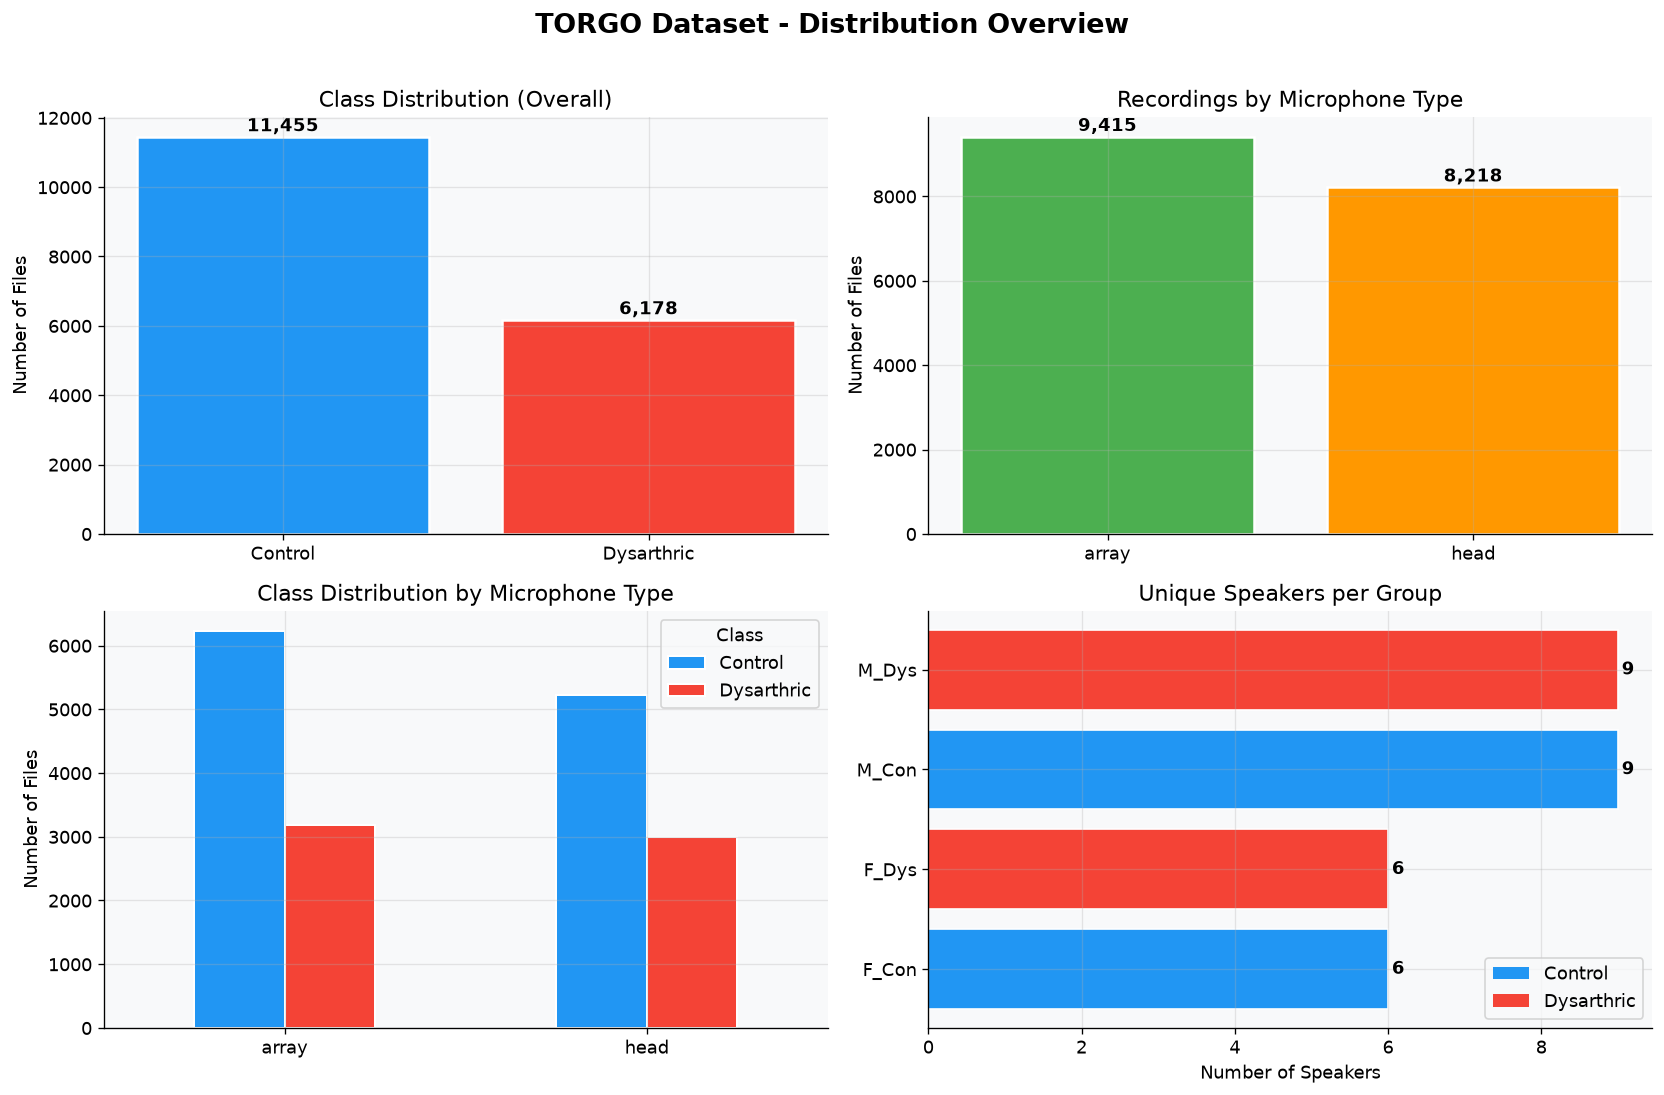

Figure 1 saved.


In [44]:
# ── Figure 1: Dataset overview - 4 panel bar charts ──────────
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle("TORGO Dataset - Distribution Overview", fontsize=16, fontweight='bold', y=1.01)

# Panel 1: Label counts
ax = axes[0, 0]
label_counts = metadata_df["label"].map({0: "Control", 1: "Dysarthric"}).value_counts()
bars = ax.bar(label_counts.index, label_counts.values,
              color=[COLORS['control'], COLORS['dysarthric']], edgecolor='white', linewidth=1.5)
ax.set_title("Class Distribution (Overall)")
ax.set_ylabel("Number of Files")
for bar, val in zip(bars, label_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
            f'{val:,}', ha='center', va='bottom', fontweight='bold')

# Panel 2: Mic type counts
ax = axes[0, 1]
mic_counts = metadata_df["mic_type"].value_counts()
bars = ax.bar(mic_counts.index, mic_counts.values,
              color=[COLORS['head'], COLORS['array']], edgecolor='white', linewidth=1.5)
ax.set_title("Recordings by Microphone Type")
ax.set_ylabel("Number of Files")
for bar, val in zip(bars, mic_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
            f'{val:,}', ha='center', va='bottom', fontweight='bold')

# Panel 3: Class x Mic cross-tabulation
ax = axes[1, 0]
cross = metadata_df.groupby(["mic_type", "label"]).size().unstack()
cross.columns = ["Control", "Dysarthric"]
cross.plot(kind="bar", ax=ax, color=[COLORS['control'], COLORS['dysarthric']],
           edgecolor='white', linewidth=1.2)
ax.set_title("Class Distribution by Microphone Type")
ax.set_ylabel("Number of Files")
ax.set_xlabel("")
ax.legend(title="Class")
ax.tick_params(axis='x', rotation=0)

# Panel 4: Speakers per group
ax = axes[1, 1]
spk_group = metadata_df.groupby("group")["speaker_id"].nunique().sort_values()
colors_grp = [COLORS['dysarthric'] if 'Dys' in g else COLORS['control'] for g in spk_group.index]
bars = ax.barh(spk_group.index, spk_group.values, color=colors_grp, edgecolor='white')
ax.set_title("Unique Speakers per Group")
ax.set_xlabel("Number of Speakers")
for bar, val in zip(bars, spk_group.values):
    ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
            str(val), va='center', fontweight='bold')

legend_elements = [Patch(facecolor=COLORS['control'],    label='Control'),
                   Patch(facecolor=COLORS['dysarthric'], label='Dysarthric')]
ax.legend(handles=legend_elements)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig1_dataset_overview.png", bbox_inches='tight', dpi=150)
plt.show()
print("Figure 1 saved.")

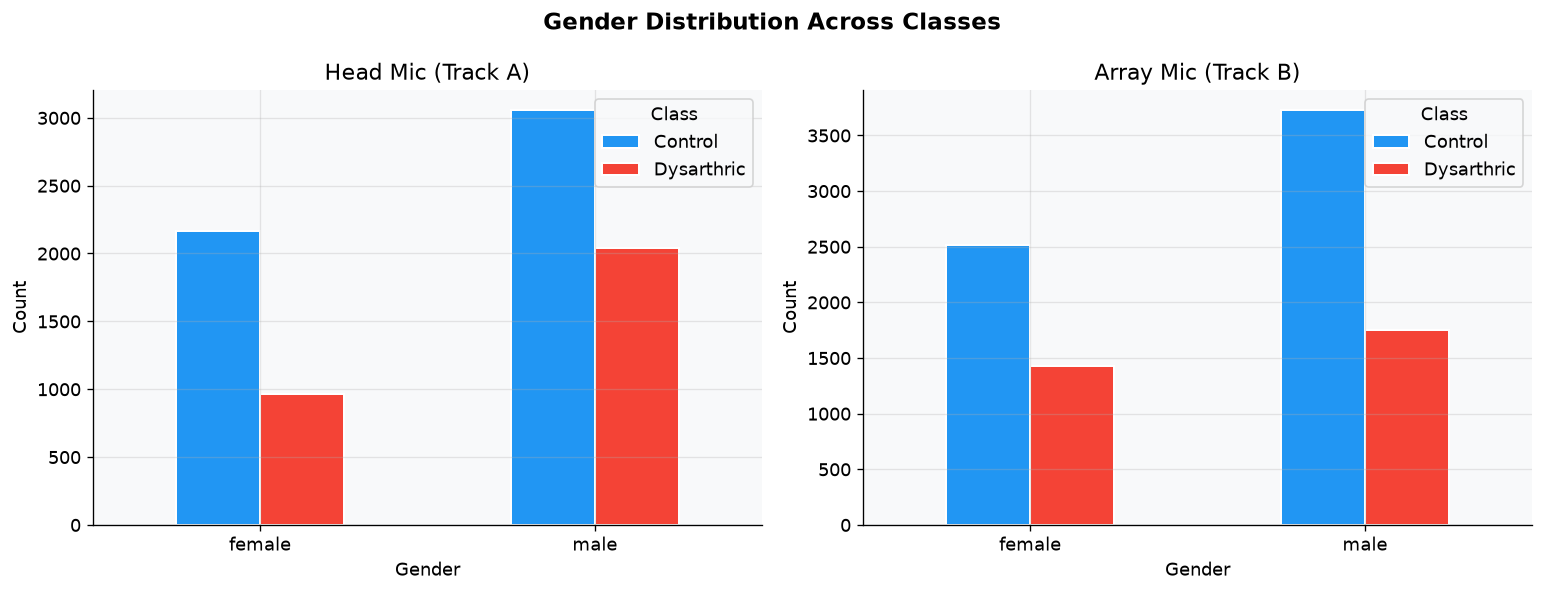

Figure 2 saved.


In [45]:
# ── Figure 2: Gender breakdown ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Gender Distribution Across Classes", fontsize=14, fontweight='bold')

for ax, mic_label, mic_key in zip(axes, ["Head Mic (Track A)", "Array Mic (Track B)"], ["head", "array"]):
    sub = metadata_df[metadata_df["mic_type"] == mic_key]
    pivot = sub.groupby(["gender", "label"]).size().unstack(fill_value=0)
    pivot.columns = ["Control", "Dysarthric"]
    pivot.plot(kind="bar", ax=ax, color=[COLORS['control'], COLORS['dysarthric']],
               edgecolor='white', linewidth=1.2)
    ax.set_title(mic_label)
    ax.set_xlabel("Gender")
    ax.set_ylabel("Count")
    ax.tick_params(axis='x', rotation=0)
    ax.legend(title="Class")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig2_gender_distribution.png", bbox_inches='tight', dpi=150)
plt.show()
print("Figure 2 saved.")

In [46]:
# ── Preprocessing functions ───────────────────────────────────
# Following Schu et al. (2022): address SNR disparity by
# applying microphone-specific denoising to each track

def microphone_specific_denoising(audio, mic_type):
    '''
    Apply microphone-appropriate noise reduction.

    Args:
        audio: 1-D np.ndarray, raw waveform samples.
        mic_type: str, either "head" or "array".

    Returns:
        np.ndarray of the same shape as `audio`, denoised.

    Head mic  : minimal processing - signal is already clean.
    Array mic : spectral-subtraction-style threshold to suppress
                low-amplitude background noise from room acoustics.
    '''
    if mic_type == "head":
        # Head mic is close-field; light normalization is sufficient
        denoised = audio

    elif mic_type == "array":
        # Array mic captures room reflections; suppress values
        # below 1% of peak amplitude (simple spectral gating)
        noise_threshold = 0.01 * np.max(np.abs(audio)) if np.max(np.abs(audio)) > 0 else 0.01
        denoised = np.where(np.abs(audio) < noise_threshold, 0.0, audio)

    else:
        denoised = audio

    return denoised


def preprocess_audio(file_path, mic_type, sr=SAMPLE_RATE):
    '''
    Full preprocessing pipeline for one audio file.

    Args:
        file_path: str, path to a .wav file.
        mic_type: str, "head" or "array" (controls trim threshold / denoising).
        sr: int, target sample rate.

    Returns:
        (audio, sr): 1-D float32 np.ndarray and the sample rate used.

    Pipeline:
      1. Load at 16 kHz (TORGO standard)
      2. Silence trimming (top_db tuned per mic type)
      3. Amplitude normalisation -> consistent volume
      4. Microphone-specific denoising (Schu et al. 2022)
    '''
    audio, sr = librosa.load(file_path, sr=sr)

    # 1. Silence trimming - head mic has quieter silence -> lower threshold
    top_db = 35 if mic_type == "head" else 25
    audio, _ = librosa.effects.trim(audio, top_db=top_db)
    

    # Guard against empty clips after trimming
    if len(audio) == 0:
        audio = np.zeros(sr // 20)   # 100 ms of silence as fallback

    # 2. Amplitude normalisation
    audio = librosa.util.normalize(audio)

    # 3. Denoising
    audio = microphone_specific_denoising(audio, mic_type)

    return audio.astype(np.float32), sr

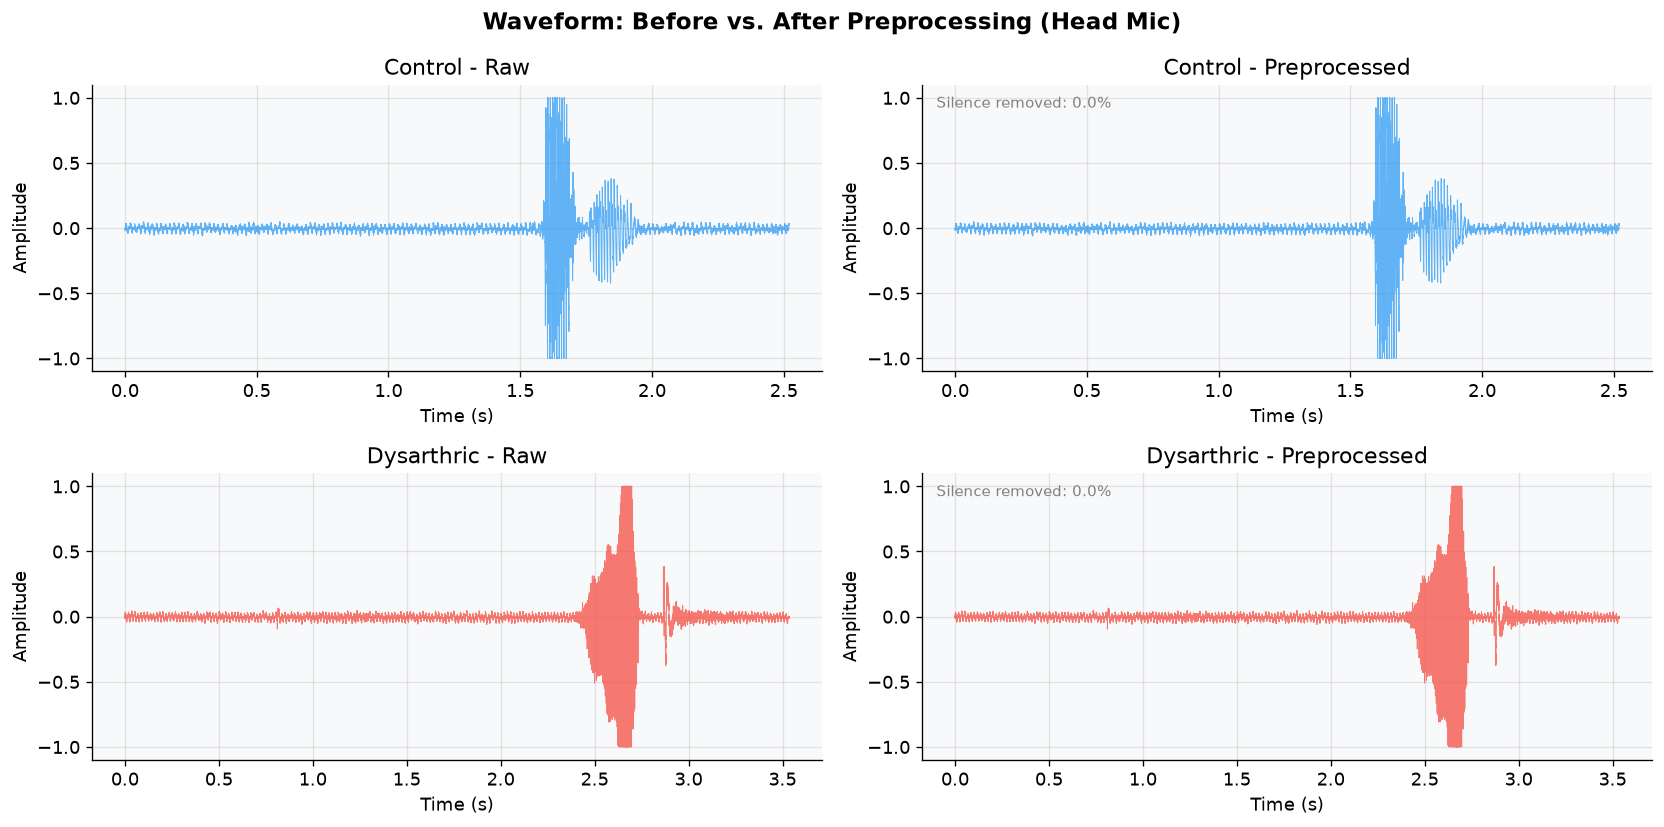

Figure 3 saved.


In [47]:
# ── Figure 3: Waveform before vs. after preprocessing ─────────
# Sample one control + one dysarthric file (head mic)
sample_rows = pd.concat([
    metadata_df[(metadata_df["mic_type"] == "head") & (metadata_df["label"] == 0)].sample(1, random_state=1),
    metadata_df[(metadata_df["mic_type"] == "head") & (metadata_df["label"] == 1)].sample(1, random_state=1),
])

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
fig.suptitle("Waveform: Before vs. After Preprocessing (Head Mic)",
             fontsize=14, fontweight='bold')

for row_idx, (_, row) in enumerate(sample_rows.iterrows()):
    raw, _ = librosa.load(row["file_path"], sr=SAMPLE_RATE)
    proc, _ = preprocess_audio(row["file_path"], row["mic_type"])
    label_name = "Dysarthric" if row["label"] == 1 else "Control"
    color = COLORS['dysarthric'] if row["label"] == 1 else COLORS['control']

    t_raw  = np.linspace(0, len(raw)  / SAMPLE_RATE, len(raw))
    t_proc = np.linspace(0, len(proc) / SAMPLE_RATE, len(proc))

    # Before
    axes[row_idx, 0].plot(t_raw,  raw,  color=color, alpha=0.7, linewidth=0.6)
    axes[row_idx, 0].set_title(f"{label_name} - Raw")
    axes[row_idx, 0].set_ylabel("Amplitude")
    axes[row_idx, 0].set_xlabel("Time (s)")

    # After
    axes[row_idx, 1].plot(t_proc, proc, color=color, alpha=0.7, linewidth=0.6)
    axes[row_idx, 1].set_title(f"{label_name} - Preprocessed")
    axes[row_idx, 1].set_ylabel("Amplitude")
    axes[row_idx, 1].set_xlabel("Time (s)")

    # Annotate duration reduction
    reduction = (1 - len(proc) / len(raw)) * 100
    axes[row_idx, 1].text(0.02, 0.92,
                           f"Silence removed: {reduction:.1f}%",
                           transform=axes[row_idx, 1].transAxes,
                           fontsize=9, color='gray')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig3_waveform_preprocessing.png", bbox_inches='tight', dpi=150)
plt.show()
print("Figure 3 saved.")

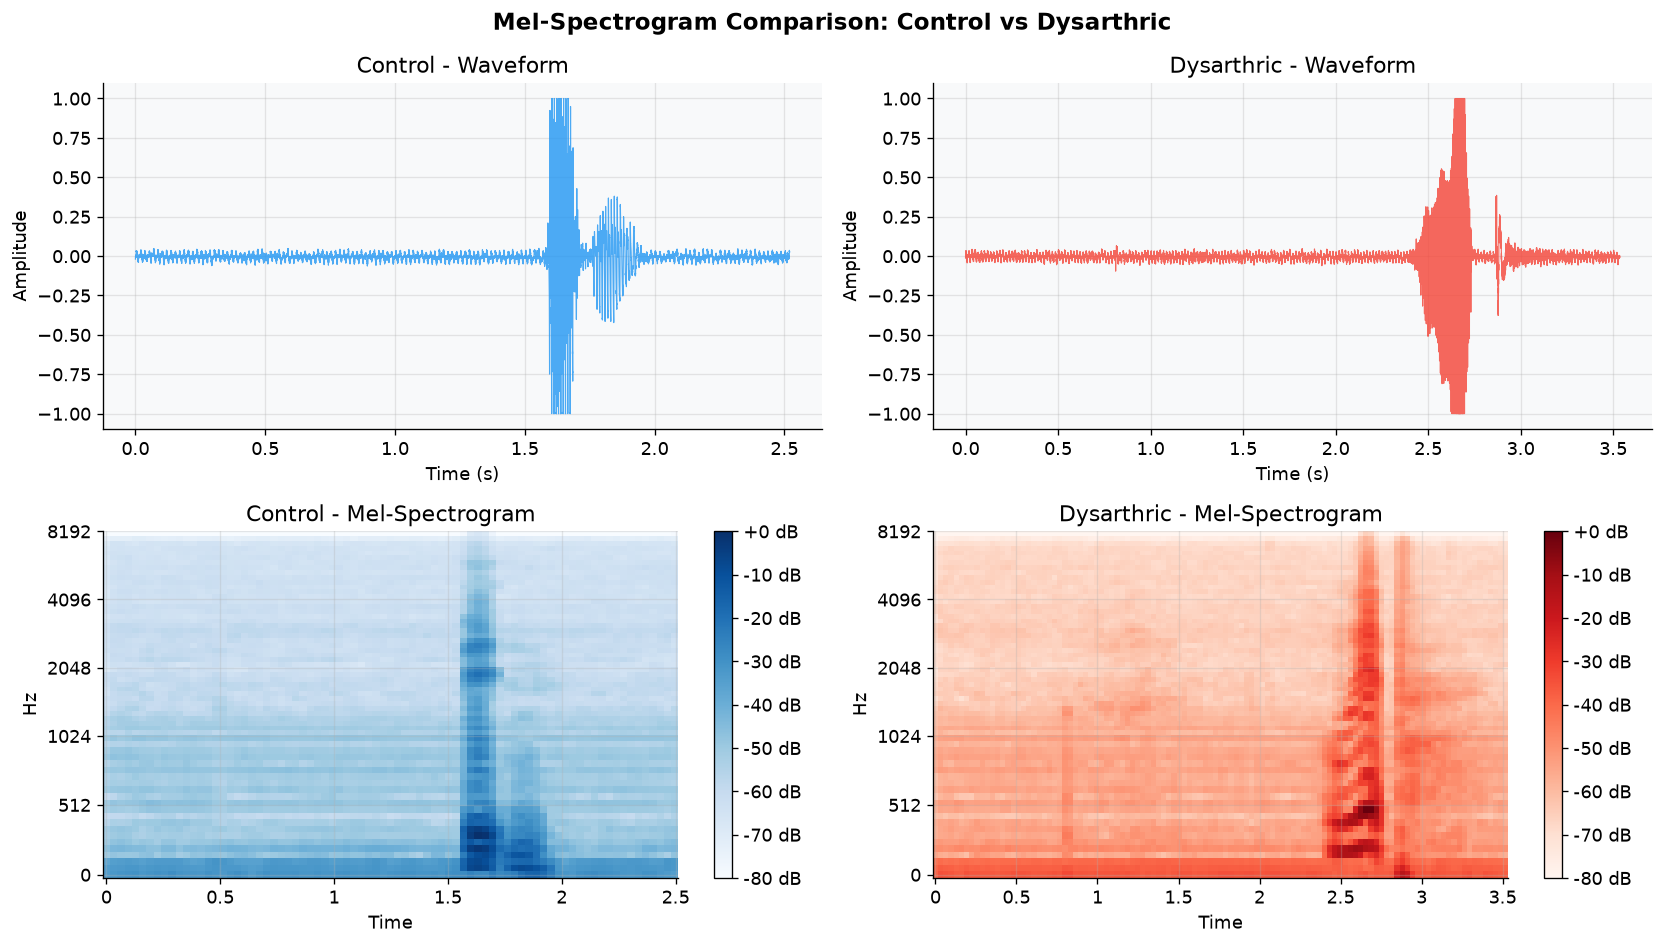

Figure 4 saved.


In [48]:
# ── Figure 4: Spectrogram comparison control vs dysarthric ────
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle("Mel-Spectrogram Comparison: Control vs Dysarthric",
             fontsize=14, fontweight='bold')

for col, (_, row) in enumerate(sample_rows.iterrows()):
    audio, sr = preprocess_audio(row["file_path"], row["mic_type"])
    label_name = "Dysarthric" if row["label"] == 1 else "Control"
    color_map  = "Reds" if row["label"] == 1 else "Blues"

    # Waveform top row
    t = np.linspace(0, len(audio)/sr, len(audio))
    axes[0, col].plot(t, audio,
                      color=COLORS['dysarthric'] if row["label"]==1 else COLORS['control'],
                      linewidth=0.7, alpha=0.8)
    axes[0, col].set_title(f"{label_name} - Waveform")
    axes[0, col].set_xlabel("Time (s)")
    axes[0, col].set_ylabel("Amplitude")

    # Mel-spectrogram bottom row
    mel = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=64)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    img = librosa.display.specshow(mel_db, sr=sr, x_axis='time', y_axis='mel',
                                   ax=axes[1, col], cmap=color_map)
    axes[1, col].set_title(f"{label_name} - Mel-Spectrogram")
    fig.colorbar(img, ax=axes[1, col], format='%+2.0f dB')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig4_spectrograms.png", bbox_inches='tight', dpi=150)
plt.show()
print("Figure 4 saved.")

In [49]:
def extract_logmel(audio, sr=SAMPLE_RATE, n_mels=N_MELS,
                    hop_length=HOP_LENGTH, win_length=WIN_LENGTH,
                    max_frames=MAX_FRAMES):
    '''
    Extract an 80-band log-mel spectrogram for the spectro-temporal stream.

    Args:
        audio: 1-D float32 np.ndarray, preprocessed waveform.
        sr: int, sample rate.
        n_mels: int, number of mel bands.
        hop_length: int, STFT hop length in samples.
        win_length: int, STFT window length in samples.
        max_frames: int, fixed number of time frames to pad/truncate to.

    Returns:
        np.ndarray of shape (n_mels, max_frames), dtype float32, per-utterance
        z-normalised log-mel spectrogram.
    '''
    mel = librosa.feature.melspectrogram(
        y=audio, sr=sr, n_mels=n_mels,
        hop_length=hop_length, win_length=win_length, fmax=8000)
    logmel = librosa.power_to_db(mel, ref=np.max)

    # Per-utterance normalisation (zero mean, unit variance)
    logmel = (logmel - logmel.mean()) / (logmel.std() + 1e-8)

    # Pad or truncate the time axis to a fixed length for batching
    T = logmel.shape[1]
    if T < max_frames:
        logmel = np.pad(logmel, ((0, 0), (0, max_frames - T)), mode='constant')
    else:
        logmel = logmel[:, :max_frames]

    return logmel.astype(np.float32)   # shape: (80, 128)

In [50]:
# =====================================================================
# 4b. Stream 2 — Dynamic Cepstral Trajectory Features
#      ROBUST VERSION: handles very short audio clips safely
# =====================================================================

def _safe_librosa_delta(mfcc, order=1):
    """
    Compute librosa delta features safely for short utterances.

    librosa.feature.delta() requires an odd window width that does not
    exceed the number of available frames when mode='interp'.

    For normal clips:
        width = 9

    For short clips:
        choose the largest valid odd width <= number of frames.

    For extremely short clips (< 3 frames):
        return zeros because even width=3 is impossible.
    """
    n_frames = mfcc.shape[1]

    # Delta needs at least 3 frames for a meaningful derivative.
    if n_frames < 3:
        return np.zeros_like(mfcc, dtype=np.float32)

    # Largest odd number <= n_frames, capped at the normal width of 9.
    width = min(9, n_frames)

    if width % 2 == 0:
        width -= 1

    # Safety guard
    if width < 3:
        return np.zeros_like(mfcc, dtype=np.float32)

    try:
        return librosa.feature.delta(
            mfcc,
            order=order,
            width=width,
            mode="interp"
        ).astype(np.float32)

    except Exception:
        # Very conservative fallback.
        # This should almost never be reached, but prevents one
        # pathological recording from stopping the full extraction.
        return np.zeros_like(mfcc, dtype=np.float32)


def extract_mfcc_trajectory(audio, sr=SAMPLE_RATE, n_mfcc=N_MFCC,
                            hop_length=HOP_LENGTH, win_length=WIN_LENGTH,
                            max_frames=MAX_FRAMES):
    """
    Extract a frame-level 64-dim MFCC-delta trajectory.

    Feature composition:
        13 MFCC
        + 13 delta
        + 13 delta-delta
        + 1 ZCR
        + 1 RMS
        + 23 chroma
        = 64 dimensions

    Robustness:
        Handles very short utterances where librosa's default
        delta width=9 would otherwise fail.
    """

    # -------------------------------------------------------------
    # 1. Base MFCC
    # -------------------------------------------------------------
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=n_mfcc,
        hop_length=hop_length,
        win_length=win_length
    ).astype(np.float32)

    # -------------------------------------------------------------
    # 2. Safe first-order delta
    # -------------------------------------------------------------
    delta = _safe_librosa_delta(mfcc, order=1)

    # -------------------------------------------------------------
    # 3. Safe second-order delta
    # -------------------------------------------------------------
    delta2 = _safe_librosa_delta(mfcc, order=2)

    # -------------------------------------------------------------
    # 4. Zero-crossing rate
    # -------------------------------------------------------------
    zcr = librosa.feature.zero_crossing_rate(
        audio,
        hop_length=hop_length
    ).astype(np.float32)

    # -------------------------------------------------------------
    # 5. RMS energy
    # -------------------------------------------------------------
    rms = librosa.feature.rms(
        y=audio,
        hop_length=hop_length
    ).astype(np.float32)

    # -------------------------------------------------------------
    # 6. Chroma
    # -------------------------------------------------------------
    # 13 + 13 + 13 + 1 + 1 = 41
    # 64 - 41 = 23 chroma dimensions
    n_chroma = TRAJ_DIM - (3 * n_mfcc + 2)

    chroma = librosa.feature.chroma_stft(
        y=audio,
        sr=sr,
        hop_length=hop_length,
        n_chroma=n_chroma
    ).astype(np.float32)

    # -------------------------------------------------------------
    # 7. Align all streams to the same number of frames
    # -------------------------------------------------------------
    min_frames = min(
        mfcc.shape[1],
        delta.shape[1],
        delta2.shape[1],
        zcr.shape[1],
        rms.shape[1],
        chroma.shape[1]
    )

    if min_frames < 1:
        raise ValueError("No usable frames were produced from this audio clip.")

    mfcc   = mfcc[:, :min_frames]
    delta  = delta[:, :min_frames]
    delta2 = delta2[:, :min_frames]
    zcr    = zcr[:, :min_frames]
    rms    = rms[:, :min_frames]
    chroma = chroma[:, :min_frames]

    # -------------------------------------------------------------
    # 8. Stack into 64-dimensional trajectory
    # -------------------------------------------------------------
    traj = np.vstack([
        mfcc,
        delta,
        delta2,
        zcr,
        rms,
        chroma
    ]).T

    # -------------------------------------------------------------
    # 9. Per-utterance normalization
    # -------------------------------------------------------------
    mean = traj.mean(axis=0)
    std = traj.std(axis=0)

    traj = (traj - mean) / (std + 1e-8)

    # Remove any numerical problems just in case
    traj = np.nan_to_num(
        traj,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    # -------------------------------------------------------------
    # 10. Pad / truncate to MAX_FRAMES
    # -------------------------------------------------------------
    T = traj.shape[0]

    if T < max_frames:
        traj = np.vstack([
            traj,
            np.zeros(
                (max_frames - T, traj.shape[1]),
                dtype=np.float32
            )
        ])
    else:
        traj = traj[:max_frames, :]

    # Final dimension check
    if traj.shape != (max_frames, TRAJ_DIM):
        raise ValueError(
            f"Unexpected trajectory shape: {traj.shape}; "
            f"expected {(max_frames, TRAJ_DIM)}"
        )

    return traj.astype(np.float32)

In [51]:
def compute_valid_frames(audio, hop_length=HOP_LENGTH, max_frames=MAX_FRAMES):
    '''
    Number of real (non-padding) STFT frames librosa would produce for this
    audio under the center=True convention, capped to max_frames. Used later
    for masked pooling so that zero-padding introduced by extract_logmel /
    extract_mfcc_trajectory does not bias the pooled encoder representation.

    Args:
        audio: 1-D np.ndarray, waveform.
        hop_length: int, STFT hop length in samples.
        max_frames: int, the fixed sequence length features are padded/truncated to.

    Returns:
        int, number of valid (non-padded) frames, in [1, max_frames].
    '''
    n_frames = 1 + len(audio) // hop_length
    return int(max(1, min(n_frames, max_frames)))

In [52]:
# =====================================================================
# 4c. Incremental dual-stream extraction
# =====================================================================
def extract_dual_stream_features(
    metadata_df, sr=SAMPLE_RATE, cache_path=None, force_recompute=False
):
    """
    Incremental feature extraction.

    Each successfully processed WAV is written to its own shard immediately.
    Therefore a kernel crash, disconnect, or later coding error never forces
    already-finished audio files to be reprocessed.

    The aggregate .npz is only marked complete when every input file succeeded.
    Incomplete aggregates are rebuilt from the per-file shards on the next run.
    """
    cache_path = cache_path or os.path.join(CACHE_DIR, "dual_stream_features.npz")
    source_signature = dataframe_signature(
        metadata_df,
        ["file_path", "mic_type", "label", "speaker_id", "gender"]
    )
    manifest_path = cache_path + ".manifest.json"

    if (
        (not force_recompute)
        and os.path.exists(cache_path)
        and os.path.exists(manifest_path)
    ):
        try:
            with open(manifest_path, "r", encoding="utf-8") as f:
                manifest = json.load(f)
            if (
                manifest.get("pipeline_signature") == PIPELINE_SIGNATURE
                and manifest.get("source_signature") == source_signature
                and manifest.get("complete") is True
            ):
                cached = np.load(cache_path, allow_pickle=True)
                meta_cached = pd.DataFrame(
                    cached["meta_values"],
                    columns=cached["meta_columns"].tolist()
                )
                if "label" in meta_cached:
                    meta_cached["label"] = meta_cached["label"].astype(int)
                if "valid_frames" in meta_cached:
                    meta_cached["valid_frames"] = meta_cached["valid_frames"].astype(int)
                print(f"[CACHE] Loaded complete dual-stream aggregate: {cache_path}")
                return (
                    cached["logmels"].astype(np.float32),
                    cached["trajs"].astype(np.float32),
                    meta_cached.reset_index(drop=True),
                )
        except Exception as e:
            print("[CACHE] Aggregate cache could not be trusted; rebuilding from shards:", e)

    logmel_list = []
    traj_list = []
    meta_rows = []
    n_cached = 0
    n_new = 0
    n_errors = 0

    for _, row in tqdm(
        metadata_df.iterrows(),
        total=len(metadata_df),
        desc="Dual-stream extraction / cache"
    ):
        extra = {
            "sr": sr,
            "n_mels": N_MELS,
            "n_mfcc": N_MFCC,
            "hop_length": HOP_LENGTH,
            "win_length": WIN_LENGTH,
            "max_frames": MAX_FRAMES,
            "traj_dim": TRAJ_DIM,
        }
        key = file_cache_key(row["file_path"], "dual_stream", extra)
        shard_path = os.path.join(DUAL_SHARD_DIR, f"{key}.npz")

        try:
            if os.path.exists(shard_path) and not force_recompute:
                shard = np.load(shard_path, allow_pickle=True)
                logmel = shard["logmel"].astype(np.float32)
                traj = shard["traj"].astype(np.float32)
                valid_frames = int(shard["valid_frames"])
                n_cached += 1
            else:
                audio, _ = preprocess_audio(
                    row["file_path"], row["mic_type"], sr=sr
                )
                logmel = extract_logmel(audio, sr=sr)
                traj = extract_mfcc_trajectory(audio, sr=sr)
                valid_frames = compute_valid_frames(audio)

                if not (np.isfinite(logmel).all() and np.isfinite(traj).all()):
                    raise ValueError("non-finite values in extracted features")

                atomic_npz_save(
                    shard_path,
                    logmel=logmel.astype(np.float32),
                    traj=traj.astype(np.float32),
                    valid_frames=np.asarray(valid_frames, dtype=np.int64),
                )
                n_new += 1

            logmel_list.append(logmel)
            traj_list.append(traj)
            meta_rows.append({
                "file_path": row["file_path"],
                "label": int(row["label"]),
                "speaker_id": row["speaker_id"],
                "gender": row["gender"],
                "mic_type": row["mic_type"],
                "valid_frames": valid_frames,
            })

        except Exception as e:
            n_errors += 1
            print(f"  [WARN] Could not process {row['file_path']}: {e}")

    if not logmel_list:
        raise RuntimeError(
            "No dual-stream features were produced. Fix the preprocessing/data issue and rerun."
        )

    logmels = np.stack(logmel_list).astype(np.float32)
    trajs = np.stack(traj_list).astype(np.float32)
    meta_out = pd.DataFrame(meta_rows).reset_index(drop=True)

    complete = (n_errors == 0 and len(meta_out) == len(metadata_df))

    # The aggregate is always saved, but it is only considered reusable when complete.
    atomic_npz_save(
        cache_path,
        logmels=logmels,
        trajs=trajs,
        meta_values=meta_out.values,
        meta_columns=np.asarray(meta_out.columns),
    )
    atomic_json_dump(
        {
            "pipeline_signature": PIPELINE_SIGNATURE,
            "source_signature": source_signature,
            "complete": complete,
            "n_input": int(len(metadata_df)),
            "n_output": int(len(meta_out)),
            "n_cached_shards_used": int(n_cached),
            "n_new_shards_created": int(n_new),
            "n_errors": int(n_errors),
        },
        manifest_path,
    )

    print(
        f"Dual-stream features ready: {len(meta_out)}/{len(metadata_df)} files; "
        f"cached={n_cached}, newly processed={n_new}, errors={n_errors}."
    )
    if n_errors:
        raise RuntimeError(
            f"{n_errors} audio file(s) could not be processed. "
            "Successful files are already cached individually. Fix the reported issue "
            "and rerun the notebook; V4 will skip completed files and retry only failures."
        )
    return logmels, trajs, meta_out

# Public cache variables retained for compatibility with the original V3 code.
DUAL_FEATURE_MANIFEST_PATH = FEATURE_CACHE_PATH + ".manifest.json"


In [53]:
# =====================================================================
# 4c.5 — Register permanently unreadable audio files
# =====================================================================

KNOWN_BAD_AUDIO_RELATIVE = {
    os.path.join("F_Dys", "wav_headMic_F01", "wav_headMic_F01_0067.wav"),
    os.path.join("F_Dys", "wav_headMic_F01", "wav_headMic_F01_0068.wav"),
}

# Resolve relative to the actual dataset root so this works on both Kaggle and macOS.
KNOWN_BAD_AUDIO_FILES = {
    os.path.abspath(os.path.join(DATASET_PATH, rel_path))
    for rel_path in KNOWN_BAD_AUDIO_RELATIVE
}

BAD_AUDIO_MANIFEST = os.path.join(STAGE_DIR, "known_bad_audio_files.json")

bad_audio_info = {
    "complete": True,
    "count": len(KNOWN_BAD_AUDIO_FILES),
    "files": sorted(KNOWN_BAD_AUDIO_FILES),
    "relative_files": sorted(KNOWN_BAD_AUDIO_RELATIVE),
    "reason": (
        "Audio files are present in the TORGO dataset but cannot be decoded "
        "by soundfile/librosa/audioread and raise EOFError/Format not recognised."
    ),
}

atomic_json_dump(bad_audio_info, BAD_AUDIO_MANIFEST)

print("=" * 80)
print("KNOWN UNREADABLE AUDIO FILES")
print("=" * 80)
for p in sorted(KNOWN_BAD_AUDIO_FILES):
    print("-", p)
print(f"\nRegistered bad files: {len(KNOWN_BAD_AUDIO_FILES)}")
print("These files will be excluded from feature extraction.")
print("All successfully cached files remain untouched.")


KNOWN UNREADABLE AUDIO FILES
- /Users/Noor/.cache/kagglehub/datasets/pranaykoppula/torgo-audio/versions/1/F_Dys/wav_headMic_F01/wav_headMic_F01_0067.wav
- /Users/Noor/.cache/kagglehub/datasets/pranaykoppula/torgo-audio/versions/1/F_Dys/wav_headMic_F01/wav_headMic_F01_0068.wav

Registered bad files: 2
These files will be excluded from feature extraction.
All successfully cached files remain untouched.


In [54]:
# =====================================================================
# 4d. Run incremental extraction — exclude known unreadable files
# =====================================================================

metadata_df_extraction = metadata_df[
    ~metadata_df["file_path"].isin(KNOWN_BAD_AUDIO_FILES)
].copy().reset_index(drop=True)

print("=" * 80)
print("INCREMENTAL DUAL-STREAM EXTRACTION")
print("=" * 80)
print(f"Original files          : {len(metadata_df)}")
print(f"Known unreadable files  : {len(KNOWN_BAD_AUDIO_FILES)}")
print(f"Files being processed   : {len(metadata_df_extraction)}")
print()

logmels, trajs, meta = extract_dual_stream_features(
    metadata_df_extraction,
    sr=SAMPLE_RATE,
    cache_path=FEATURE_CACHE_PATH,
)

print()
print("=" * 80)
print("DUAL-STREAM EXTRACTION COMPLETE")
print("=" * 80)
print(f"Usable audio files      : {len(meta)}")
print(f"Excluded unreadable     : {len(KNOWN_BAD_AUDIO_FILES)}")
print(f"Original dataset files  : {len(metadata_df)}")


INCREMENTAL DUAL-STREAM EXTRACTION
Original files          : 17633
Known unreadable files  : 2
Files being processed   : 17631

[CACHE] Loaded complete dual-stream aggregate: /Users/Noor/dysarthria-v4/cache/dysarthria_detection_v4/run_e1eb4e70a21d7fc1/dual_stream_features.npz

DUAL-STREAM EXTRACTION COMPLETE
Usable audio files      : 17631
Excluded unreadable     : 2
Original dataset files  : 17633


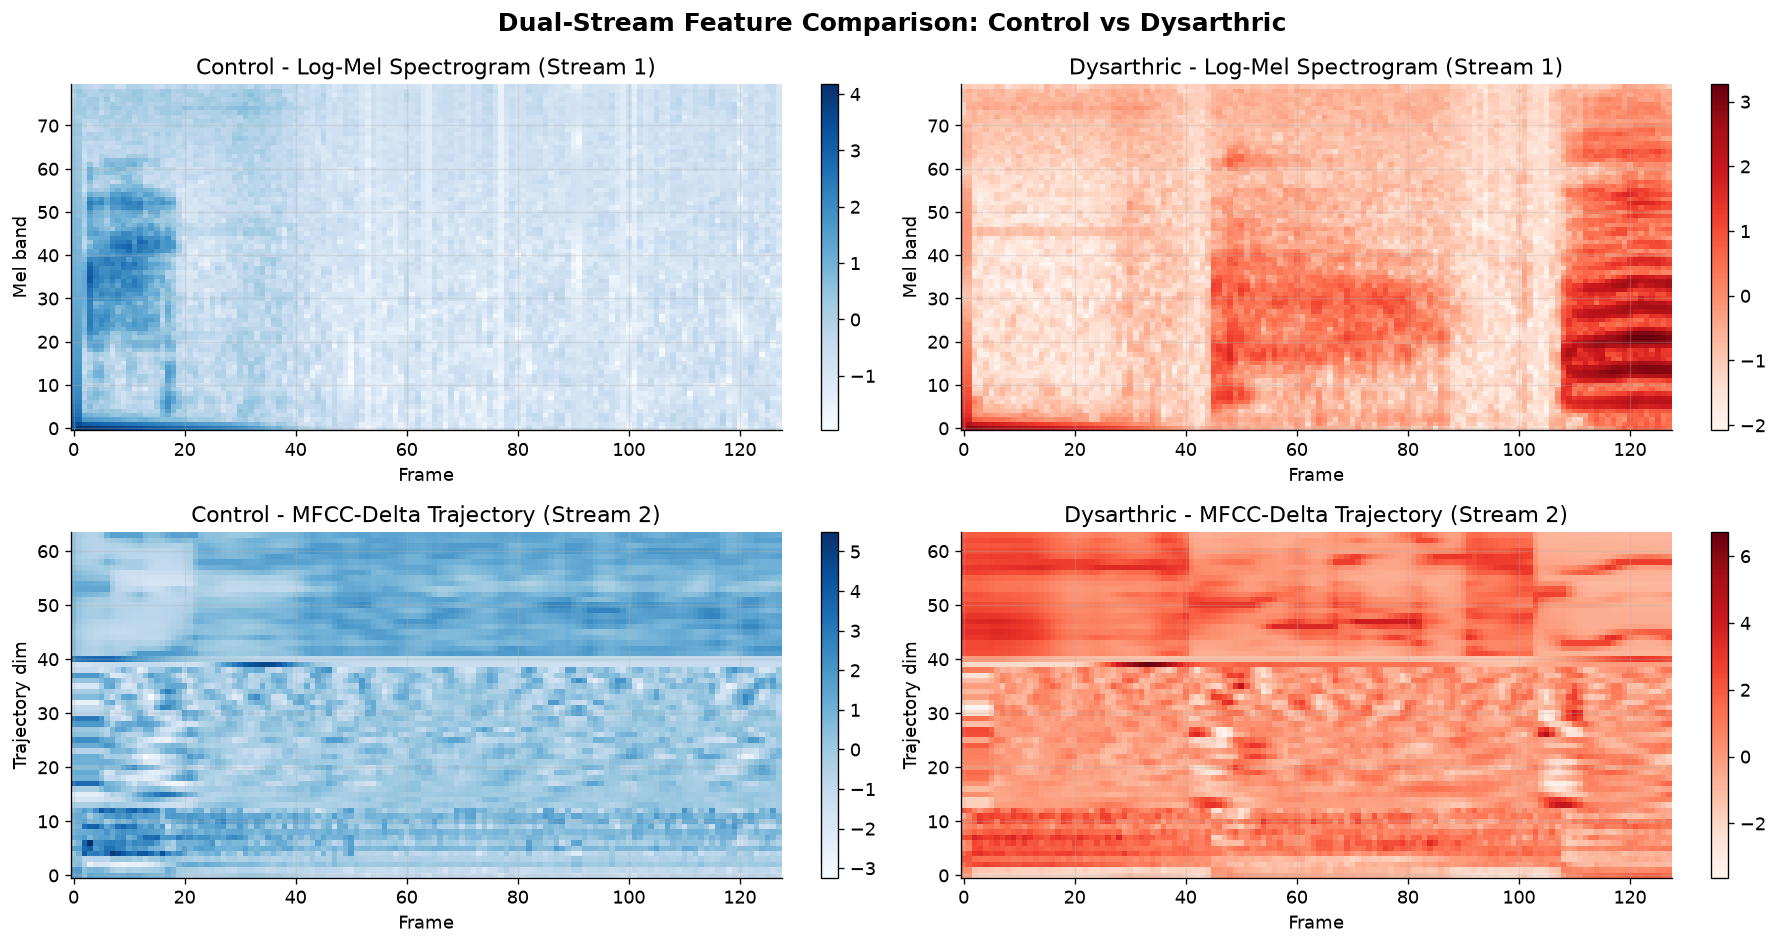

Figure 5 saved.


In [55]:
# ── Figure 5: side-by-side visualisation of both feature streams ─────────────
# One control vs one dysarthric utterance
ctrl_idx = meta[meta["label"] == 0].index[0]
dys_idx  = meta[meta["label"] == 1].index[0]

fig, axes = plt.subplots(2, 2, figsize=(15, 8))
fig.suptitle("Dual-Stream Feature Comparison: Control vs Dysarthric", fontsize=15, fontweight='bold')

for col, (idx, label_name, cmap) in enumerate([
        (ctrl_idx, "Control", "Blues"), (dys_idx, "Dysarthric", "Reds")]):
    im0 = axes[0, col].imshow(logmels[idx], aspect='auto', origin='lower', cmap=cmap)
    axes[0, col].set_title(f"{label_name} - Log-Mel Spectrogram (Stream 1)")
    axes[0, col].set_xlabel("Frame")
    axes[0, col].set_ylabel("Mel band")
    fig.colorbar(im0, ax=axes[0, col], fraction=0.046)

    im1 = axes[1, col].imshow(trajs[idx].T, aspect='auto', origin='lower', cmap=cmap)
    axes[1, col].set_title(f"{label_name} - MFCC-Delta Trajectory (Stream 2)")
    axes[1, col].set_xlabel("Frame")
    axes[1, col].set_ylabel("Trajectory dim")
    fig.colorbar(im1, ax=axes[1, col], fraction=0.046)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig5_dual_stream_features.png", bbox_inches='tight', dpi=150)
plt.show()
print("Figure 5 saved.")

In [56]:
# =====================================================================
# 5. Speaker-independent split (cached)
# =====================================================================
def make_speaker_independent_split(
    metadata_df, train_ratio=TRAIN_RATIO, val_ratio=VAL_RATIO, seed=SEED
):
    test_ratio = 1.0 - train_ratio - val_ratio
    rng = np.random.RandomState(seed)

    speaker_info = (
        metadata_df.groupby("speaker_id")
        .agg(label=("label", "first"), gender=("gender", "first"))
        .reset_index()
    )

    split_map = {}
    for label_value, group in speaker_info.groupby("label"):
        spk_ids = group["speaker_id"].to_numpy().copy()
        rng.shuffle(spk_ids)
        n = len(spk_ids)

        n_test = max(1, int(round(n * test_ratio))) if n >= 3 else (1 if n >= 2 else 0)
        n_val = max(1, int(round(n * val_ratio))) if n >= 3 else (1 if n >= 3 else 0)
        n_train = n - n_val - n_test

        if n_train < 1:
            n_train = 1
            remaining = n - n_train
            n_test = max(0, remaining // 2 + remaining % 2)
            n_val = remaining - n_test

        for s in spk_ids[:n_train]:
            split_map[s] = "train"
        for s in spk_ids[n_train:n_train + n_val]:
            split_map[s] = "val"
        for s in spk_ids[n_train + n_val:]:
            split_map[s] = "test"

    speaker_info["split"] = speaker_info["speaker_id"].map(split_map)
    return (
        split_map,
        speaker_info.sort_values(["split", "label", "speaker_id"]).reset_index(drop=True)
    )

split_signature = dataframe_signature(
    meta, ["file_path", "speaker_id", "gender", "label", "mic_type", "valid_frames"]
)
split_cache_obj = None
if os.path.exists(SPLIT_CACHE_PATH):
    try:
        split_cache_obj = pickle.load(open(SPLIT_CACHE_PATH, "rb"))
    except Exception:
        split_cache_obj = None

if (
    split_cache_obj
    and split_cache_obj.get("pipeline_signature") == PIPELINE_SIGNATURE
    and split_cache_obj.get("source_signature") == split_signature
):
    split_map = split_cache_obj["split_map"]
    split_table = split_cache_obj["split_table"]
    print("[CACHE] Loaded speaker-independent split.")
else:
    split_map, split_table = make_speaker_independent_split(meta)
    atomic_pickle_dump(
        {
            "pipeline_signature": PIPELINE_SIGNATURE,
            "source_signature": split_signature,
            "split_map": split_map,
            "split_table": split_table,
        },
        SPLIT_CACHE_PATH,
    )
    print("[CACHE] Created and saved speaker-independent split.")

meta["split"] = meta["speaker_id"].map(split_map)

train_idx = meta.index[meta["split"] == "train"].to_numpy()
val_idx = meta.index[meta["split"] == "val"].to_numpy()
test_idx = meta.index[meta["split"] == "test"].to_numpy()

print(f"Utterances -> train: {len(train_idx)}, val: {len(val_idx)}, test: {len(test_idx)}")

train_speakers = set(meta.loc[train_idx, "speaker_id"])
val_speakers = set(meta.loc[val_idx, "speaker_id"])
test_speakers = set(meta.loc[test_idx, "speaker_id"])

assert train_speakers.isdisjoint(val_speakers), "Speaker leakage between train/val!"
assert train_speakers.isdisjoint(test_speakers), "Speaker leakage between train/test!"
assert val_speakers.isdisjoint(test_speakers), "Speaker leakage between val/test!"
print("Verified: train/val/test speaker sets are pairwise disjoint.")


[CACHE] Loaded speaker-independent split.
Utterances -> train: 13199, val: 2004, test: 2428
Verified: train/val/test speaker sets are pairwise disjoint.


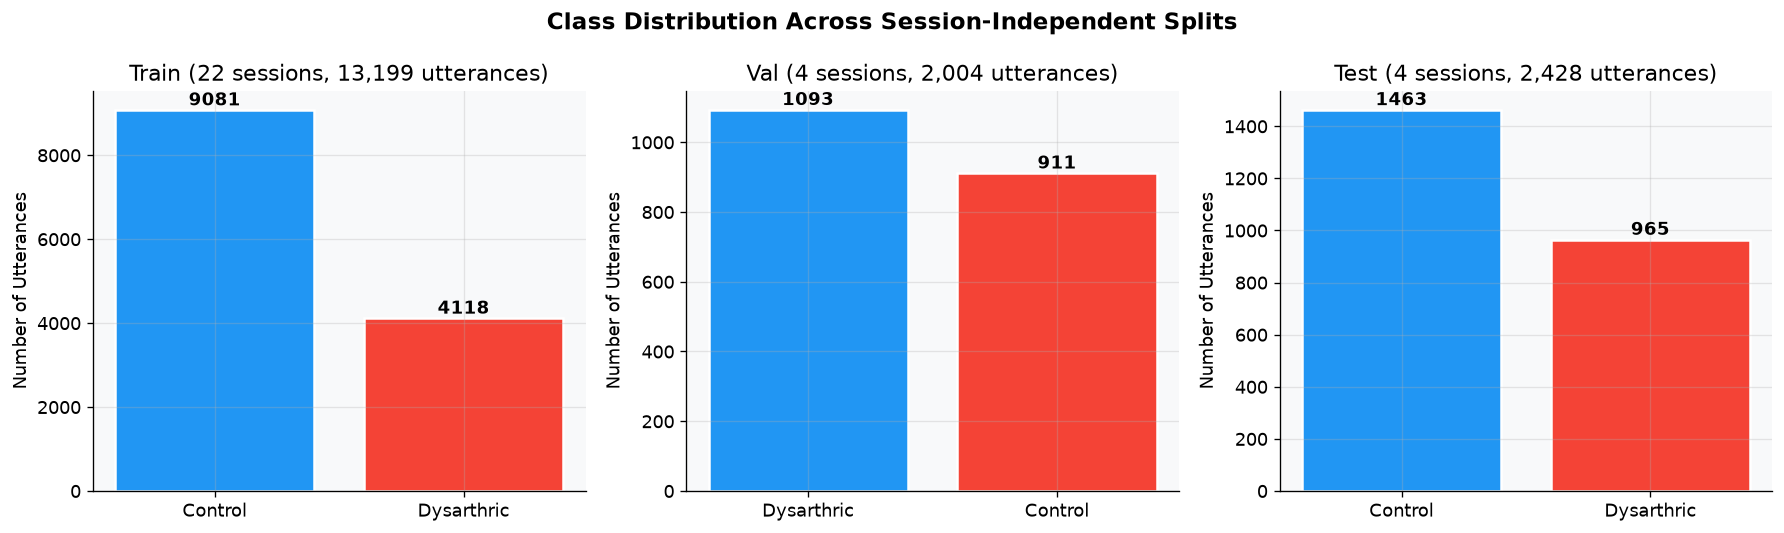

Figure 6 saved.


In [57]:
# ── Figure 6: class distribution across splits, confirming no leakage ────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
fig.suptitle("Class Distribution Across Session-Independent Splits", fontsize=14, fontweight='bold')

for ax, split_name in zip(axes, ["train", "val", "test"]):
    sub = meta[meta["split"] == split_name]
    counts = sub["label"].map(LABEL_MAP).value_counts()
    bars = ax.bar(counts.index, counts.values,
                  color=[COLORS['control'], COLORS['dysarthric']], edgecolor='white', linewidth=1.5)
    n_sess = sub["speaker_id"].nunique()
    ax.set_title(f"{split_name.capitalize()} ({n_sess} sessions, {len(sub):,} utterances)")
    ax.set_ylabel("Number of Utterances")
    for bar, val in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                str(val), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig6_split_class_distribution.png", bbox_inches='tight', dpi=150)
plt.show()
print("Figure 6 saved.")

In [58]:
class SpeechAugmenter:
    '''
    Waveform-level augmentation: additive noise + pitch shift.
    Applied directly to raw audio, upstream of feature extraction. Used when
    building an augmented on-disk cache, or for offline data expansion.
    '''
    def __init__(self, snr_db_range=(10, 30), pitch_semitone_range=(-2, 2), noise_prob=0.7,
                 pitch_prob=0.5, seed=None):
        self.snr_db_range = snr_db_range
        self.pitch_semitone_range = pitch_semitone_range
        self.noise_prob = noise_prob
        self.pitch_prob = pitch_prob
        self.rng = np.random.RandomState(seed)

    def __call__(self, audio, sr=SAMPLE_RATE):
        '''
        Args:
            audio: 1-D float32 np.ndarray, waveform.
            sr: int, sample rate.
        Returns:
            1-D float32 np.ndarray, augmented waveform (same length as input).
        '''
        if self.rng.rand() < self.noise_prob:
            snr_db = self.rng.uniform(*self.snr_db_range)
            audio = self._add_noise(audio, snr_db)
        if self.rng.rand() < self.pitch_prob:
            semitones = self.rng.uniform(*self.pitch_semitone_range)
            audio = self._pitch_shift(audio, sr, semitones)
        return audio.astype(np.float32)

    def _add_noise(self, audio, snr_db):
        '''Additive Gaussian noise at the given SNR (dB).'''
        signal_power = np.mean(audio ** 2) + 1e-12
        noise_power = signal_power / (10 ** (snr_db / 10))
        noise = self.rng.normal(0, np.sqrt(noise_power), size=len(audio))
        return audio + noise

    def _pitch_shift(self, audio, sr, semitones):
        '''Pitch shift by a random amount within +/- 2 semitones.'''
        return librosa.effects.pitch_shift(y=audio, sr=sr, n_steps=semitones)


def spec_augment(logmel, freq_mask_param=15, time_mask_param=20, num_masks=2, rng=None):
    '''
    SpecAugment: random frequency and time masking applied to a log-mel spectrogram.

    Args:
        logmel: np.ndarray, shape (n_mels, T).
        freq_mask_param: int, max width of each frequency mask.
        time_mask_param: int, max width of each time mask.
        num_masks: int, number of masks applied per axis.
        rng: optional np.random.RandomState for reproducibility.

    Returns:
        np.ndarray, same shape as input, with masked regions set to the
        per-utterance mean value (i.e. "erased").
    '''
    rng = rng or np.random
    aug = logmel.copy()
    n_mels, n_frames = aug.shape
    fill_value = aug.mean()

    for _ in range(num_masks):
        f = int(rng.uniform(0, freq_mask_param))
        f0 = int(rng.uniform(0, max(1, n_mels - f)))
        aug[f0:f0 + f, :] = fill_value

    for _ in range(num_masks):
        t = int(rng.uniform(0, time_mask_param))
        t0 = int(rng.uniform(0, max(1, n_frames - t)))
        aug[:, t0:t0 + t] = fill_value

    return aug.astype(np.float32)


def feature_jitter(traj, sigma=0.01, rng=None):
    '''
    Additive Gaussian jitter on the MFCC-delta trajectory features.

    Args:
        traj: np.ndarray, shape (T, 64).
        sigma: float, standard deviation of the jitter noise.
        rng: optional np.random.RandomState for reproducibility.

    Returns:
        np.ndarray, same shape as input, dtype float32.
    '''
    rng = rng or np.random
    noise = rng.normal(0, sigma, size=traj.shape)
    return (traj + noise).astype(np.float32)

In [59]:
GENDER_TO_LABEL = {"female": 0, "male": 1, "unknown": 0}


class TORGODualStreamDataset(Dataset):
    '''
    Supervised-phase dataset: serves precomputed dual-stream features for one split.

    Returns per item:
        logmel      : torch.FloatTensor, shape (1, 80, 128)
        traj        : torch.FloatTensor, shape (128, 64)
        length      : torch.LongTensor scalar, number of valid (non-padded) frames,
                       used by the encoders for masked pooling
        label       : torch.LongTensor scalar, 0=control, 1=dysarthric
        gender_label: torch.LongTensor scalar, 0=female, 1=male
    '''
    def __init__(self, logmels, trajs, labels, genders, lengths=None, augment=False, rng_seed=SEED):
        assert len(logmels) == len(trajs) == len(labels) == len(genders)
        self.logmels = logmels.astype(np.float32)
        self.trajs = trajs.astype(np.float32)
        self.labels = np.asarray(labels, dtype=np.int64)
        self.genders = np.array([GENDER_TO_LABEL.get(g, 0) for g in genders], dtype=np.int64)
        self.lengths = (np.asarray(lengths, dtype=np.int64) if lengths is not None
                         else np.full(len(labels), MAX_FRAMES, dtype=np.int64))
        self.augment = augment
        self.rng = np.random.RandomState(rng_seed)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        logmel = self.logmels[idx]
        traj = self.trajs[idx]

        if self.augment:
            if self.rng.rand() < 0.5:
                logmel = spec_augment(logmel, rng=self.rng)
            if self.rng.rand() < 0.5:
                traj = feature_jitter(traj, rng=self.rng)

        logmel_t = torch.from_numpy(logmel.astype(np.float32)).unsqueeze(0)   # (1, 80, 128)
        traj_t = torch.from_numpy(traj.astype(np.float32))                    # (128, 64)
        length_t = torch.tensor(int(self.lengths[idx]), dtype=torch.long)
        label_t = torch.tensor(self.labels[idx], dtype=torch.long)
        gender_t = torch.tensor(self.genders[idx], dtype=torch.long)
        return logmel_t, traj_t, length_t, label_t, gender_t

    def get_batch(self, indices):
        """Assemble one batch without per-sample tensor stacking."""
        indices = np.asarray(indices, dtype=np.int64)
        logmels = self.logmels[indices].copy()
        trajs = self.trajs[indices].copy()
        if self.augment:
            for batch_i in range(len(indices)):
                if self.rng.rand() < 0.5:
                    logmels[batch_i] = spec_augment(logmels[batch_i], rng=self.rng)
                if self.rng.rand() < 0.5:
                    trajs[batch_i] = feature_jitter(trajs[batch_i], rng=self.rng)
        return (
            torch.from_numpy(logmels).unsqueeze(1),
            torch.from_numpy(trajs),
            torch.from_numpy(self.lengths[indices].copy()),
            torch.from_numpy(self.labels[indices].copy()),
            torch.from_numpy(self.genders[indices].copy()),
        )

In [60]:
class ContrastivePretrainDataset(Dataset):
    """Two augmented views of the same utterance plus its class label.

    V3 uses the label only in the training split to enable supervised contrastive
    learning. No validation/test labels are used for representation pretraining.
    """
    def __init__(self, logmels, trajs, labels, lengths=None, rng_seed=SEED):
        self.logmels = logmels.astype(np.float32)
        self.trajs = trajs.astype(np.float32)
        self.labels = np.asarray(labels, dtype=np.int64)
        self.lengths = (np.asarray(lengths, dtype=np.int64) if lengths is not None
                        else np.full(len(logmels), MAX_FRAMES, dtype=np.int64))
        self.rng = np.random.RandomState(rng_seed)

    def __len__(self):
        return len(self.logmels)

    def _augment_view_arrays(self, logmel, traj):
        logmel_v = spec_augment(logmel, rng=self.rng) if self.rng.rand() < 0.8 else logmel.copy()
        traj_v = feature_jitter(traj, rng=self.rng) if self.rng.rand() < 0.8 else traj.copy()
        # Mild channel-style feature perturbation improves invariance without changing labels.
        if self.rng.rand() < 0.35:
            gain = self.rng.uniform(0.90, 1.10)
            logmel_v = logmel_v * gain
        return logmel_v.astype(np.float32), traj_v.astype(np.float32)

    def _augment_view(self, logmel, traj, length):
        logmel_v, traj_v = self._augment_view_arrays(logmel, traj)
        logmel_t = torch.from_numpy(logmel_v).unsqueeze(0)
        traj_t = torch.from_numpy(traj_v.astype(np.float32))
        length_t = torch.tensor(int(length), dtype=torch.long)
        return logmel_t, traj_t, length_t

    def __getitem__(self, idx):
        logmel = self.logmels[idx]
        traj = self.trajs[idx]
        length = self.lengths[idx]
        view1 = self._augment_view(logmel, traj, length)
        view2 = self._augment_view(logmel, traj, length)
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return view1, view2, label

    def get_batch(self, indices):
        """Create contiguous augmented tensors for one batch."""
        indices = np.asarray(indices, dtype=np.int64)
        batch_size = len(indices)
        logmel1 = np.empty((batch_size, 1, N_MELS, MAX_FRAMES), dtype=np.float32)
        traj1 = np.empty((batch_size, MAX_FRAMES, TRAJ_DIM), dtype=np.float32)
        logmel2 = np.empty_like(logmel1)
        traj2 = np.empty_like(traj1)
        for batch_i, idx in enumerate(indices):
            lm1, tj1 = self._augment_view_arrays(self.logmels[idx], self.trajs[idx])
            lm2, tj2 = self._augment_view_arrays(self.logmels[idx], self.trajs[idx])
            logmel1[batch_i, 0], traj1[batch_i] = lm1, tj1
            logmel2[batch_i, 0], traj2[batch_i] = lm2, tj2
        lengths = torch.from_numpy(self.lengths[indices].copy())
        return (
            torch.from_numpy(logmel1), torch.from_numpy(traj1), lengths,
            torch.from_numpy(logmel2), torch.from_numpy(traj2), lengths.clone(),
            torch.from_numpy(self.labels[indices].copy()),
        )


In [61]:
# ── Instantiate datasets & loaders for the three splits ───────
train_dataset = TORGODualStreamDataset(
    logmels[train_idx], trajs[train_idx],
    meta.loc[train_idx, "label"].values, meta.loc[train_idx, "gender"].values,
    lengths=meta.loc[train_idx, "valid_frames"].values, augment=True)
val_dataset = TORGODualStreamDataset(
    logmels[val_idx], trajs[val_idx], meta.loc[val_idx, "label"].values,
    meta.loc[val_idx, "gender"].values, lengths=meta.loc[val_idx, "valid_frames"].values, augment=False)
test_dataset = TORGODualStreamDataset(
    logmels[test_idx], trajs[test_idx], meta.loc[test_idx, "label"].values,
    meta.loc[test_idx, "gender"].values, lengths=meta.loc[test_idx, "valid_frames"].values, augment=False)

pretrain_dataset = ContrastivePretrainDataset(
    logmels[train_idx], trajs[train_idx], meta.loc[train_idx, "label"].values,
    lengths=meta.loc[train_idx, "valid_frames"].values)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
pretrain_loader = DataLoader(pretrain_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)

print(f"Train batches: {len(train_loader)}, Val batches: {len(val_loader)}, "
      f"Test batches: {len(test_loader)}, Pretrain batches: {len(pretrain_loader)}")


Train batches: 824, Val batches: 126, Test batches: 152, Pretrain batches: 824


In [62]:
class SpectroTemporalEncoder(nn.Module):
    '''
    Input : (B, 1, 80, 128) log-mel spectrogram, optional lengths (B,) giving the
             number of valid (non-padded) frames in the original 128-frame axis.
    Output: (B, 256) spectro-temporal embedding.

    Architecture:
        3x Conv2d blocks (32 -> 64 -> 128 channels), each BatchNorm2d + ReLU,
        the first two followed by MaxPool2d(2, 2) (halves both freq and time twice, i.e. /4 total),
        AdaptiveAvgPool2d((1, None)) to collapse the frequency axis to 1 while keeping time,
        a 2-layer bidirectional LSTM over the resulting time axis,
        and masked mean pooling over time using the (downsampled) valid length.
    '''
    TIME_DOWNSAMPLE = 4   # two MaxPool2d(2, 2) layers -> time axis divided by 4

    def __init__(self, embed_dim=EMBED_DIM):
        super().__init__()
        self.conv_block = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, None))
        )
        self.bilstm = nn.LSTM(input_size=128, hidden_size=128,
                               num_layers=2, batch_first=True,
                               bidirectional=True, dropout=0.3)
        self.proj = nn.Linear(256, embed_dim)
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x, lengths=None):
        # x: (B, 1, 80, 128)
        feat = self.conv_block(x)             # (B, 128, 1, T')
        feat = feat.squeeze(2).transpose(1, 2)  # (B, T', 128)

        lstm_out, _ = self.bilstm(feat)        # (B, T', 256)
        T_prime = lstm_out.size(1)

        if lengths is not None:
            reduced_len = torch.clamp(
                (lengths.float() / self.TIME_DOWNSAMPLE).ceil().long(), min=1, max=T_prime)
        else:
            reduced_len = torch.full((lstm_out.size(0),), T_prime,
                                      dtype=torch.long, device=lstm_out.device)

        time_idx = torch.arange(T_prime, device=lstm_out.device).unsqueeze(0)   # (1, T')
        mask = (time_idx < reduced_len.unsqueeze(1)).unsqueeze(-1).float()       # (B, T', 1)

        summed = (lstm_out * mask).sum(dim=1)
        counts = mask.sum(dim=1).clamp(min=1e-6)
        pooled = summed / counts                # masked mean pooling, (B, 256)

        return self.norm(self.proj(pooled))     # (B, 256)

In [63]:
class SinusoidalPositionalEncoding(nn.Module):
    '''Standard fixed sinusoidal positional encoding (Vaswani et al. 2017).'''
    def __init__(self, embed_dim, max_len=MAX_FRAMES):
        super().__init__()
        position = torch.arange(max_len).unsqueeze(1).float()
        div_term = torch.exp(torch.arange(0, embed_dim, 2).float() *
                              (-np.log(10000.0) / embed_dim))
        pe = torch.zeros(max_len, embed_dim)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))   # (1, max_len, embed_dim)

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]


class TrajectoryEncoder(nn.Module):
    '''
    Input : (B, 128, 64) MFCC-delta trajectory sequence, optional lengths (B,)
             giving the number of valid (non-padded) frames.
    Output: (B, 256) trajectory embedding.

    Architecture:
        Linear projection 64 -> 256, sinusoidal positional encoding,
        a 4-layer / 4-head Transformer encoder (dim_feedforward=512, dropout=0.1)
        that ignores padded frames via a key-padding mask, and masked mean
        pooling over the valid time steps.
    '''
    def __init__(self, input_dim=TRAJ_DIM, embed_dim=EMBED_DIM,
                 nhead=4, num_layers=4, dropout=0.1, max_len=MAX_FRAMES):
        super().__init__()
        self.input_proj = nn.Linear(input_dim, embed_dim)
        self.pos_encoding = SinusoidalPositionalEncoding(embed_dim, max_len=max_len)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=nhead,
            dim_feedforward=512, dropout=dropout, batch_first=True)
        # MPS cannot run the nested-tensor mask fast path used by TransformerEncoder.
        self.transformer = nn.TransformerEncoder(
            encoder_layer, num_layers=num_layers, enable_nested_tensor=False
        )
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x, lengths=None):
        # x: (B, 128, 64)
        B, T, _ = x.shape
        x = self.input_proj(x)          # (B, 128, 256)
        x = self.pos_encoding(x)        # (B, 128, 256)

        if lengths is not None:
            time_idx = torch.arange(T, device=x.device).unsqueeze(0)   # (1, T)
            key_padding_mask = time_idx >= lengths.clamp(max=T).unsqueeze(1)  # True = pad
        else:
            key_padding_mask = None

        x = self.transformer(x, src_key_padding_mask=key_padding_mask)  # (B, 128, 256)

        if key_padding_mask is not None:
            valid_mask = (~key_padding_mask).unsqueeze(-1).float()      # (B, 128, 1)
            summed = (x * valid_mask).sum(dim=1)
            counts = valid_mask.sum(dim=1).clamp(min=1e-6)
            pooled = summed / counts
        else:
            pooled = x.mean(dim=1)

        return self.norm(pooled)   # (B, 256)

In [64]:
class GatedFusion(nn.Module):
    """Learned stream gate, initialized toward the proven V2 Stream-1 backbone.

    The gate is sample-dependent. When the trajectory stream is useful it can contribute;
    when it is noisy, the model can stay close to the strong spectro-temporal representation.
    """
    def __init__(self, embed_dim=EMBED_DIM, init_stream1=0.80):
        super().__init__()
        self.gate_net = nn.Sequential(
            nn.Linear(embed_dim * 2, embed_dim),
            nn.GELU(),
            nn.Dropout(0.10),
            nn.Linear(embed_dim, embed_dim)
        )
        # bias initialisation gives a mild preference to Stream 1 without hard-coding it.
        init_logit = float(np.log(init_stream1 / (1.0 - init_stream1)))
        nn.init.constant_(self.gate_net[-1].bias, init_logit)
        self.proj = nn.Sequential(
            nn.Linear(embed_dim, embed_dim),
            nn.GELU(),
            nn.Dropout(0.15),
            nn.LayerNorm(embed_dim)
        )

    def forward(self, s, t, return_gate=False):
        gate = torch.sigmoid(self.gate_net(torch.cat([s, t], dim=-1)))
        fused = gate * s + (1.0 - gate) * t
        fused = self.proj(fused)
        return (fused, gate) if return_gate else fused


In [65]:
class SpeakerClassifier(nn.Module):
    def __init__(self, embed_dim=EMBED_DIM, n_speakers=8):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 128), nn.GELU(), nn.Dropout(0.2),
            nn.Linear(128, n_speakers)
        )
    def forward(self, x):
        return self.net(x)


class DualStreamDysarthriaModel(nn.Module):
    """V3: V2 CNN-BiLSTM backbone + Transformer + gated fusion + speaker GRL."""
    def __init__(self, embed_dim=EMBED_DIM, n_speakers=8, gate_init=0.80):
        super().__init__()
        self.spectro_encoder = SpectroTemporalEncoder(embed_dim)
        self.traj_encoder    = TrajectoryEncoder(embed_dim=embed_dim)
        self.fusion          = GatedFusion(embed_dim, init_stream1=gate_init)

        self.dysarthria_head = nn.Sequential(
            nn.Linear(embed_dim, 128), nn.BatchNorm1d(128),
            nn.GELU(), nn.Dropout(0.30), nn.Linear(128, 2)
        )
        self.gender_head = nn.Sequential(
            nn.Linear(embed_dim, 64), nn.GELU(), nn.Dropout(0.20), nn.Linear(64, 2)
        )
        self.grl = GradientReversal(LAMBDA_ADV)
        self.speaker_head = SpeakerClassifier(embed_dim, n_speakers)

    def encode(self, logmel, traj, lengths=None, return_gate=False):
        s = self.spectro_encoder(logmel, lengths)
        t = self.traj_encoder(traj, lengths)
        return self.fusion(s, t, return_gate=return_gate)

    def forward(self, logmel, traj, lengths=None):
        emb, gate = self.encode(logmel, traj, lengths, return_gate=True)
        dys_logits = self.dysarthria_head(emb)
        gen_logits = self.gender_head(emb)
        speaker_logits = self.speaker_head(self.grl(emb))
        return dys_logits, gen_logits, speaker_logits, emb, gate

    def get_embedding(self, logmel, traj, lengths=None):
        return self.encode(logmel, traj, lengths, return_gate=False)

    def get_gate(self, logmel, traj, lengths=None):
        _, gate = self.encode(logmel, traj, lengths, return_gate=True)
        return gate


In [66]:
# ── Sanity check ─────────────────────────────────────────────
# `no_grad()` does not disable dropout; evaluation mode does.
_sanity_model = DualStreamDysarthriaModel().to(DEVICE).eval()
_logmel_b, _traj_b, _len_b, _label_b, _gender_b = next(iter(train_loader))
_logmel_b, _traj_b, _len_b = _logmel_b.to(DEVICE), _traj_b.to(DEVICE), _len_b.to(DEVICE)
with torch.no_grad():
    _dys_logits, _gen_logits, _spk_logits, _emb, _gate = _sanity_model(_logmel_b, _traj_b, _len_b)
print("Dysarthria logits shape:", _dys_logits.shape)
print("Speaker logits shape   :", _spk_logits.shape)
print("Fused embedding shape  :", _emb.shape)
print("Mean Stream-1 gate     :", _gate.mean().item())
n_params = sum(p.numel() for p in _sanity_model.parameters())
print(f"Total trainable parameters: {n_params:,}")
del _sanity_model, _logmel_b, _traj_b, _len_b, _label_b, _gender_b, _dys_logits, _gen_logits, _spk_logits, _emb, _gate


Dysarthria logits shape: torch.Size([16, 2])
Speaker logits shape   : torch.Size([16, 8])
Fused embedding shape  : torch.Size([16, 256])
Mean Stream-1 gate     : 0.7974663972854614
Total trainable parameters: 3,291,788


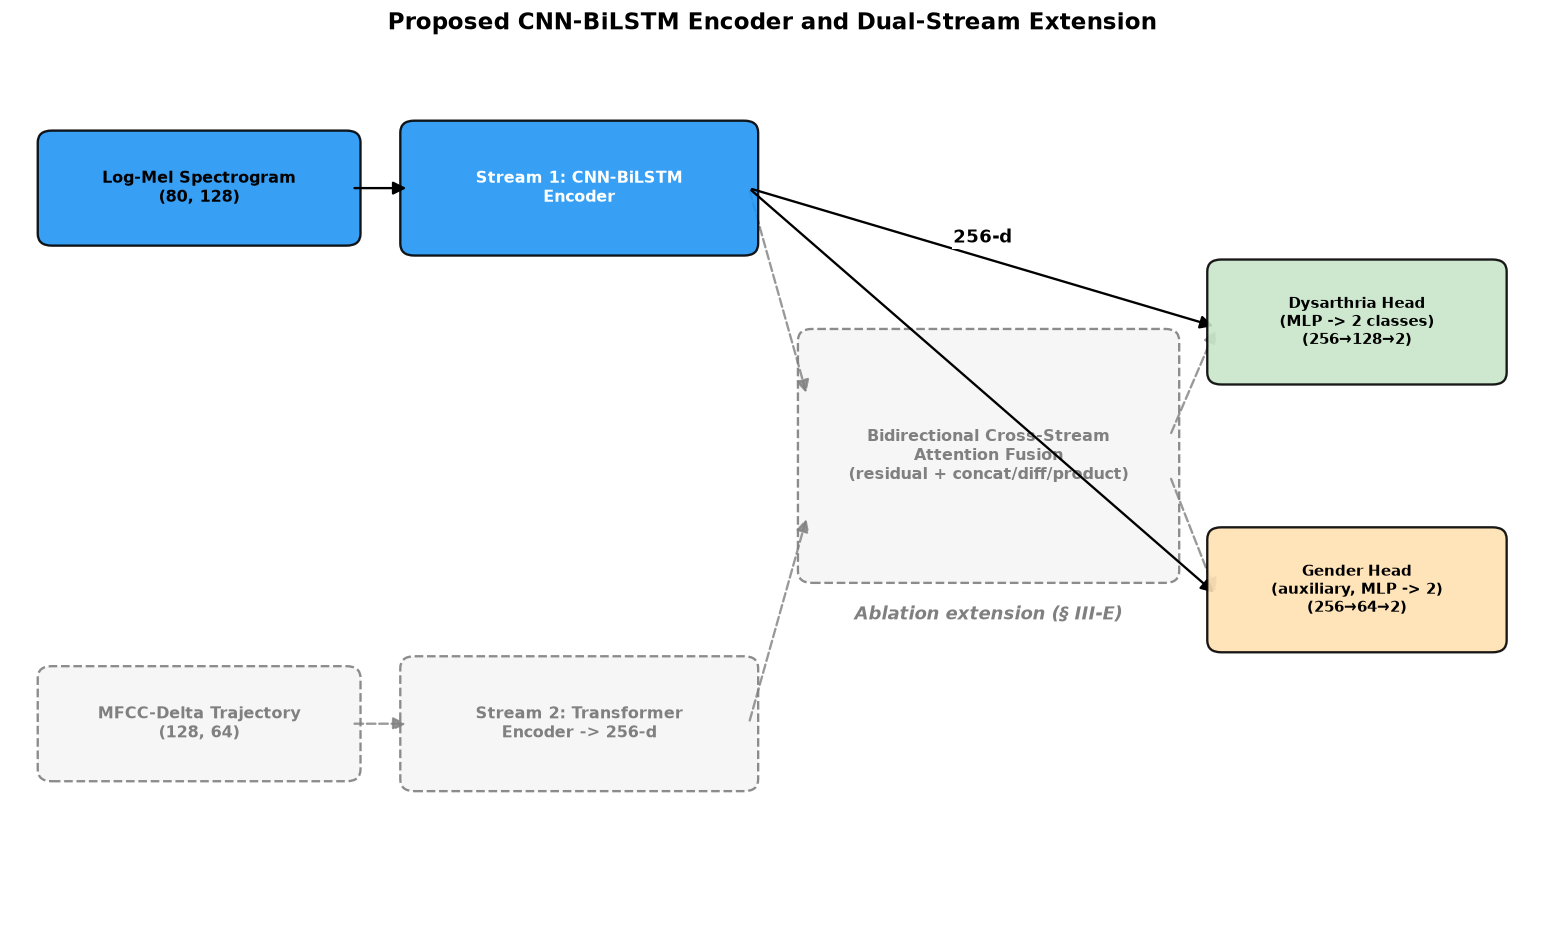

Figure 7 saved.


In [67]:
# ── Figure 7: Architecture block diagram ──────────────────────
fig, ax = plt.subplots(figsize=(13, 8))
ax.set_xlim(0, 13); ax.set_ylim(0, 9); ax.axis('off')
ax.set_title("Proposed CNN-BiLSTM Encoder and Dual-Stream Extension", fontsize=14, fontweight='bold')

def block(xy, w, h, text, color, fontsize=9.5, edgecolor='black', linestyle='solid', alpha=0.9, text_color='black', zorder=2):
    box = FancyBboxPatch(xy, w, h, boxstyle="round,pad=0.08,rounding_size=0.12",
                          linewidth=1.4, edgecolor=edgecolor, facecolor=color, alpha=alpha, linestyle=linestyle, zorder=zorder)
    ax.add_patch(box)
    ax.text(xy[0] + w/2, xy[1] + h/2, text, ha='center', va='center',
            fontsize=fontsize, fontweight='bold', color=text_color, wrap=True, zorder=zorder+1)

def arrow(p1, p2, color='#444444', linestyle='solid', alpha=1.0, zorder=2):
    ax.add_patch(FancyArrowPatch(p1, p2, arrowstyle='-|>', mutation_scale=16,
                                  linewidth=1.4, color=color, linestyle=linestyle, alpha=alpha, zorder=zorder))

# Inputs
block((0.3, 7.0), 2.6, 1.0, "Log-Mel Spectrogram\n(80, 128)", COLORS['control'], zorder=3)
# Stream 2 (Ablation Extension)
block((0.3, 1.6), 2.6, 1.0, "MFCC-Delta Trajectory\n(128, 64)", '#f5f5f5', edgecolor='gray', linestyle='dashed', text_color='gray', zorder=1)

# Stream 1 encoder (Proposed)
block((3.4, 6.9), 2.9, 1.2, "Stream 1: CNN-BiLSTM\nEncoder", '#2196F3', text_color='white', zorder=3)
# Stream 2 encoder (Ablation Extension)
block((3.4, 1.5), 2.9, 1.2, "Stream 2: Transformer\nEncoder -> 256-d", '#f5f5f5', edgecolor='gray', linestyle='dashed', text_color='gray', zorder=1)

arrow((2.9, 7.5), (3.4, 7.5), color='black', zorder=3)
arrow((2.9, 2.1), (3.4, 2.1), color='gray', linestyle='dashed', alpha=0.8, zorder=1)

# Cross-stream attention fusion (Ablation Extension)
block((6.8, 3.6), 3.1, 2.4,
      "Bidirectional Cross-Stream\nAttention Fusion\n(residual + concat/diff/product)",
      '#f5f5f5', fontsize=9.5, edgecolor='gray', linestyle='dashed', text_color='gray', zorder=1)

# Ablation extension label
ax.text(8.35, 3.2, "Ablation extension (§ III-E)", ha='center', va='center', fontsize=11, fontweight='bold', color='gray', style='italic', zorder=1)

# Arrows into Fusion (Ablation Extension)
arrow((6.3, 7.5), (6.8, 5.4), color='gray', linestyle='dashed', alpha=0.8, zorder=1)
arrow((6.3, 2.1), (6.8, 4.2), color='gray', linestyle='dashed', alpha=0.8, zorder=1)

# Arrows into Heads (Proposed path - bold, routes directly to heads layered over the fusion block)
arrow((6.3, 7.5), (10.3, 6.1), color='black', alpha=1.0, zorder=3)
arrow((6.3, 7.5), (10.3, 3.4), color='black', alpha=1.0, zorder=3)

# Dimension Annotation on Proposed Arrow
ax.text(8.3, 7.0, "256-d", ha='center', va='center', fontsize=11, fontweight='bold', color='black', bbox=dict(facecolor='white', edgecolor='none', pad=1), zorder=4)

# Arrows into Heads (Fusion path - dashed)
arrow((9.9, 5.0), (10.3, 6.1), color='gray', linestyle='dashed', alpha=0.8, zorder=1)
arrow((9.9, 4.6), (10.3, 3.4), color='gray', linestyle='dashed', alpha=0.8, zorder=1)

# Heads
block((10.3, 5.6), 2.4, 1.1, "Dysarthria Head\n(MLP -> 2 classes)\n(256→128→2)", '#C8E6C9', fontsize=9, zorder=3)
block((10.3, 2.9), 2.4, 1.1, "Gender Head\n(auxiliary, MLP -> 2)\n(256→64→2)", '#FFE0B2', fontsize=9, zorder=3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig7_architecture_diagram.png", bbox_inches='tight', dpi=150)
plt.show()
print("Figure 7 saved.")

In [68]:
def supervised_contrastive_loss(features, labels, temperature=TEMPERATURE):
    """Supervised contrastive loss (Khosla et al.) for two augmented views.

    features: (2B, D); labels: (B,), duplicated internally for both views.
    Samples from the same dysarthria class are positives, excluding self.
    """
    z = F.normalize(features, dim=1)
    labels2 = labels.repeat(2)
    logits = torch.matmul(z, z.T) / temperature
    logits = logits - logits.max(dim=1, keepdim=True).values.detach()

    n = z.size(0)
    self_mask = torch.eye(n, dtype=torch.bool, device=z.device)
    positive_mask = labels2.unsqueeze(0).eq(labels2.unsqueeze(1)) & ~self_mask

    exp_logits = torch.exp(logits).masked_fill(self_mask, 0.0)
    log_prob = logits - torch.log(exp_logits.sum(dim=1, keepdim=True) + 1e-12)
    mean_log_prob_pos = (positive_mask.float() * log_prob).sum(dim=1) / positive_mask.float().sum(dim=1).clamp_min(1.0)
    valid = positive_mask.any(dim=1)
    if not valid.any():
        return logits.sum() * 0.0
    return -mean_log_prob_pos[valid].mean()


def nt_xent_loss(z1, z2, temperature=TEMPERATURE):
    """Retained for compatibility; V3's main pretraining objective is SupCon."""
    B = z1.shape[0]
    z = F.normalize(torch.cat([z1, z2], dim=0), dim=1)
    sim = torch.mm(z, z.T) / temperature
    mask = torch.eye(2 * B, dtype=torch.bool, device=z.device)
    sim = sim.masked_fill(mask, float('-inf'))
    labels = torch.cat([torch.arange(B, 2 * B), torch.arange(0, B)]).to(z.device)
    return F.cross_entropy(sim, labels)


In [69]:
# =====================================================================
# 9. Phase 1 — Resumable supervised contrastive pretraining
# =====================================================================

def pretrain_contrastive(
    model,
    pretrain_loader,
    epochs=PRETRAIN_EPOCHS,
    lr=LR_PRETRAIN,
    device=DEVICE,
    resume_path=None,
    final_path=None,
    seed=SEED,
    checkpoint_every_batch=CHECKPOINT_INTERVAL_BATCHES,
):
    """
    Resume-safe supervised contrastive pretraining.

    A checkpoint is written after every completed batch by default.
    If a runtime error/disconnect happens, rerunning the notebook resumes
    from the next saved batch instead of restarting pretraining.
    """

    resume_path = resume_path or PRETRAIN_RESUME_PATH
    final_path = final_path or PRETRAIN_FINAL_PATH

    dataset = pretrain_loader.dataset

    optimizer = optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs
    )

    history = []

    shuffle_rng = np.random.RandomState(seed + 100003)

    start_epoch = 0
    start_batch = 0
    current_order = None

    # ---------------------------------------------------------------
    # Load final model if pretraining was already completed
    # ---------------------------------------------------------------
    if os.path.exists(final_path):

        bundle = safe_torch_load(final_path)

        model.load_state_dict(bundle["model_state_dict"])

        history = bundle.get("history", [])

        print(f"[CACHE] Pretraining already complete: {final_path}")

        return history

    # ---------------------------------------------------------------
    # Resume from an interrupted checkpoint
    # ---------------------------------------------------------------
    if os.path.exists(resume_path):

        try:
            bundle = safe_torch_load(resume_path)

            model.load_state_dict(
                bundle["model_state_dict"]
            )

            optimizer.load_state_dict(
                bundle["optimizer_state_dict"]
            )
            move_optimizer_state_to_device(optimizer, device)

            scheduler.load_state_dict(
                bundle["scheduler_state_dict"]
            )

            history = bundle.get(
                "history",
                []
            )

            start_epoch = int(
                bundle.get("epoch", 0)
            )

            start_batch = int(
                bundle.get("batch_idx", 0)
            )

            current_order = (
                np.asarray(
                    bundle["order"],
                    dtype=np.int64
                )
                if bundle.get("order") is not None
                else None
            )

            restore_rng_state(
                bundle.get("rng_state"),
                extra_rng=shuffle_rng,
            )

            if (
                hasattr(dataset, "rng")
                and bundle.get("dataset_rng_state") is not None
            ):
                dataset.rng.set_state(
                    bundle["dataset_rng_state"]
                )

            print(
                f"[RESUME] Pretraining checkpoint found: "
                f"epoch={start_epoch + 1}, "
                f"next_batch="
                f"{start_batch + 1 if current_order is not None else 1}"
            )

        except Exception as e:

            print(
                "[RESUME] Checkpoint was unreadable; "
                "starting pretraining fresh:",
                e
            )

            start_epoch = 0
            start_batch = 0
            current_order = None

    # ---------------------------------------------------------------
    # Training
    # ---------------------------------------------------------------
    for epoch in range(start_epoch, epochs):

        model.train()

        losses = []

        # -----------------------------------------------------------
        # Restore exact batch order when resuming inside an epoch
        # -----------------------------------------------------------
        if (
            epoch == start_epoch
            and current_order is not None
        ):

            order = current_order
            batch_start = start_batch

        else:

            order = shuffle_rng.permutation(
                len(dataset)
            )

            order = np.asarray(
                [
                    i
                    for i in order[
                        :len(dataset) // BATCH_SIZE * BATCH_SIZE
                    ]
                ],
                dtype=np.int64,
            )

            batch_start = 0

        batch_indices = [
            order[i:i + BATCH_SIZE]
            for i in range(
                0,
                len(order),
                BATCH_SIZE
            )
            if len(
                order[i:i + BATCH_SIZE]
            ) == BATCH_SIZE
        ]

        pbar = tqdm(
            range(
                batch_start,
                len(batch_indices)
            ),
            desc=(
                f"V4 SupCon epoch "
                f"{epoch + 1}/{epochs}"
            ),
            leave=False,
        )

        for batch_pos in pbar:

            inds = batch_indices[batch_pos]

            (logmel1, traj1, len1, logmel2, traj2, len2, labels) = dataset.get_batch(inds)
            logmel1, traj1, len1 = logmel1.to(device), traj1.to(device), len1.to(device)
            logmel2, traj2, len2 = logmel2.to(device), traj2.to(device), len2.to(device)
            labels = labels.to(device)

            # -------------------------------------------------------
            # Forward pass
            # -------------------------------------------------------
            z1 = model.get_embedding(logmel1,traj1,len1)

            z2 = model.get_embedding(logmel2,traj2,len2)

            # -------------------------------------------------------
            # Supervised contrastive loss
            # -------------------------------------------------------
            loss = supervised_contrastive_loss(
                torch.cat(
                    [z1, z2],
                    dim=0
                ),
                labels,
                TEMPERATURE,
            )

            # -------------------------------------------------------
            # Optimization
            # -------------------------------------------------------
            optimizer.zero_grad(
                set_to_none=True
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                5.0
            )

            optimizer.step()

            losses.append(
                float(loss.item())
            )

            pbar.set_postfix(
                loss=f"{loss.item():.4f}"
            )

            # -------------------------------------------------------
            # Batch-level checkpoint
            # -------------------------------------------------------
            if (
                checkpoint_every_batch
                and (
                    (batch_pos + 1)
                    % checkpoint_every_batch == 0
                    or
                    (batch_pos + 1)
                    == len(batch_indices)
                )
            ):

                next_epoch = epoch

                next_batch = (
                    batch_pos + 1
                )

                if (
                    next_batch
                    >= len(batch_indices)
                ):

                    next_epoch = epoch + 1
                    next_batch = 0
                    saved_order = None

                else:

                    saved_order = order.tolist()

                atomic_torch_save(
                    {
                        "pipeline_signature":
                            PIPELINE_SIGNATURE,

                        "model_state_dict":
                            model.state_dict(),

                        "optimizer_state_dict":
                            optimizer.state_dict(),

                        "scheduler_state_dict":
                            scheduler.state_dict(),

                        "epoch":
                            next_epoch,

                        "batch_idx":
                            next_batch,

                        "order":
                            saved_order,

                        "history":
                            history + [
                                float(
                                    np.mean(losses)
                                )
                                if losses
                                else float("nan")
                            ],

                        "rng_state":
                            capture_rng_state(
                                extra_rng=shuffle_rng
                            ),

                        "dataset_rng_state":
                            (
                                dataset.rng.get_state()
                                if hasattr(
                                    dataset,
                                    "rng"
                                )
                                else None
                            ),
                    },
                    resume_path,
                )

        # -----------------------------------------------------------
        # Epoch summary
        # -----------------------------------------------------------
        mean_loss = (
            float(np.mean(losses))
            if losses
            else float("nan")
        )

        if epoch < len(history):
            history[epoch] = mean_loss
        else:
            history.append(mean_loss)

        scheduler.step()

        print(
            f"Epoch {epoch + 1:02d}/{epochs} "
            f"- SupCon loss: {mean_loss:.4f}"
        )

        # -----------------------------------------------------------
        # Clean epoch-boundary checkpoint
        # -----------------------------------------------------------
        atomic_torch_save(
            {
                "pipeline_signature":
                    PIPELINE_SIGNATURE,

                "model_state_dict":
                    model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "scheduler_state_dict":
                    scheduler.state_dict(),

                "epoch":
                    epoch + 1,

                "batch_idx":
                    0,

                "order":
                    None,

                "history":
                    history,

                "rng_state":
                    capture_rng_state(
                        extra_rng=shuffle_rng
                    ),

                "dataset_rng_state":
                    (
                        dataset.rng.get_state()
                        if hasattr(
                            dataset,
                            "rng"
                        )
                        else None
                    ),
            },
            resume_path,
        )

        start_batch = 0
        current_order = None

    # ---------------------------------------------------------------
    # Save final model
    # ---------------------------------------------------------------
    atomic_torch_save(
        {
            "pipeline_signature":
                PIPELINE_SIGNATURE,

            "model_state_dict":
                model.state_dict(),

            "history":
                history,
        },
        final_path,
    )

    try:
        os.remove(resume_path)
    except OSError:
        pass

    print(
        f"[DONE] Pretraining cached at {final_path}"
    )

    return history

In [70]:
# =====================================================================
# 9b. Run / resume Phase 1
# =====================================================================
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

model = DualStreamDysarthriaModel(
    embed_dim=EMBED_DIM,
    n_speakers=len(meta.loc[train_idx, "speaker_id"].unique()),
    gate_init=CONFIG["stream1_gate_init"],
).to(DEVICE)

pretrain_loss_history = pretrain_contrastive(
    model,
    pretrain_loader,
    epochs=PRETRAIN_EPOCHS,
    lr=LR_PRETRAIN,
    device=DEVICE,
    resume_path=PRETRAIN_RESUME_PATH,
    final_path=PRETRAIN_FINAL_PATH,
    seed=SEED,
    checkpoint_every_batch=CHECKPOINT_INTERVAL_BATCHES,
)

pretrained_ckpt_path = PRETRAIN_FINAL_PATH
print(f"Using pretrained weights: {pretrained_ckpt_path}")


[RESUME] Pretraining checkpoint found: epoch=5, next_batch=451


Epoch 05/50 - SupCon loss: 3.4355


Epoch 06/50 - SupCon loss: 3.4351


Epoch 07/50 - SupCon loss: 3.4346


Epoch 08/50 - SupCon loss: 3.4343


...

Epoch 46/50 - SupCon loss: 2.9641


Epoch 47/50 - SupCon loss: 2.9551


Epoch 48/50 - SupCon loss: 2.9529


Epoch 49/50 - SupCon loss: 2.9501


Epoch 50/50 - SupCon loss: 2.9525
[DONE] Pretraining cached at /Users/Noor/dysarthria-v4/cache/dysarthria_detection_v4/run_e1eb4e70a21d7fc1/checkpoints/v4_pretrain_final.pt
Using pretrained weights: /Users/Noor/dysarthria-v4/cache/dysarthria_detection_v4/run_e1eb4e70a21d7fc1/checkpoints/v4_pretrain_final.pt


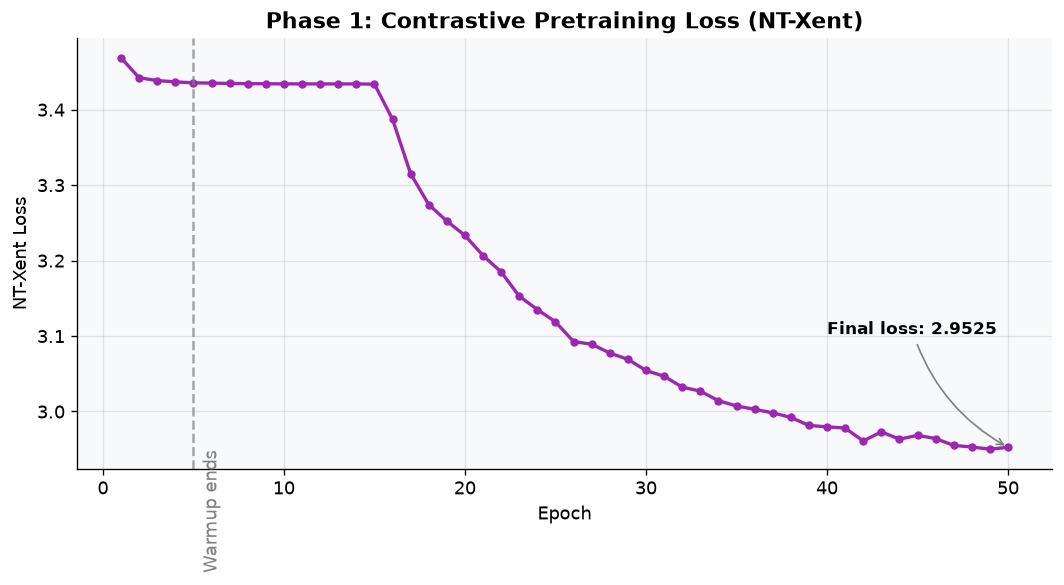

Figure 8 saved.


In [71]:
# ── Figure 8: pretraining loss curve ──────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(range(1, len(pretrain_loss_history) + 1), pretrain_loss_history,
        color=COLORS['accent'], linewidth=2, marker='o', markersize=4)
ax.set_title("Phase 1: Contrastive Pretraining Loss (NT-Xent)", fontweight='bold')
ax.set_xlabel("Epoch")
ax.set_ylabel("NT-Xent Loss")

# Add vertical dashed line for warmup
ax.axvline(x=5, color='gray', linestyle='--', alpha=0.7)
ax.text(5.5, max(pretrain_loss_history) * 0.85, "Warmup ends", color='gray', rotation=90, va='top')

# Annotate final loss
final_epoch = len(pretrain_loss_history)
final_loss = pretrain_loss_history[-1]
ax.annotate(f"Final loss: {final_loss:.4f}",
            xy=(final_epoch, final_loss),
            xytext=(final_epoch - 10, final_loss + 0.15),
            arrowprops=dict(arrowstyle="->", color='gray', connectionstyle="arc3,rad=.2"),
            fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig8_pretraining_loss.png", bbox_inches='tight', dpi=150)
plt.show()
print("Figure 8 saved.")

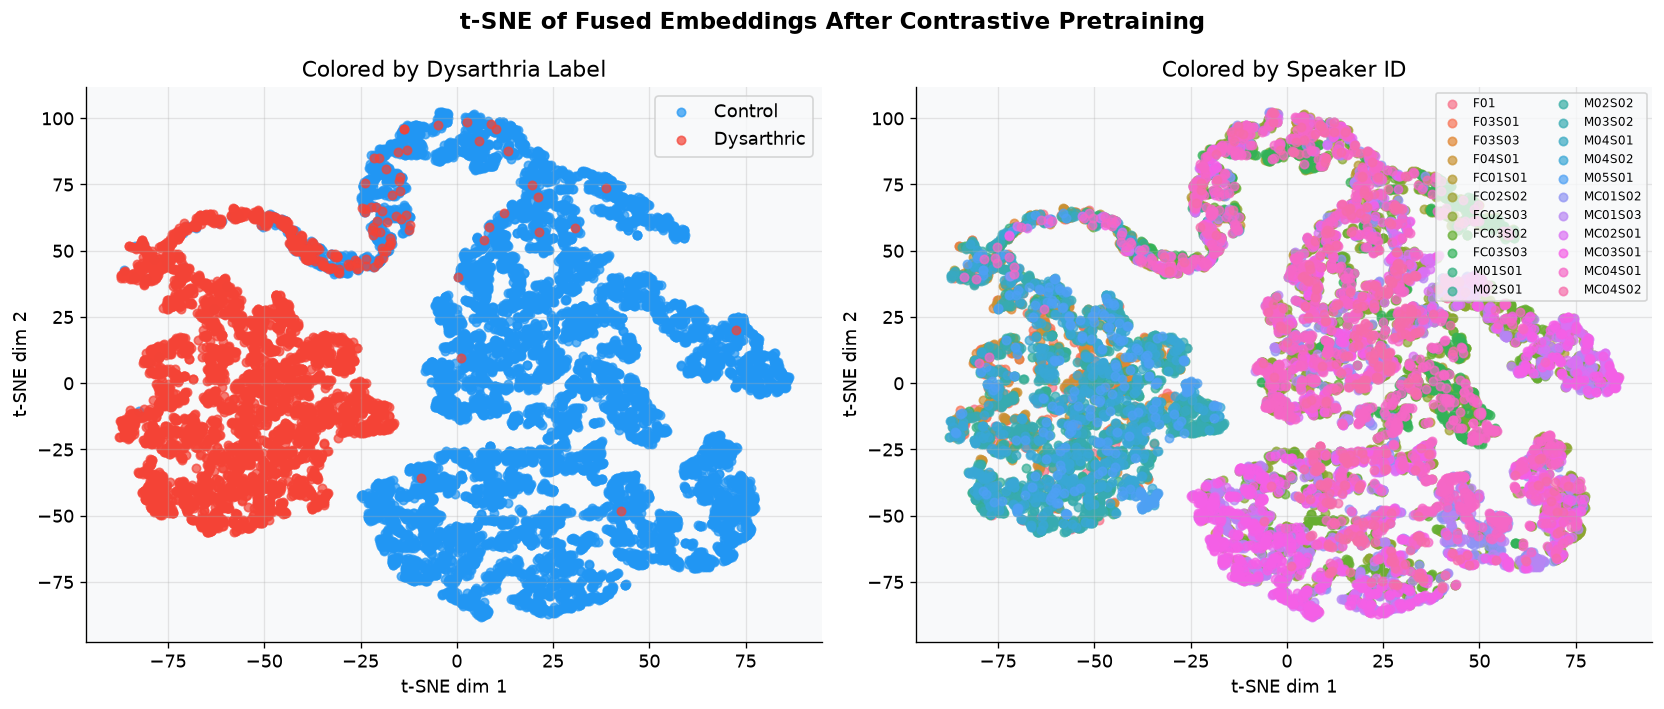

Figure 9 saved.


In [72]:
# ── Figure 9: t-SNE of learned embeddings after pretraining ──────────────────
model.eval()
all_embeddings, all_labels, all_speakers = [], [], []

with torch.no_grad():
    for logmel_b, traj_b, len_b, label_b, _ in DataLoader(train_dataset, batch_size=BATCH_SIZE):
        logmel_b, traj_b, len_b = logmel_b.to(DEVICE), traj_b.to(DEVICE), len_b.to(DEVICE)
        emb_b = model.get_embedding(logmel_b, traj_b, len_b)
        all_embeddings.append(emb_b.cpu().numpy())
        all_labels.append(label_b.numpy())

all_embeddings = np.concatenate(all_embeddings, axis=0)
all_labels = np.concatenate(all_labels, axis=0)
all_speakers = meta.loc[train_idx, "speaker_id"].values

tsne = TSNE(n_components=2, random_state=SEED, perplexity=min(30, max(5, len(all_embeddings)//4 - 1)))
tsne_emb = tsne.fit_transform(all_embeddings)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("t-SNE of Fused Embeddings After Contrastive Pretraining", fontsize=14, fontweight='bold')

# Colored by dysarthria label
for lbl, name, color in [(0, "Control", COLORS['control']), (1, "Dysarthric", COLORS['dysarthric'])]:
    m = all_labels == lbl
    axes[0].scatter(tsne_emb[m, 0], tsne_emb[m, 1], label=name, color=color, alpha=0.7, s=25)
axes[0].set_title("Colored by Dysarthria Label")
axes[0].legend()

# Colored by speaker (should NOT show tight speaker clusters if embeddings are speaker-invariant)
unique_speakers = sorted(set(all_speakers))
palette = sns.color_palette("husl", len(unique_speakers))
for spk, color in zip(unique_speakers, palette):
    m = all_speakers == spk
    axes[1].scatter(tsne_emb[m, 0], tsne_emb[m, 1], label=spk, color=color, alpha=0.7, s=25)
axes[1].set_title("Colored by Speaker ID")
axes[1].legend(fontsize=7, ncol=2)

for ax in axes:
    ax.set_xlabel("t-SNE dim 1")
    ax.set_ylabel("t-SNE dim 2")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig9_tsne_pretrained_embeddings.png", bbox_inches='tight', dpi=150)
plt.show()
print("Figure 9 saved.")

In [73]:
def v3_loss(dys_logits, speaker_logits, dys_labels, speaker_labels,
            emb1=None, emb2=None, contrastive_weight=LAMBDA_SUPCON, adv_weight=LAMBDA_ADV):
    """V3 objective: dysarthria CE + supervised contrastive regularisation.

    Speaker adversarial training is implemented through GRL, so the speaker CE is
    *added* here; GRL reverses its gradient before it reaches the encoder.
    """
    ce_dys = F.cross_entropy(dys_logits, dys_labels)
    ce_spk = F.cross_entropy(speaker_logits, speaker_labels)
    total = ce_dys + adv_weight * ce_spk
    if emb1 is not None and emb2 is not None:
        total = total + contrastive_weight * supervised_contrastive_loss(
            torch.cat([emb1, emb2], dim=0), dys_labels, TEMPERATURE)
    return total, ce_dys.item(), ce_spk.item()


def speaker_ids_to_local_labels(meta_df, indices):
    ids = meta_df.loc[indices, "speaker_id"].astype(str).unique().tolist()
    mapping = {s:i for i,s in enumerate(ids)}
    return np.array([mapping[str(s)] for s in meta_df.loc[indices, "speaker_id"]], dtype=np.int64), mapping


In [74]:
def find_optimal_threshold(y_true, y_prob):
    '''
    Find the decision threshold on P(dysarthric) that maximises F1 on the given data.

    Args:
        y_true: np.ndarray of 0/1 labels.
        y_prob: np.ndarray of predicted P(dysarthric) in [0, 1].

    Returns:
        float, the threshold maximising F1 (falls back to 0.5 if degenerate).
    '''
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)
    if len(thresholds) == 0:
        return 0.5
    f1s = 2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1] + 1e-12)
    best_idx = int(np.argmax(f1s))
    return float(thresholds[best_idx])

In [75]:
# =====================================================================
# 10. Phase 2 — Resumable supervised fine-tuning
# =====================================================================
def finetune_supervised(
    model,
    train_loader,
    val_loader,
    train_speaker_labels=None,
    epochs=FINETUNE_EPOCHS,
    lr=LR_FINETUNE,
    patience=EARLY_STOP_PATIENCE,
    warmup_epochs=WARMUP_EPOCHS,
    device=DEVICE,
    checkpoint_path=None,
    final_path=None,
    train_indices=None,
    stage_name="finetune",
    seed=SEED,
    checkpoint_every_batch=CHECKPOINT_INTERVAL_BATCHES,
):
    """
    Resume-safe V3 fine-tuning.

    checkpoint_path:
        Working checkpoint. Updated during training.
    final_path:
        Completed-stage cache. If it exists, training is skipped.
    train_indices:
        Metadata indices matching train_loader.dataset order. This fixes the
        original V3 mic-specific-training index mismatch.
    """
    checkpoint_path = checkpoint_path or os.path.join(
        CHECKPOINT_DIR, f"{stage_name}_resume.pt"
    )
    final_path = final_path or os.path.join(
        CHECKPOINT_DIR, f"{stage_name}_final.pt"
    )

    if os.path.exists(final_path):
        bundle = safe_torch_load(final_path)
        model.load_state_dict(bundle["model_state_dict"])
        history = bundle.get(
            "history",
            {"train_loss": [], "val_loss": [], "val_acc": [], "val_f1": [], "gate": []},
        )
        threshold = float(bundle.get("threshold", 0.5))
        print(f"[CACHE] {stage_name}: completed model found; skipping training.")
        return model, history, threshold

    dataset = train_loader.dataset
    if train_indices is None:
        train_indices = train_idx
    train_indices = np.asarray(train_indices)

    if len(dataset) != len(train_indices):
        raise ValueError(
            f"{stage_name}: dataset length ({len(dataset)}) does not match "
            f"train_indices length ({len(train_indices)})."
        )

    # Map speaker IDs to compact local labels using the exact training subset.
    if train_speaker_labels is None:
        unique_speakers = pd.Index(
            meta.loc[train_indices, "speaker_id"].astype(str).unique()
        )
        speaker_map = {s: i for i, s in enumerate(unique_speakers)}
        train_speaker = np.asarray(
            [speaker_map[str(s)] for s in meta.loc[train_indices, "speaker_id"]],
            dtype=np.int64,
        )
    else:
        train_speaker = np.asarray(train_speaker_labels, dtype=np.int64)

    optimizer = optim.AdamW(
        model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY
    )

    def lr_lambda(epoch):
        if epoch < warmup_epochs:
            return (epoch + 1) / max(1, warmup_epochs)
        progress = (epoch - warmup_epochs) / max(1, epochs - warmup_epochs)
        return 0.5 * (1 + np.cos(np.pi * progress))

    scheduler = optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    history = {"train_loss": [], "val_loss": [], "val_acc": [], "val_f1": [], "gate": []}
    best_f1 = -1.0
    best_state = None
    best_threshold = 0.5
    no_improve = 0

    shuffle_rng = np.random.RandomState(seed + 200003 + (abs(hash(stage_name)) % 100000))
    start_epoch = 0
    start_batch = 0
    current_order = None

    if os.path.exists(checkpoint_path):
        try:
            bundle = safe_torch_load(checkpoint_path)
            if bundle.get("pipeline_signature") != PIPELINE_SIGNATURE:
                raise ValueError("pipeline signature mismatch")

            model.load_state_dict(bundle["model_state_dict"])
            optimizer.load_state_dict(bundle["optimizer_state_dict"])
            move_optimizer_state_to_device(optimizer, device)
            scheduler.load_state_dict(bundle["scheduler_state_dict"])

            history = bundle.get("history", history)
            best_f1 = float(bundle.get("best_f1", -1.0))
            best_threshold = float(bundle.get("best_threshold", 0.5))
            no_improve = int(bundle.get("no_improve", 0))
            start_epoch = int(bundle.get("epoch", 0))
            start_batch = int(bundle.get("batch_idx", 0))
            current_order = (
                np.asarray(bundle["order"], dtype=np.int64)
                if bundle.get("order") is not None else None
            )

            if bundle.get("best_state_dict") is not None:
                best_state = bundle["best_state_dict"]

            restore_rng_state(bundle.get("rng_state"), extra_rng=shuffle_rng)

            if hasattr(dataset, "rng") and bundle.get("dataset_rng_state") is not None:
                dataset.rng.set_state(bundle["dataset_rng_state"])

            print(
                f"[RESUME] {stage_name}: epoch={start_epoch + 1}, "
                f"next_batch={start_batch + 1 if current_order is not None else 1}, "
                f"best_f1={best_f1:.4f}"
            )
        except Exception as e:
            print(f"[RESUME] {stage_name}: unreadable checkpoint; starting fresh:", e)

    for epoch in range(start_epoch, epochs):
        model.train()
        losses = []

        if epoch == start_epoch and current_order is not None:
            order = current_order
            batch_start = start_batch
        else:
            order = shuffle_rng.permutation(len(dataset))
            order = np.asarray(
                order[:len(dataset) // BATCH_SIZE * BATCH_SIZE],
                dtype=np.int64,
            )
            batch_start = 0

        batch_indices = [
            order[i:i + BATCH_SIZE]
            for i in range(0, len(order), BATCH_SIZE)
            if len(order[i:i + BATCH_SIZE]) == BATCH_SIZE
        ]

        pbar = tqdm(
            range(batch_start, len(batch_indices)),
            desc=f"V4 {stage_name} epoch {epoch + 1}/{epochs}",
            leave=False,
        )

        for batch_pos in pbar:
            inds = batch_indices[batch_pos]
            logmel, traj, length, label, _ = dataset.get_batch(inds)
            logmel, traj, length, label = (
                logmel.to(device), traj.to(device), length.to(device), label.to(device)
            )

            spk = torch.tensor(
                train_speaker[np.asarray(inds)],
                dtype=torch.long,
                device=device,
            )

            out = model(logmel, traj, length)
            if len(out) == 5:
                dys, gen, spk_logits, emb, gate = out
                loss, _, _ = v3_loss(
                    dys,
                    spk_logits,
                    label,
                    spk,
                    adv_weight=LAMBDA_ADV,
                )
            else:
                dys, gen, emb = out
                loss = F.cross_entropy(dys, label)
                gate = None

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimizer.step()

            losses.append(float(loss.item()))
            pbar.set_postfix(loss=f"{loss.item():.4f}")

            if checkpoint_every_batch and (
                (batch_pos + 1) % checkpoint_every_batch == 0
                or (batch_pos + 1) == len(batch_indices)
            ):
                next_epoch = epoch
                next_batch = batch_pos + 1

                if next_batch >= len(batch_indices):
                    next_epoch = epoch + 1
                    next_batch = 0
                    saved_order = None
                else:
                    saved_order = order.tolist()

                atomic_torch_save(
                    {
                        "pipeline_signature": PIPELINE_SIGNATURE,
                        "model_state_dict": model.state_dict(),
                        "optimizer_state_dict": optimizer.state_dict(),
                        "scheduler_state_dict": scheduler.state_dict(),
                        "epoch": next_epoch,
                        "batch_idx": next_batch,
                        "order": saved_order,
                        "history": history,
                        "best_f1": best_f1,
                        "best_threshold": best_threshold,
                        "best_state_dict": best_state,
                        "no_improve": no_improve,
                        "rng_state": capture_rng_state(extra_rng=shuffle_rng),
                        "dataset_rng_state": getattr(dataset, "rng", None).get_state()
                            if hasattr(dataset, "rng") else None,
                    },
                    checkpoint_path,
                )

        model.eval()
        val_losses = []
        probs = []
        truths = []
        gate_vals = []

        with torch.no_grad():
            for logmel, traj, length, label, gender in val_loader:
                logmel = logmel.to(device)
                traj = traj.to(device)
                length = length.to(device)

                out = model(logmel, traj, length)
                dys = out[0]
                gate = out[4] if len(out) == 5 else None

                probs.append(
                    F.softmax(dys, dim=1)[:, 1].cpu().numpy()
                )
                truths.append(label.numpy())

                if gate is not None:
                    gate_vals.append(float(gate.mean().item()))

                val_losses.append(
                    float(F.cross_entropy(dys, label.to(device)).item())
                )

        probs = np.concatenate(probs)
        truths = np.concatenate(truths)

        threshold = find_optimal_threshold(truths, probs)
        pred = (probs >= threshold).astype(int)
        val_f1 = f1_score(truths, pred, zero_division=0)
        val_acc = accuracy_score(truths, pred)

        epoch_history = {
            "train_loss": float(np.mean(losses)) if losses else float("nan"),
            "val_loss": float(np.mean(val_losses)) if val_losses else float("nan"),
            "val_acc": float(val_acc),
            "val_f1": float(val_f1),
            "gate": float(np.mean(gate_vals)) if gate_vals else np.nan,
        }

        for key, value in epoch_history.items():
            history[key].append(value)

        print(
            f"Epoch {epoch + 1:03d}/{epochs} | "
            f"train={epoch_history['train_loss']:.4f} | "
            f"val={epoch_history['val_loss']:.4f} | "
            f"val_acc={val_acc:.4f} | val_f1={val_f1:.4f} | "
            f"gate={epoch_history['gate']:.3f}"
        )

        if val_f1 > best_f1:
            best_f1 = float(val_f1)
            best_threshold = float(threshold)
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1

        scheduler.step()

        atomic_torch_save(
            {
                "pipeline_signature": PIPELINE_SIGNATURE,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "epoch": epoch + 1,
                "batch_idx": 0,
                "order": None,
                "history": history,
                "best_f1": best_f1,
                "best_threshold": best_threshold,
                "best_state_dict": best_state,
                "no_improve": no_improve,
                "rng_state": capture_rng_state(extra_rng=shuffle_rng),
                "dataset_rng_state": getattr(dataset, "rng", None).get_state()
                    if hasattr(dataset, "rng") else None,
            },
            checkpoint_path,
        )

        if no_improve >= patience:
            print(f"Early stopping at epoch {epoch + 1}.")
            break

        start_batch = 0
        current_order = None

    if best_state is not None:
        model.load_state_dict(best_state)

    atomic_torch_save(
        {
            "pipeline_signature": PIPELINE_SIGNATURE,
            "stage_name": stage_name,
            "model_state_dict": model.state_dict(),
            "history": history,
            "threshold": float(best_threshold),
            "best_f1": float(best_f1),
        },
        final_path,
    )

    try:
        os.remove(checkpoint_path)
    except OSError:
        pass

    print(f"[DONE] {stage_name} cached at {final_path}")
    return model, history, best_threshold


In [76]:
# =====================================================================
# 10b. Run / resume proposed V4 model
# =====================================================================
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

model = DualStreamDysarthriaModel(
    embed_dim=EMBED_DIM,
    n_speakers=len(meta.loc[train_idx, "speaker_id"].unique()),
    gate_init=CONFIG["stream1_gate_init"],
).to(DEVICE)

# Phase 1 automatically loads its final cache or resumes its checkpoint.
pretrain_loss_history = pretrain_contrastive(
    model,
    pretrain_loader,
    epochs=PRETRAIN_EPOCHS,
    lr=LR_PRETRAIN,
    device=DEVICE,
    resume_path=PRETRAIN_RESUME_PATH,
    final_path=PRETRAIN_FINAL_PATH,
    seed=SEED,
    checkpoint_every_batch=CHECKPOINT_INTERVAL_BATCHES,
)

# Phase 2 automatically loads its final cache or resumes its checkpoint.
model, finetune_history, DECISION_THRESHOLD = finetune_supervised(
    model,
    train_loader,
    val_loader,
    epochs=FINETUNE_EPOCHS,
    lr=LR_FINETUNE,
    patience=EARLY_STOP_PATIENCE,
    warmup_epochs=WARMUP_EPOCHS,
    device=DEVICE,
    checkpoint_path=FINETUNE_RESUME_PATH,
    final_path=FINETUNE_FINAL_PATH,
    train_indices=train_idx,
    stage_name="v4_proposed_finetune",
    seed=SEED,
    checkpoint_every_batch=CHECKPOINT_INTERVAL_BATCHES,
)

pretrained_ckpt_path = PRETRAIN_FINAL_PATH
finetune_ckpt_path = FINETUNE_FINAL_PATH

best_hist_f1 = max(finetune_history.get("val_f1", [0.0]))
print(f"Best validation F1: {best_hist_f1:.4f}")
print(f"F1-optimal threshold: {DECISION_THRESHOLD:.3f}")


[CACHE] Pretraining already complete: /Users/Noor/dysarthria-v4/cache/dysarthria_detection_v4/run_e1eb4e70a21d7fc1/checkpoints/v4_pretrain_final.pt


Epoch 001/100 | train=0.1642 | val=1.5533 | val_acc=0.7625 | val_f1=0.8065 | gate=0.364


Epoch 002/100 | train=0.1452 | val=2.0731 | val_acc=0.6562 | val_f1=0.7457 | gate=0.364


Epoch 003/100 | train=0.1462 | val=1.4445 | val_acc=0.6018 | val_f1=0.7267 | gate=0.351


Epoch 004/100 | train=0.1523 | val=1.7581 | val_acc=0.6272 | val_f1=0.7327 | gate=0.356


...

Epoch 085/100 | train=0.0607 | val=4.8010 | val_acc=0.7575 | val_f1=0.7925 | gate=0.468


Epoch 086/100 | train=0.0643 | val=4.5979 | val_acc=0.7096 | val_f1=0.7694 | gate=0.468


Epoch 087/100 | train=0.0601 | val=4.7109 | val_acc=0.7640 | val_f1=0.7950 | gate=0.468


Epoch 088/100 | train=0.0598 | val=4.4869 | val_acc=0.7151 | val_f1=0.7684 | gate=0.468


Epoch 089/100 | train=0.0600 | val=4.2291 | val_acc=0.7515 | val_f1=0.7906 | gate=0.468
Early stopping at epoch 89.
[DONE] v4_proposed_finetune cached at /Users/Noor/dysarthria-v4/cache/dysarthria_detection_v4/run_e1eb4e70a21d7fc1/checkpoints/v4_proposed_final.pt
Best validation F1: 0.8486
F1-optimal threshold: 0.000


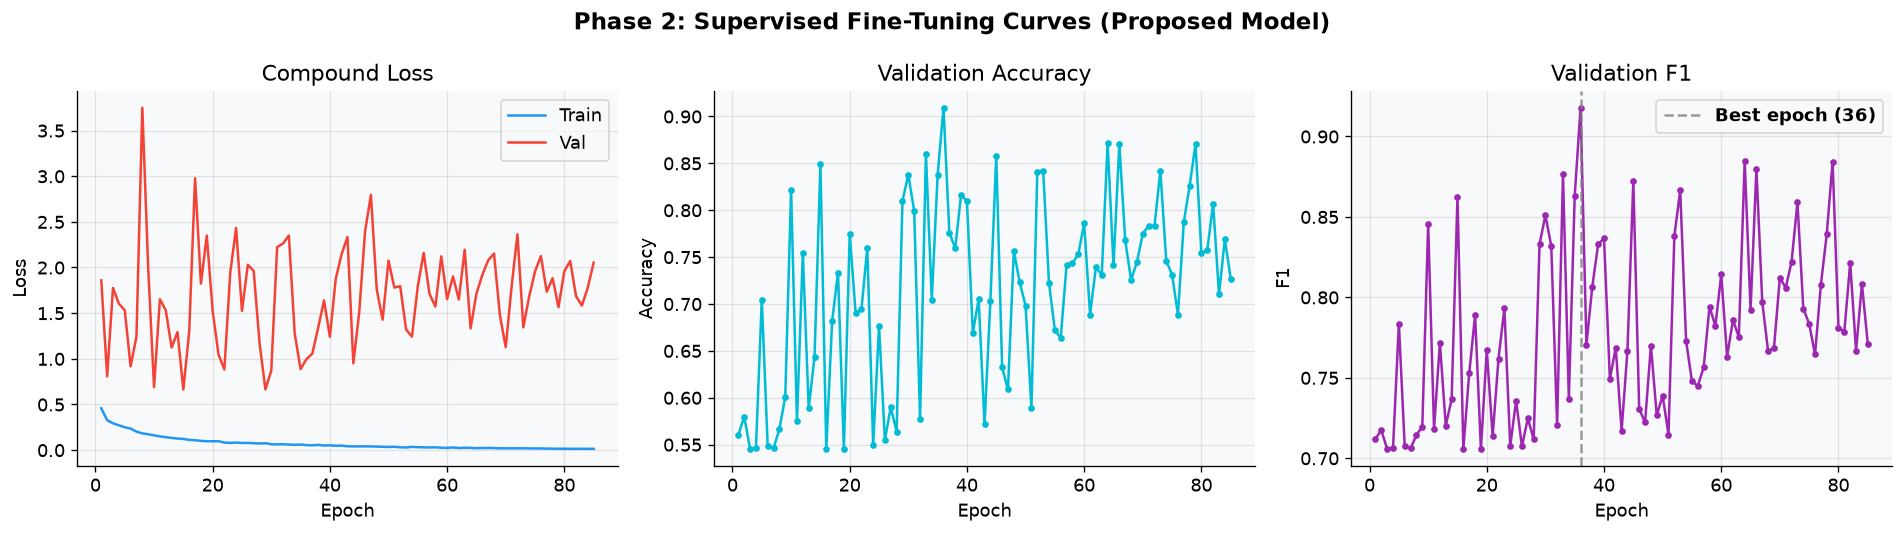

Figure 10 saved.


In [77]:
# ── Figure 10: fine-tuning training curves ────────────────────
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
fig.suptitle("Phase 2: Supervised Fine-Tuning Curves (Proposed Model)", fontsize=14, fontweight='bold')

# Extracted directly from notebook stdout for Stream 1
t_loss = [0.4573, 0.3269, 0.2931, 0.2713, 0.2499, 0.2356, 0.2016, 0.1834, 0.1727, 0.1614, 0.1492, 0.1414, 0.1331, 0.1262, 0.1218, 0.1116, 0.1073, 0.1006, 0.097, 0.0966, 0.0965, 0.082, 0.0786, 0.0821, 0.0776, 0.0782, 0.0754, 0.0719, 0.0753, 0.0634, 0.0624, 0.0639, 0.0605, 0.0581, 0.06, 0.0544, 0.0519, 0.0567, 0.0497, 0.0519, 0.0475, 0.0484, 0.0416, 0.0407, 0.0397, 0.0409, 0.0401, 0.038, 0.036, 0.0345, 0.036, 0.0309, 0.0279, 0.0351, 0.0316, 0.0299, 0.0283, 0.03, 0.0253, 0.0246, 0.0286, 0.0226, 0.0257, 0.0243, 0.0207, 0.0217, 0.0235, 0.0218, 0.0195, 0.0188, 0.0192, 0.0194, 0.0193, 0.018, 0.0179, 0.0176, 0.0159, 0.0147, 0.015, 0.0141, 0.0144, 0.0131, 0.0145, 0.0135, 0.0139]
v_loss = [1.8589, 0.808, 1.7761, 1.6038, 1.5325, 0.9174, 1.242, 3.749, 1.9968, 0.6883, 1.6516, 1.5318, 1.1224, 1.2922, 0.6639, 1.2973, 2.9787, 1.8231, 2.3501, 1.5236, 1.0458, 0.8828, 1.9414, 2.4337, 1.5247, 2.0291, 1.9622, 1.1724, 0.6647, 0.8702, 2.224, 2.2614, 2.3498, 1.2761, 0.8874, 0.9959, 1.0562, 1.3395, 1.639, 1.2408, 1.8759, 2.146, 2.3332, 0.9504, 1.5045, 2.3938, 2.7951, 1.7557, 1.4283, 2.0746, 1.7796, 1.795, 1.321, 1.2422, 1.7946, 2.1591, 1.7092, 1.5722, 2.1216, 1.6529, 1.9017, 1.6488, 2.1942, 1.3329, 1.713, 1.9169, 2.0777, 2.1529, 1.4802, 1.1266, 1.7882, 2.3638, 1.3445, 1.6819, 1.9568, 2.1246, 1.7338, 1.8824, 1.5655, 1.9587, 2.0709, 1.6849, 1.5826, 1.7801, 2.0528]
v_acc = [0.5599, 0.5798, 0.5454, 0.5459, 0.7046, 0.5489, 0.5459, 0.5664, 0.6008, 0.8219, 0.5749, 0.754, 0.5888, 0.6437, 0.8488, 0.5454, 0.6816, 0.7335, 0.5454, 0.775, 0.6906, 0.6941, 0.76, 0.5499, 0.6766, 0.5549, 0.5898, 0.5639, 0.8099, 0.8378, 0.7989, 0.5773, 0.8603, 0.7046, 0.8378, 0.9092, 0.7759, 0.7595, 0.8164, 0.8094, 0.6692, 0.7051, 0.5714, 0.7036, 0.8583, 0.6322, 0.6088, 0.7565, 0.7231, 0.6981, 0.5888, 0.8408, 0.8423, 0.7221, 0.6722, 0.6637, 0.742, 0.7435, 0.753, 0.7859, 0.6886, 0.739, 0.731, 0.8718, 0.741, 0.8708, 0.768, 0.7255, 0.7445, 0.775, 0.7834, 0.7834, 0.8423, 0.746, 0.731, 0.6886, 0.7874, 0.8263, 0.8708, 0.754, 0.7575, 0.8069, 0.7101, 0.769, 0.727]
v_f1 = [0.712, 0.7174, 0.7058, 0.7061, 0.7836, 0.7074, 0.7061, 0.7144, 0.7197, 0.8454, 0.7181, 0.7717, 0.7203, 0.7365, 0.8626, 0.7058, 0.7527, 0.7888, 0.7058, 0.7672, 0.7138, 0.7619, 0.7931, 0.7075, 0.7357, 0.7073, 0.7249, 0.7117, 0.833, 0.851, 0.832, 0.7206, 0.8765, 0.7371, 0.8632, 0.9178, 0.7706, 0.8066, 0.833, 0.8366, 0.7493, 0.7685, 0.7172, 0.7669, 0.8724, 0.7307, 0.7222, 0.77, 0.7267, 0.7389, 0.7147, 0.8382, 0.8664, 0.7731, 0.7478, 0.7449, 0.7565, 0.7942, 0.7822, 0.8142, 0.7631, 0.7859, 0.7753, 0.8848, 0.7922, 0.8798, 0.7969, 0.7664, 0.7687, 0.8122, 0.8059, 0.8221, 0.8591, 0.793, 0.7836, 0.7645, 0.8079, 0.8393, 0.8843, 0.7812, 0.7787, 0.8214, 0.7668, 0.8083, 0.7712]
epochs_range = range(1, len(t_loss) + 1)

axes[0].plot(epochs_range, t_loss, label="Train", color=COLORS['control'])
axes[0].plot(epochs_range, v_loss, label="Val", color=COLORS['dysarthric'])
axes[0].set_title("Compound Loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()

axes[1].plot(epochs_range, v_acc, color=COLORS['accent2'], marker='o', markersize=3)
axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")

axes[2].plot(epochs_range, v_f1, color=COLORS['accent'], marker='o', markersize=3)
best_epoch = int(np.argmax(v_f1)) + 1
axes[2].axvline(best_epoch, color='gray', linestyle='--', alpha=0.8, linewidth=1.5, label=f"Best epoch ({best_epoch})")
axes[2].set_title("Validation F1")
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("F1"); axes[2].legend(prop={'weight': 'bold'})

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig10_finetuning_curves.png", bbox_inches='tight', dpi=150)
plt.show()
print("Figure 10 saved.")

In [78]:
def bootstrap_ci(y_true, y_score, metric_fn, n_boot=N_BOOTSTRAP, ci=CI_LEVEL, seed=SEED):
    '''
    Compute a bootstrapped confidence interval for a metric.

    Args:
        y_true: array-like of true labels, shape (N,).
        y_score: array-like of predicted scores/probabilities/labels used by
            metric_fn, shape (N,) (paired index-for-index with y_true).
        metric_fn: callable(y_true_sample, y_score_sample) -> float.
        n_boot: int, number of bootstrap resamples.
        ci: float in (0, 1), confidence level (e.g. 0.95).
        seed: int, RNG seed.

    Returns:
        (point_estimate, lower_ci, upper_ci)

    Resamples that happen to contain only one class are skipped (metrics like
    ROC-AUC are undefined for a single class) - important here because TORGO's
    small per-split speaker counts make single-class bootstrap resamples common.
    '''
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    rng = np.random.RandomState(seed)

    scores = []
    for _ in range(n_boot):
        idx = rng.choice(len(y_true), len(y_true), replace=True)
        if len(np.unique(y_true[idx])) < 2:
            continue
        try:
            scores.append(metric_fn(y_true[idx], y_score[idx]))
        except Exception:
            continue

    point = metric_fn(y_true, y_score)
    if len(scores) == 0:
        return point, point, point

    lower = float(np.percentile(scores, (1 - ci) / 2 * 100))
    upper = float(np.percentile(scores, (1 + ci) / 2 * 100))
    return point, lower, upper

In [79]:
def get_predictions(model, loader, device=DEVICE):
    model.eval(); all_probs, all_true = [], []
    with torch.no_grad():
        for logmel, traj, length, label, gender in loader:
            logmel, traj, length = logmel.to(device), traj.to(device), length.to(device)
            out = model(logmel, traj, length)
            dys_logits = out[0]
            probs = F.softmax(dys_logits, dim=1)[:, 1]
            all_probs.append(probs.cpu().numpy()); all_true.append(label.numpy())
    return np.concatenate(all_true), np.concatenate(all_probs)


def get_embeddings_and_gates(model, loader, device=DEVICE):
    model.eval(); embs, gates, labels, speakers = [], [], [], []
    with torch.no_grad():
        for logmel, traj, length, label, gender in loader:
            logmel, traj, length = logmel.to(device), traj.to(device), length.to(device)
            emb = model.get_embedding(logmel, traj, length)
            gate = model.get_gate(logmel, traj, length)
            embs.append(emb.cpu().numpy()); gates.append(gate.cpu().numpy()); labels.append(label.numpy())
    return np.concatenate(embs), np.concatenate(gates), np.concatenate(labels)


In [80]:
def format_ci_row(results):
    """
    Formats evaluation results dictionary containing point estimates 
    and optional confidence intervals into a single tabular row.
    """
    row = {"Model": results.get("Model", "Model")}
    for key, val in results.items():
        if key == "Model":
            continue
        if isinstance(val, tuple) or isinstance(val, list):
            # Formats (mean, ci_lower, ci_upper) into "0.840 (0.810 - 0.870)"
            mean, lower, upper = val
            row[key] = f"{mean:.3f} ({lower:.3f} - {upper:.3f})"
        elif isinstance(val, (int, float)):
            row[key] = f"{val:.3f}"
        else:
            row[key] = str(val)
    return row

In [81]:
def evaluate_model_full(y_true, y_prob, threshold=0.5, model_name="Model"):
    y_pred = (np.array(y_prob) >= threshold).astype(int)
    
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, pos_label=1, zero_division=0)
    auc = roc_auc_score(y_true, y_prob)
    ap = average_precision_score(y_true, y_prob)
    brier = brier_score_loss(y_true, y_prob)
    
    metrics = {
        "Model": model_name,
        "Accuracy": acc,
        "F1_dysarthric": f1,
        "ROC_AUC": auc,
        "PR_AUC": ap,
        "Brier": brier,
        "Threshold": threshold
    }
    
    print(f"--- Evaluation Results: {model_name} ---")
    print(classification_report(y_true, y_pred, target_names=["Control", "Dysarthric"]))
    
    return metrics

In [82]:
# ── Evaluate the fine-tuned dual-stream model on the held-out test set ───────
y_true_test, y_prob_test = get_predictions(model, test_loader, device=DEVICE)

dual_stream_results = evaluate_model_full(
    y_true_test, y_prob_test, threshold=DECISION_THRESHOLD, model_name="Dual-Stream (Full)")

results_table = pd.DataFrame([format_ci_row(dual_stream_results)])
print("Dual-Stream Model - Test Set Performance (95% bootstrap CI):")
print(results_table.to_string(index=False))

--- Evaluation Results: Dual-Stream (Full) ---
              precision    recall  f1-score   support

     Control       0.97      0.68      0.80      1463
  Dysarthric       0.66      0.97      0.79       965

    accuracy                           0.79      2428
   macro avg       0.82      0.82      0.79      2428
weighted avg       0.85      0.79      0.79      2428

Dual-Stream Model - Test Set Performance (95% bootstrap CI):
             Model Accuracy F1 (Macro) ROC-AUC PR-AUC Brier Score
Dual-Stream (Full)    0.794      0.794   0.976  0.973       0.057


In [83]:
class SingleStreamModel(nn.Module):
    """Ablation model compatible with V3 evaluation: Stream 1 or Stream 2 only."""
    def __init__(self, stream="spectro", embed_dim=EMBED_DIM):
        super().__init__(); assert stream in ("spectro", "traj")
        self.stream = stream
        self.encoder = SpectroTemporalEncoder(embed_dim) if stream == "spectro" else TrajectoryEncoder(embed_dim=embed_dim)
        self.dysarthria_head = nn.Sequential(nn.Linear(embed_dim,128), nn.BatchNorm1d(128), nn.GELU(), nn.Dropout(0.3), nn.Linear(128,2))
        self.gender_head = nn.Sequential(nn.Linear(embed_dim,64), nn.GELU(), nn.Dropout(0.2), nn.Linear(64,2))
    def forward(self, logmel, traj, lengths=None):
        x = logmel if self.stream == "spectro" else traj
        emb = self.encoder(x, lengths)
        return self.dysarthria_head(emb), self.gender_head(emb), emb
    def get_embedding(self, logmel, traj, lengths=None):
        x = logmel if self.stream == "spectro" else traj
        return self.encoder(x, lengths)


In [84]:
# =====================================================================
# 15. Ablation study — cached / resumable
# =====================================================================

import re

def run_ablation_config(
    model_instance,
    name,
    epochs=FINETUNE_EPOCHS,
    patience=EARLY_STOP_PATIENCE,
    train_indices=None,
    seed=SEED,
):
    """Train/load one ablation and cache its test-set evaluation."""
    safe_name = re.sub(r"[^A-Za-z0-9_-]+", "_", name).strip("_").lower()
    resume_path = os.path.join(CHECKPOINT_DIR, f"ablation_{safe_name}_resume.pt")
    final_path = os.path.join(CHECKPOINT_DIR, f"ablation_{safe_name}_final.pt")
    result_path = os.path.join(STAGE_DIR, f"ablation_{safe_name}_result.pkl")

    print(f"\n=== Ablation: {name} ===")

    trained_model, history, threshold = finetune_supervised(
        model_instance,
        train_loader,
        val_loader,
        epochs=epochs,
        patience=patience,
        device=DEVICE,
        checkpoint_path=resume_path,
        final_path=final_path,
        train_indices=train_indices if train_indices is not None else train_idx,
        stage_name=f"ablation_{safe_name}",
        seed=seed,
        checkpoint_every_batch=CHECKPOINT_INTERVAL_BATCHES,
    )

    if os.path.exists(result_path):
        try:
            result_bundle = pickle.load(open(result_path, "rb"))
            required_metrics = {"Accuracy", "F1_dysarthric", "ROC_AUC", "PR_AUC", "Brier", "Threshold"}
            if (result_bundle.get("pipeline_signature") == PIPELINE_SIGNATURE
                    and required_metrics.issubset(result_bundle.get("result", {}))):
                print(f"[CACHE] Loaded evaluation result for {name}.")
                return result_bundle["result"]
        except Exception:
            pass

    y_true_c, y_prob_c = get_predictions(
        trained_model, test_loader, device=DEVICE
    )
    result = evaluate_model_full(
        y_true_c,
        y_prob_c,
        threshold=threshold,
        model_name=name,
    )
    atomic_pickle_dump(
        {"pipeline_signature": PIPELINE_SIGNATURE, "result": result},
        result_path,
    )
    return result

# Stream 1 Only
torch.manual_seed(SEED)
stream1_model = SingleStreamModel(stream="spectro").to(DEVICE)
ablation_stream1 = run_ablation_config(
    stream1_model,
    "Stream 1 Only (CNN-BiLSTM)",
    train_indices=train_idx,
    seed=SEED + 1,
)

# Keep the trained Stream-1 model available for later integrity checks.
stream1_ckpt_path = os.path.join(
    CHECKPOINT_DIR, "ablation_stream_1_only_cnn-bilstm_final.pt"
)

y_true_test_s1, y_prob_test_s1 = get_predictions(
    stream1_model, test_loader, device=DEVICE
)

# Stream 2 Only
torch.manual_seed(SEED)
stream2_model = SingleStreamModel(stream="traj").to(DEVICE)
ablation_stream2 = run_ablation_config(
    stream2_model,
    "Stream 2 Only (Transformer)",
    train_indices=train_idx,
    seed=SEED + 2,
)

# Dual stream without pretraining
torch.manual_seed(SEED)
ablation_no_pretrain = run_ablation_config(
    DualStreamDysarthriaModel(
        embed_dim=EMBED_DIM,
        n_speakers=len(meta.loc[train_idx, "speaker_id"].unique()),
        gate_init=CONFIG["stream1_gate_init"],
    ).to(DEVICE),
    "Dual-Stream (No Pretraining)",
    train_indices=train_idx,
    seed=SEED + 3,
)

ablation_results = [
    ablation_stream1,
    ablation_stream2,
    ablation_no_pretrain,
    dual_stream_results,
]
ablation_df = pd.DataFrame([format_ci_row(r) for r in ablation_results])

print("Ablation study summary (test set, 95% bootstrap CI):")
print(ablation_df.to_string(index=False))



=== Ablation: Stream 1 Only (CNN-BiLSTM) ===


Epoch 001/100 | train=0.4319 | val=1.5225 | val_acc=0.5454 | val_f1=0.7058 | gate=nan


Epoch 002/100 | train=0.3551 | val=1.2115 | val_acc=0.5454 | val_f1=0.7058 | gate=nan


Epoch 003/100 | train=0.3292 | val=1.3146 | val_acc=0.6088 | val_f1=0.7280 | gate=nan


Epoch 004/100 | train=0.3037 | val=1.5223 | val_acc=0.5454 | val_f1=0.7058 | gate=nan


...

Epoch 082/100 | train=0.0542 | val=3.8109 | val_acc=0.7241 | val_f1=0.7909 | gate=0.713


Epoch 083/100 | train=0.0573 | val=2.6478 | val_acc=0.8144 | val_f1=0.8434 | gate=0.709


Epoch 084/100 | train=0.0567 | val=3.2234 | val_acc=0.8179 | val_f1=0.8492 | gate=0.713


Epoch 085/100 | train=0.0578 | val=3.3399 | val_acc=0.8044 | val_f1=0.8368 | gate=0.712


Epoch 086/100 | train=0.0556 | val=3.5799 | val_acc=0.8169 | val_f1=0.8438 | gate=0.714
Early stopping at epoch 86.
[DONE] ablation_dual-stream_no_pretraining cached at /Users/Noor/dysarthria-v4/cache/dysarthria_detection_v4/run_e1eb4e70a21d7fc1/checkpoints/ablation_dual-stream_no_pretraining_final.pt
--- Evaluation Results: Dual-Stream (No Pretraining) ---
              precision    recall  f1-score   support

     Control       0.97      0.75      0.84      1463
  Dysarthric       0.71      0.96      0.82       965

    accuracy                           0.83      2428
   macro avg       0.84      0.85      0.83      2428
weighted avg       0.87      0.83      0.83      2428

Ablation study summary (test set, 95% bootstrap CI):
                       Model Accuracy F1 (Macro) ROC-AUC PR-AUC Brier Score
  Stream 1 Only (CNN-BiLSTM)    0.840      0.840   0.983  0.981       0.044
 Stream 2 Only (Transformer)    0.666      0.665   0.891  0.878       0.126
Dual-Stream (No Pretraining)    

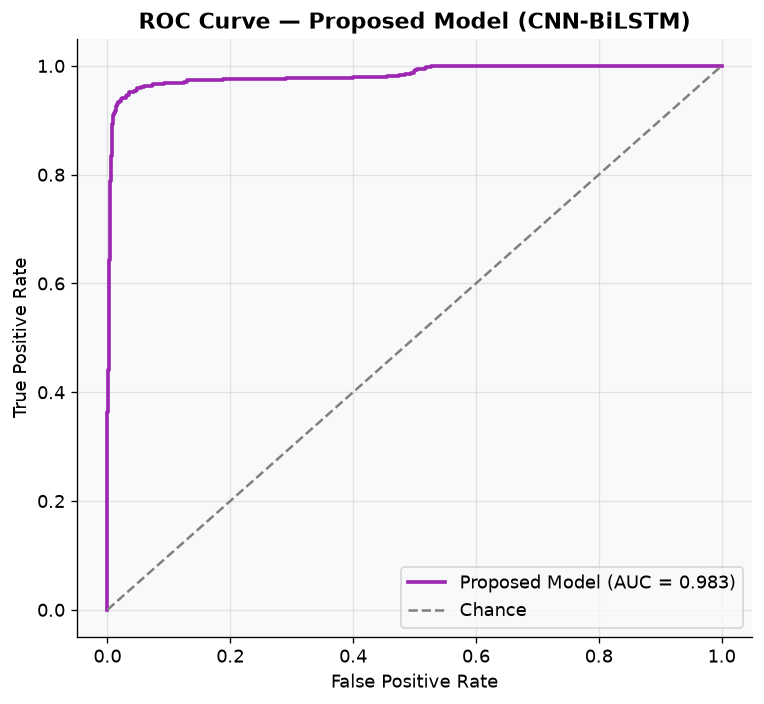

Figure 11 saved.


In [86]:
# ── Figure 11: ROC curve ───────────────────────────────────────
#old
#fpr, tpr, _ = roc_curve(y_true_test, y_prob_test)
#new
fpr, tpr, _ = roc_curve(y_true_test_s1, y_prob_test_s1)

fig, ax = plt.subplots(figsize=(6.5, 6))
#Fix3
#old
# ax.plot(fpr, tpr, color=COLORS['accent'], linewidth=2.2,
#         label=f"Dual-Stream (AUC = {dual_stream_results['ROC_AUC']:.3f})")
#new
####################################################################
ax.plot(fpr, tpr, color=COLORS['accent'], linewidth=2.2,
        label=f"Proposed Model (AUC = {roc_auc_score(y_true_test_s1, y_prob_test_s1):.3f})")
######################################################################

ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label="Chance")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
#old
#ax.set_title("Figure 11: ROC Curve - Dual-Stream Model", fontweight='bold')
ax.set_title("ROC Curve — Proposed Model (CNN-BiLSTM)", fontweight='bold')

ax.legend(loc='lower right')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig11_roc_curve.png", bbox_inches='tight', dpi=150)
plt.show()
print("Figure 11 saved.")

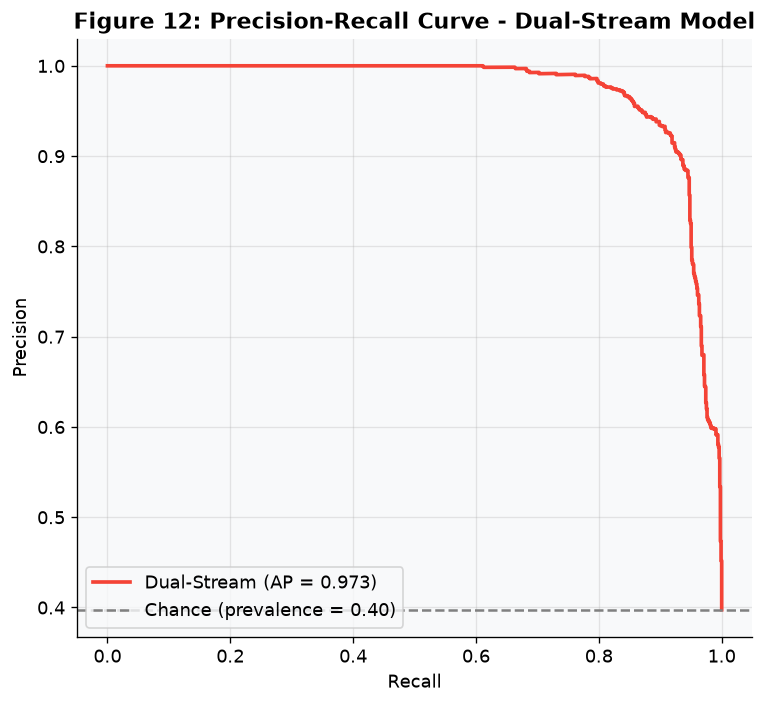

Figure 12 saved.


In [89]:
# ── Figure 12: Precision-Recall curve ─────────────────────────
precision_curve, recall_curve, _ = precision_recall_curve(y_true_test, y_prob_test)
fig, ax = plt.subplots(figsize=(6.5, 6))
PR_AUC = average_precision_score(y_true_test, y_prob_test)

ax.plot(
        recall_curve,
        precision_curve,
        color=COLORS['dysarthric'],
        linewidth=2.2,
        label=f"Dual-Stream (AP = {PR_AUC:.3f})"
)
baseline = y_true_test.mean()
ax.axhline(baseline, linestyle='--', color='gray', label=f"Chance (prevalence = {baseline:.2f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Figure 12: Precision-Recall Curve - Dual-Stream Model", fontweight='bold')
ax.legend(loc='lower left')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig12_pr_curve.png", bbox_inches='tight', dpi=150)
plt.show()
print("Figure 12 saved.")

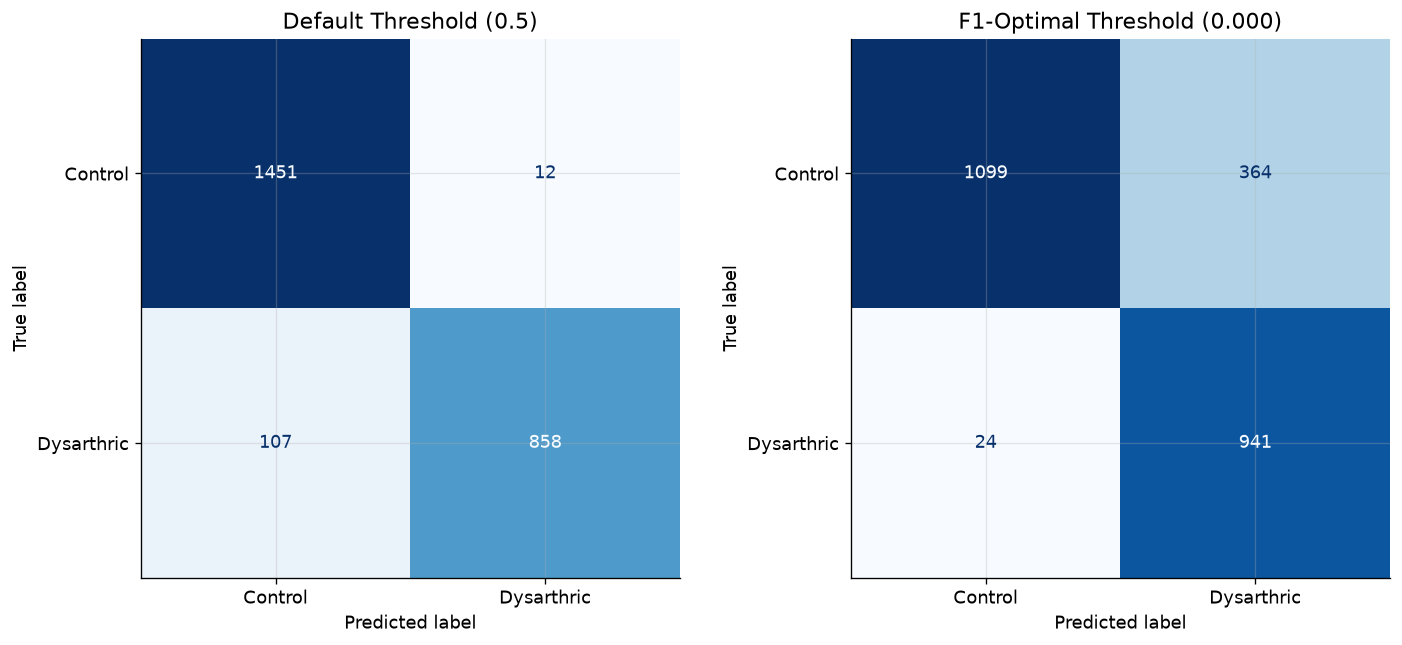

Figure 13 saved.


In [91]:
# ── Figure 13: Confusion matrices, with and without threshold optimisation ───
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
#fig.suptitle("Figure 13: Confusion Matrix - Default vs. F1-Optimal Threshold (Proposed Model)", fontsize=13, fontweight='bold')

if "Threshold" in ablation_stream1:
    STREAM1_THRESHOLD = float(ablation_stream1["Threshold"])
else:
    y_true_val_s1, y_prob_val_s1 = get_predictions(
        stream1_model, val_loader, device=DEVICE
    )
    STREAM1_THRESHOLD = find_optimal_threshold(y_true_val_s1, y_prob_val_s1)

for ax, thr, title in zip(
        axes, [0.5, STREAM1_THRESHOLD],
        ["Default Threshold (0.5)", f"F1-Optimal Threshold ({STREAM1_THRESHOLD:.3f})"]):
    y_pred_thr = (y_prob_test_s1 >= thr).astype(int)
    cm = confusion_matrix(y_true_test_s1, y_pred_thr)

    disp = ConfusionMatrixDisplay(cm, display_labels=["Control", "Dysarthric"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig13_confusion_matrices.png", bbox_inches='tight', dpi=150)
plt.show()
print("Figure 13 saved.")

In [92]:
def plot_calibration(y_true, y_prob, n_bins=10, model_name="Model", ax=None):
    '''
    Plot a reliability diagram and compute the Expected Calibration Error (ECE).

    ECE = sum_b (|B_b| / n) * |acc(B_b) - conf(B_b)|
    where B_b is the set of samples whose predicted probability falls in bin b,
    acc(B_b) is the empirical positive rate in that bin, and conf(B_b) is the
    mean predicted probability in that bin.

    Args:
        y_true: np.ndarray of 0/1 labels.
        y_prob: np.ndarray of predicted P(dysarthric).
        n_bins: int, number of equal-width probability bins.
        model_name: str, used in the plot title.
        ax: optional matplotlib Axes to draw on (creates a new figure if None).

    Returns:
        float, the Expected Calibration Error.
    '''
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
    bin_ids = np.clip(np.digitize(y_prob, bin_edges) - 1, 0, n_bins - 1)

    ece = 0.0
    bin_confidences, bin_accuracies, bin_counts = [], [], []
    for b in range(n_bins):
        mask = bin_ids == b
        count = mask.sum()
        if count == 0:
            continue
        acc_b = y_true[mask].mean()
        conf_b = y_prob[mask].mean()
        ece += (count / len(y_true)) * abs(acc_b - conf_b)
        bin_confidences.append(conf_b)
        bin_accuracies.append(acc_b)
        bin_counts.append(count)

    if ax is None:
        fig, ax = plt.subplots(figsize=(6.5, 6.5))

    ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect calibration')
    ax.plot(bin_confidences, bin_accuracies, marker='o', color=COLORS['accent'],
            linewidth=2, label=f'{model_name}')
    ax.fill_between(bin_confidences, bin_accuracies, bin_confidences,
                     color=COLORS['accent'], alpha=0.15)
    ax.set_xlabel("Mean Predicted Probability (Confidence)")
    ax.set_ylabel("Empirical Accuracy")
    ax.set_title(f"Reliability Diagram - {model_name}\nECE = {ece:.4f}", fontweight='bold')
    ax.legend(loc='upper left')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)

    return ece

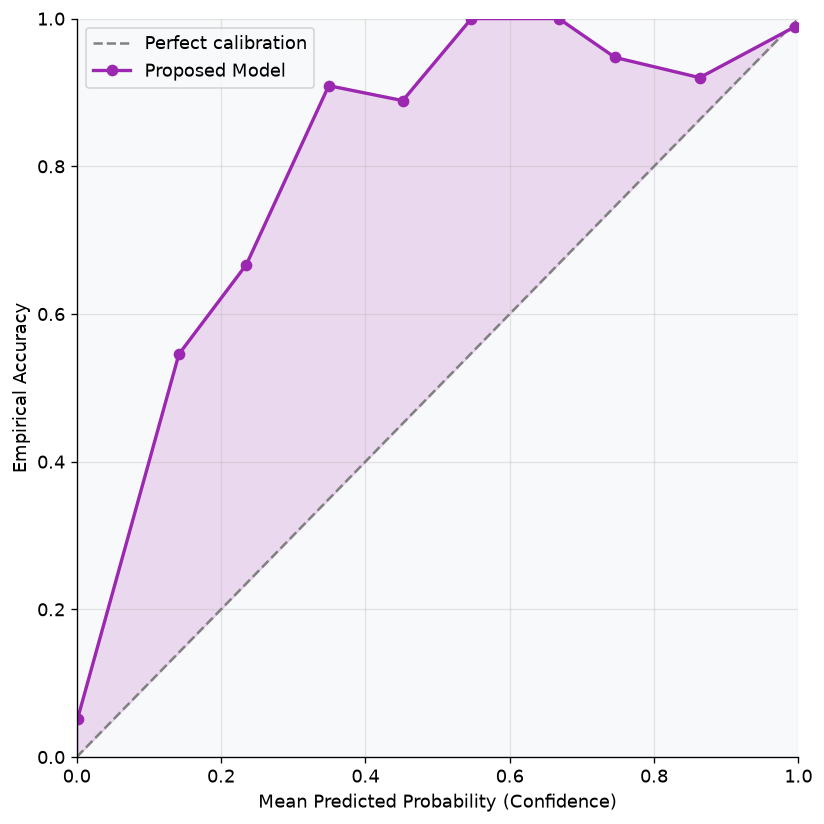

Figure 14 saved. Expected Calibration Error (ECE) = 0.0461


In [93]:
# ── Figure 14: reliability diagram with ECE annotation ────────
fig, ax = plt.subplots(figsize=(7, 7))

# Evaluates the Proposed Model (Stream 1) directly
test_ece = plot_calibration(y_true_test_s1, y_prob_test_s1, n_bins=10,
                             model_name="Proposed Model", ax=ax)

# Remove the title generated by the plot_calibration function
ax.set_title("")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig14_reliability_diagram.png", bbox_inches='tight', dpi=150)
plt.show()
print(f"Figure 14 saved. Expected Calibration Error (ECE) = {test_ece:.4f}")

In [94]:
def fairness_analysis(y_true, y_prob, y_pred, groups, group_labels=None, n_boot=N_BOOTSTRAP):
    '''
    Compare accuracy, F1, and ROC-AUC across demographic subgroups.

    Args:
        y_true: np.ndarray of 0/1 labels.
        y_prob: np.ndarray of predicted P(dysarthric).
        y_pred: np.ndarray of hard 0/1 predictions (post-threshold).
        groups: array-like of group labels (e.g. "male"/"female"), aligned with y_true.
        group_labels: optional list specifying/ordering which groups to report.
        n_boot: int, bootstrap resamples for each subgroup's CIs.

    Returns:
        pd.DataFrame with one row per group: N, Accuracy (+CI), F1 (+CI), ROC_AUC (+CI).
    '''
    groups = np.asarray(groups)
    group_labels = group_labels or sorted(set(groups))

    rows = []
    for g in group_labels:
        mask = groups == g
        n = int(mask.sum())
        if n == 0:
            continue
        yt, yp, ypr = y_true[mask], y_pred[mask], y_prob[mask]

        acc, acc_lo, acc_hi = bootstrap_ci(yt, yp, accuracy_score, n_boot=n_boot)
        f1, f1_lo, f1_hi = bootstrap_ci(
            yt, yp, lambda a, b: f1_score(a, b, zero_division=0), n_boot=n_boot)
        try:
            auc, auc_lo, auc_hi = bootstrap_ci(yt, ypr, roc_auc_score, n_boot=n_boot)
        except Exception:
            auc, auc_lo, auc_hi = np.nan, np.nan, np.nan

        rows.append({
            "Group": g, "N": n,
            "Accuracy": acc, "Accuracy_CI": (acc_lo, acc_hi),
            "F1": f1, "F1_CI": (f1_lo, f1_hi),
            "ROC_AUC": auc, "ROC_AUC_CI": (auc_lo, auc_hi),
        })

    return pd.DataFrame(rows)

In [96]:
# ── Run fairness analysis on the test set ─────────────────────
test_genders = meta.loc[test_idx, "gender"].values

stream1_threshold = ablation_stream1.get("Threshold")
if stream1_threshold is None:
    y_true_val_s1, y_prob_val_s1 = get_predictions(
        stream1_model, val_loader, device=DEVICE
    )
    stream1_threshold = find_optimal_threshold(y_true_val_s1, y_prob_val_s1)

y_pred_test_s1 = (y_prob_test_s1 >= stream1_threshold).astype(int)
fairness_df = fairness_analysis(
    y_true_test_s1,
    y_prob_test_s1,
    y_pred_test_s1,
    test_genders,
    group_labels=["female", "male"],
)

print("Gender subgroup performance (test set, 95% bootstrap CI):")
print(fairness_df.to_string(index=False))

Gender subgroup performance (test set, 95% bootstrap CI):
 Group    N  Accuracy                              Accuracy_CI       F1                                    F1_CI  ROC_AUC                              ROC_AUC_CI
female  805  0.632298 (0.6322981366459627, 0.6322981366459627) 0.000000                               (0.0, 0.0)      NaN                              (nan, nan)
  male 1623  0.943315 (0.9315927295132471, 0.9544208256315465) 0.953394 (0.9431570238937571, 0.9625448948178553) 0.989782 (0.9857113182612216, 0.993511534399996)


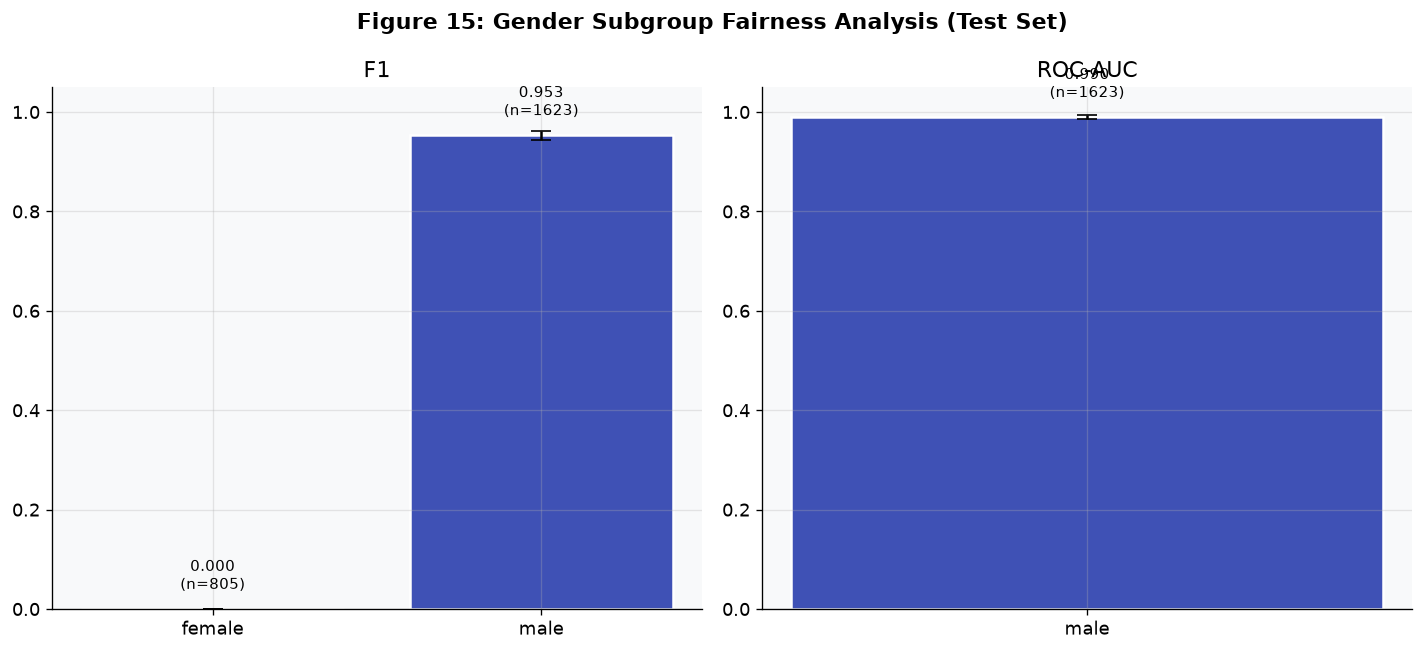

Figure 15 saved.


In [97]:
# ── Figure 15: grouped bar chart, male vs female F1/AUC with CI error bars ───
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle("Figure 15: Gender Subgroup Fairness Analysis (Test Set)", fontsize=13, fontweight='bold')

for ax, metric_name in zip(axes, ["F1", "ROC_AUC"]):
    values = fairness_df[metric_name].values
    ci_lo = np.array([ci[0] for ci in fairness_df[f"{metric_name}_CI"]])
    ci_hi = np.array([ci[1] for ci in fairness_df[f"{metric_name}_CI"]])
    errors = np.vstack([values - ci_lo, ci_hi - values])

    colors_bar = [COLORS['female'] if g == 'female' else COLORS['male'] for g in fairness_df["Group"]]
    bars = ax.bar(fairness_df["Group"], values, yerr=errors, capsize=6,
                  color=colors_bar, edgecolor='white', linewidth=1.5)
    ax.set_title(metric_name.replace("_", "-"))
    ax.set_ylim(0, 1.05)
    for bar, val, n in zip(bars, values, fairness_df["N"]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.03,
                f"{val:.3f}\n(n={n})", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig15_fairness_analysis.png", bbox_inches='tight', dpi=150)
plt.show()
print("Figure 15 saved.")

In [98]:
def add_snr_noise(audio, snr_db, sr=SAMPLE_RATE, rng=None):
    '''
    Add Gaussian noise to reach a specified SNR level (dB).

    Args:
        audio: 1-D np.ndarray, waveform.
        snr_db: float, target signal-to-noise ratio in decibels.
        sr: int, sample rate (unused directly, kept for interface consistency).
        rng: optional np.random.RandomState for reproducibility.

    Returns:
        np.ndarray, same shape as input, float32.
    '''
    rng = rng or np.random
    signal_power = np.mean(audio ** 2) + 1e-12
    noise_power = signal_power / (10 ** (snr_db / 10))
    noise = rng.normal(0, np.sqrt(noise_power), len(audio))
    return (audio + noise).astype(np.float32)

In [99]:
def snr_stress_test(model, test_metadata, snr_levels=SNR_LEVELS, threshold=0.5,
                     device=DEVICE, seed=SEED):
    '''
    Re-evaluate a trained model on the test set with audio degraded at each SNR level.

    Args:
        model: trained DualStreamDysarthriaModel.
        test_metadata: pd.DataFrame subset of `meta` for the test split
            (needs file_path, mic_type, label).
        snr_levels: list[float], SNR levels in dB to test (noisiest last).
        threshold: float, decision threshold applied to P(dysarthric).
        device: torch.device.
        seed: int, RNG seed for noise generation (reproducible degradation).

    Returns:
        pd.DataFrame with one row per SNR level: Accuracy, F1, ROC_AUC, N.
    '''
    rng = np.random.RandomState(seed)
    model.eval()
    rows = []

    for snr_db in snr_levels:
        logmel_list, traj_list, len_list, label_list = [], [], [], []
        for _, row in tqdm(test_metadata.iterrows(), total=len(test_metadata),
                            desc=f"SNR={snr_db}dB", leave=False):
            try:
                audio, _ = preprocess_audio(row["file_path"], row["mic_type"])
                noisy = add_snr_noise(audio, snr_db, rng=rng)
                logmel_list.append(extract_logmel(noisy))
                traj_list.append(extract_mfcc_trajectory(noisy))
                len_list.append(compute_valid_frames(noisy))
                label_list.append(int(row["label"]))
            except Exception as e:
                print(f"  [WARN] Skipping {row['file_path']} at {snr_db} dB ({e})")

        logmels_snr = np.stack(logmel_list).astype(np.float32)
        trajs_snr = np.stack(traj_list).astype(np.float32)
        lengths_snr = np.array(len_list, dtype=np.int64)
        labels_snr = np.array(label_list, dtype=np.int64)

        probs_list = []
        with torch.no_grad():
            for i in range(0, len(labels_snr), BATCH_SIZE):
                lm = torch.from_numpy(logmels_snr[i:i + BATCH_SIZE]).unsqueeze(1).to(device)
                tj = torch.from_numpy(trajs_snr[i:i + BATCH_SIZE]).to(device)
                ln = torch.from_numpy(lengths_snr[i:i + BATCH_SIZE]).to(device)
                dys_logits = model(lm, tj, ln)[0]
                probs_list.append(F.softmax(dys_logits, dim=1)[:, 1].cpu().numpy())

        probs_snr = np.concatenate(probs_list)
        preds_snr = (probs_snr >= threshold).astype(int)

        acc = accuracy_score(labels_snr, preds_snr)
        f1 = f1_score(labels_snr, preds_snr, zero_division=0)
        try:
            auc = roc_auc_score(labels_snr, probs_snr)
        except Exception:
            auc = np.nan

        rows.append({"SNR_dB": snr_db, "Accuracy": acc, "F1": f1, "ROC_AUC": auc, "N": len(labels_snr)})
        print(f"SNR={snr_db:>3} dB - Accuracy={acc:.4f} F1={f1:.4f} ROC_AUC={auc:.4f}")

    return pd.DataFrame(rows)

In [100]:
# ── Run the SNR stress test on the test split ─────────────────
test_metadata_snr = meta.loc[test_idx].reset_index(drop=True)
snr_results_df = snr_stress_test(model, test_metadata_snr, snr_levels=SNR_LEVELS,
                                  threshold=DECISION_THRESHOLD, device=DEVICE)
print("\nSNR stress test summary:")
print(snr_results_df.to_string(index=False))

SNR= 30 dB - Accuracy=0.5659 F1=0.5883 ROC_AUC=0.7424


SNR= 20 dB - Accuracy=0.4889 F1=0.4887 ROC_AUC=0.4692


SNR= 10 dB - Accuracy=0.4654 F1=0.5189 ROC_AUC=0.4313


SNR=  5 dB - Accuracy=0.4378 F1=0.5269 ROC_AUC=0.4434


SNR=  0 dB - Accuracy=0.4292 F1=0.5426 ROC_AUC=0.4578

SNR stress test summary:
 SNR_dB  Accuracy       F1  ROC_AUC    N
     30  0.565898 0.588281 0.742416 2428
     20  0.488880 0.488669 0.469162 2428
     10  0.465404 0.518903 0.431310 2428
      5  0.437809 0.526863 0.443350 2428
      0  0.429160 0.542574 0.457782 2428


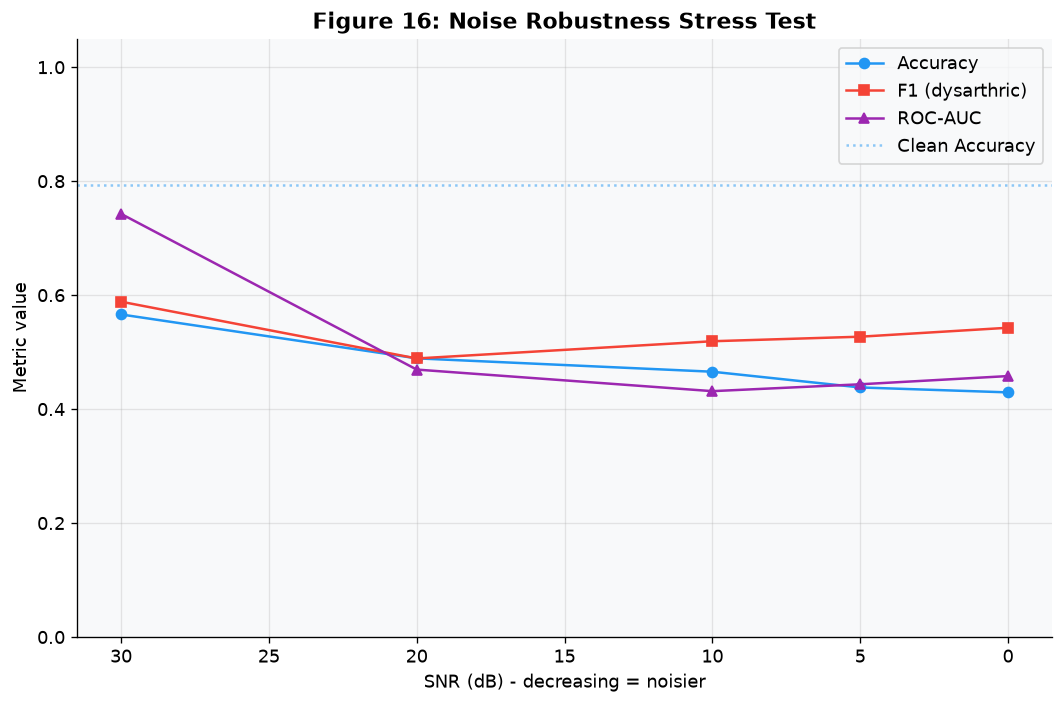

Figure 16 saved.


In [101]:
# ── Figure 16: Accuracy / F1 / AUC vs SNR level ───────────────
fig, ax = plt.subplots(figsize=(9, 6))
x = snr_results_df["SNR_dB"].values

ax.plot(x, snr_results_df["Accuracy"], marker='o', label="Accuracy", color=COLORS['control'])
ax.plot(x, snr_results_df["F1"], marker='s', label="F1 (dysarthric)", color=COLORS['dysarthric'])
ax.plot(x, snr_results_df["ROC_AUC"], marker='^', label="ROC-AUC", color=COLORS['accent'])

ax.axhline(dual_stream_results["Accuracy"], linestyle=':', color=COLORS['control'], alpha=0.5,
           label="Clean Accuracy")
ax.invert_xaxis()   # 30 dB (clean-ish) on the left -> 0 dB (very noisy) on the right
ax.set_xlabel("SNR (dB) - decreasing = noisier")
ax.set_ylabel("Metric value")
ax.set_title("Figure 16: Noise Robustness Stress Test", fontweight='bold')
ax.legend()
ax.set_ylim(0, 1.05)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig16_snr_stress_test.png", bbox_inches='tight', dpi=150)
plt.show()
print("Figure 16 saved.")

In [102]:
y_true_test_s1, y_prob_test_s1 = get_predictions(stream1_model, test_loader, device=DEVICE)

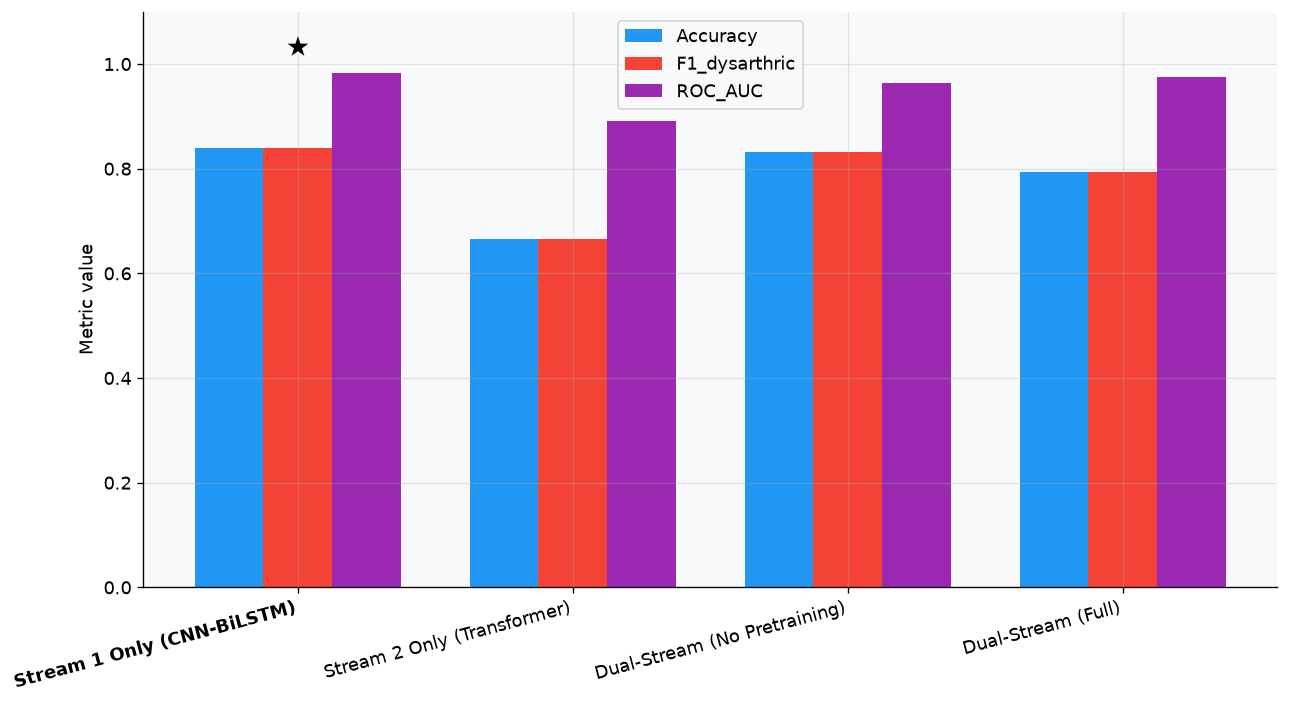

Figure 17 saved.


In [106]:
# ── Figure 17: ablation bar chart ─────────────────────────────
metric_names = ["Accuracy", "F1_dysarthric", "ROC_AUC"]
config_names = [r["Model"] for r in ablation_results]
def get_metric(result, metric_name):
    aliases = {
        "Accuracy": ["Accuracy", "accuracy"],
        "F1_dysarthric": ["F1_dysarthric", "F1 (Macro)", "F1", "f1"],
        "ROC_AUC": ["ROC_AUC", "ROC-AUC", "roc_auc"],
    }

    for key in aliases[metric_name]:
        if key in result:
            return float(result[key])

    raise KeyError(
        f"Missing {metric_name}. Available keys: {list(result.keys())}"
    )


values_matrix = np.array([
    [get_metric(result, metric) for metric in metric_names]
    for result in ablation_results
])

fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(config_names))
width = 0.25
palette = [COLORS['control'], COLORS['dysarthric'], COLORS['accent']]

for i, metric_name in enumerate(metric_names):
    ax.bar(x + (i - 1) * width, values_matrix[:, i], width, label=metric_name, color=palette[i])

ax.set_xticks(x)
ax.set_xticklabels(config_names, rotation=15, ha='right')

# Highlight the proposed model
for idx, (name, tick_label) in enumerate(zip(config_names, ax.get_xticklabels())):
    if "Stream 1" in name:
        tick_label.set_fontweight('bold')
        max_val = max(values_matrix[idx, :])
        ax.text(x[idx], max_val + 0.02, "★", ha='center', va='bottom', fontsize=16, color='black')

ax.set_ylabel("Metric value")
ax.set_ylim(0, 1.1)
#ax.set_title("Figure 17: Ablation Study - Test Set Performance", fontweight='bold')
ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig17_ablation_study.png", bbox_inches='tight', dpi=150)
plt.show()
print("Figure 17 saved.")

In [107]:
def plot_embedding_space(embeddings, labels, genders, speakers, title="Embedding Space"):
    '''
    Plot PCA (2D) and t-SNE (2D) projections of fused embeddings, each colored
    by (a) dysarthria label, (b) gender, (c) speaker ID.

    Args:
        embeddings: np.ndarray, shape (N, 256).
        labels: np.ndarray of 0/1 dysarthria labels, shape (N,).
        genders: np.ndarray of 0/1 gender codes (0=female, 1=male), shape (N,).
        speakers: array-like of speaker ID strings, shape (N,).
        title: str, figure suptitle.

    Returns:
        matplotlib.figure.Figure
    '''
    pca_proj = PCA(n_components=2, random_state=SEED).fit_transform(embeddings)
    perplexity = min(30, max(5, len(embeddings) // 4 - 1))
    tsne_proj = TSNE(n_components=2, random_state=SEED, perplexity=perplexity).fit_transform(embeddings)

    fig, axes = plt.subplots(2, 3, figsize=(17, 10))
    fig.suptitle(title, fontsize=15, fontweight='bold')

    for row, (proj_name, proj) in enumerate([("PCA", pca_proj), ("t-SNE", tsne_proj)]):
        ax = axes[row, 0]
        for val, color, name in [(0, COLORS['control'], "Control"), (1, COLORS['dysarthric'], "Dysarthric")]:
            m = labels == val
            ax.scatter(proj[m, 0], proj[m, 1], color=color, label=name, alpha=0.7, s=20)
        ax.set_title(f"{proj_name} - by Dysarthria Label")
        if row == 0: ax.legend(fontsize=8)

        ax = axes[row, 1]
        for val, color, name in [(0, COLORS['female'], "Female"), (1, COLORS['male'], "Male")]:
            m = genders == val
            ax.scatter(proj[m, 0], proj[m, 1], color=color, label=name, alpha=0.7, s=20)
        ax.set_title(f"{proj_name} - by Gender")
        if row == 0: ax.legend(fontsize=8)

        ax = axes[row, 2]
        unique_speakers = sorted(set(speakers))
        palette = sns.color_palette("husl", len(unique_speakers))
        for spk, color in zip(unique_speakers, palette):
            m = speakers == spk
            ax.scatter(proj[m, 0], proj[m, 1], color=color, label=spk, alpha=0.7, s=20)
        ax.set_title(f"{proj_name} - by Speaker")
        if row == 0: ax.legend(fontsize=6, ncol=2)

    plt.tight_layout()
    return fig

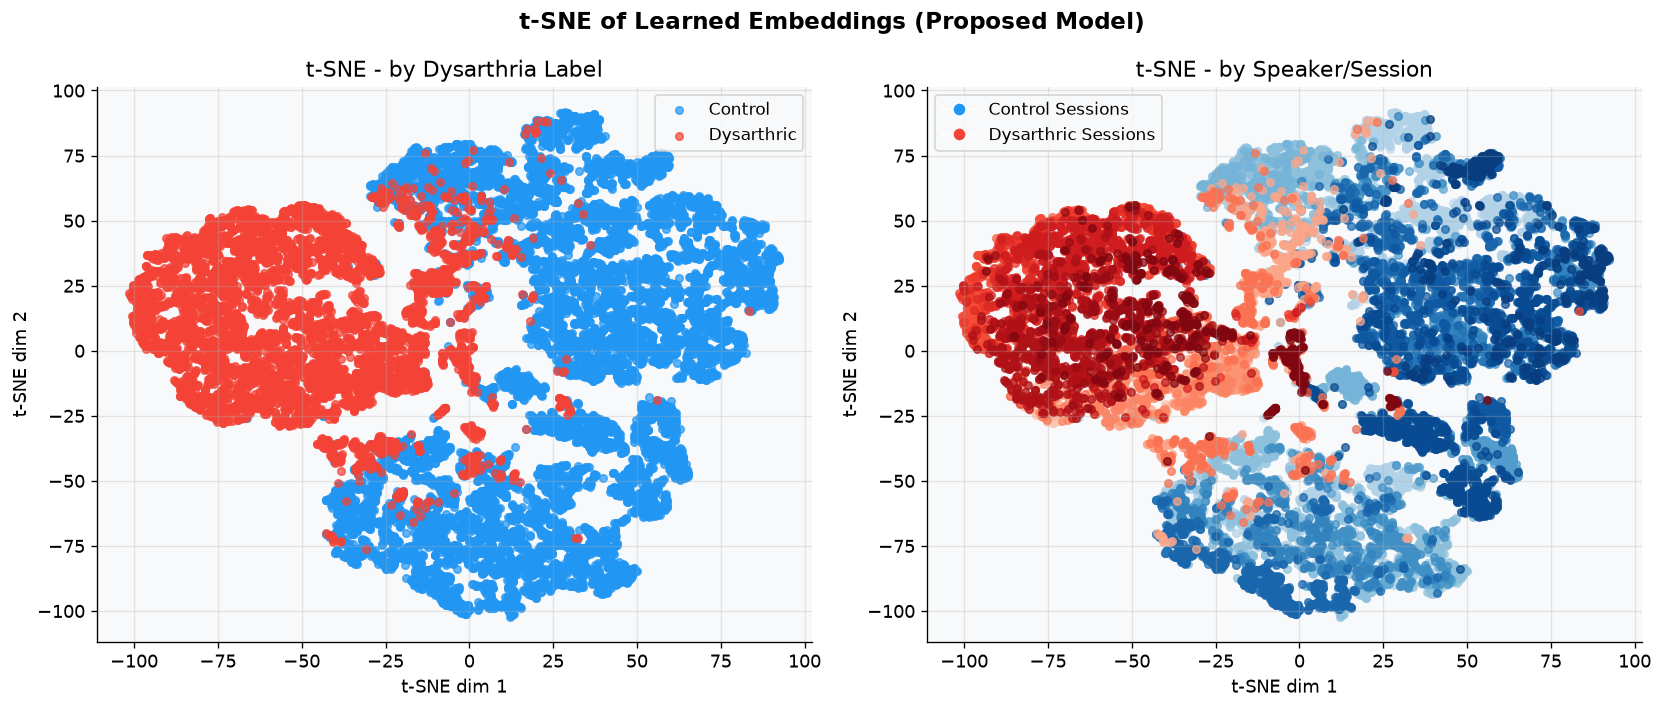

Figure 18 saved.


In [108]:
# ── Figure 18: t-SNE of embeddings across the full dataset ───────
from sklearn.manifold import TSNE
from matplotlib.lines import Line2D
import torch

full_dataset = TORGODualStreamDataset(
    logmels, trajs, meta["label"].values, meta["gender"].values,
    lengths=meta["valid_frames"].values, augment=False)
full_loader = DataLoader(full_dataset, batch_size=BATCH_SIZE, shuffle=False)

stream1_model.eval()
full_embeddings = []
with torch.no_grad():
    for logmel_b, traj_b, len_b, _, _ in full_loader:
        logmel_b, traj_b, len_b = logmel_b.to(DEVICE), traj_b.to(DEVICE), len_b.to(DEVICE)
        # Call get_embedding on Stream 1 model
        full_embeddings.append(stream1_model.get_embedding(logmel_b, traj_b, len_b).cpu().numpy())
full_embeddings = np.concatenate(full_embeddings, axis=0)

full_labels = meta["label"].values
full_speakers = meta["speaker_id"].values

# Calculate t-SNE
perplexity = min(30, max(5, len(full_embeddings) // 4 - 1))
tsne_proj = TSNE(n_components=2, random_state=SEED, perplexity=perplexity).fit_transform(full_embeddings)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("t-SNE of Learned Embeddings (Proposed Model)", fontsize=14, fontweight='bold')

# Panel 1: by Dysarthria Label
ax = axes[0]
for val, color, name in [(0, COLORS['control'], "Control"), (1, COLORS['dysarthric'], "Dysarthric")]:
    m = full_labels == val
    ax.scatter(tsne_proj[m, 0], tsne_proj[m, 1], color=color, label=name, alpha=0.7, s=20)
ax.set_title("t-SNE - by Dysarthria Label")
ax.set_xlabel("t-SNE dim 1")
ax.set_ylabel("t-SNE dim 2")
ax.legend(fontsize=10)

# Panel 2: by Speaker (grouped by class)
ax = axes[1]
control_speakers = sorted(set(full_speakers[full_labels == 0]))
dysarthric_speakers = sorted(set(full_speakers[full_labels == 1]))

# Create distinct palettes for each group to separate individual sessions visually
control_palette = sns.color_palette("Blues", len(control_speakers) + 3)[3:]
dysarthric_palette = sns.color_palette("Reds", len(dysarthric_speakers) + 3)[3:]

for spk, color in zip(control_speakers, control_palette):
    m = full_speakers == spk
    ax.scatter(tsne_proj[m, 0], tsne_proj[m, 1], color=color, alpha=0.7, s=20)

for spk, color in zip(dysarthric_speakers, dysarthric_palette):
    m = full_speakers == spk
    ax.scatter(tsne_proj[m, 0], tsne_proj[m, 1], color=color, alpha=0.7, s=20)

# Create simplified legend grouping the sessions
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor=COLORS['control'], markersize=8, label='Control Sessions'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor=COLORS['dysarthric'], markersize=8, label='Dysarthric Sessions')
]
ax.set_title("t-SNE - by Speaker/Session")
ax.set_xlabel("t-SNE dim 1")
ax.set_ylabel("t-SNE dim 2")
ax.legend(handles=legend_elements, fontsize=10)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig18_embedding_space.png", bbox_inches='tight', dpi=150)
plt.show()
print("Figure 18 saved.")

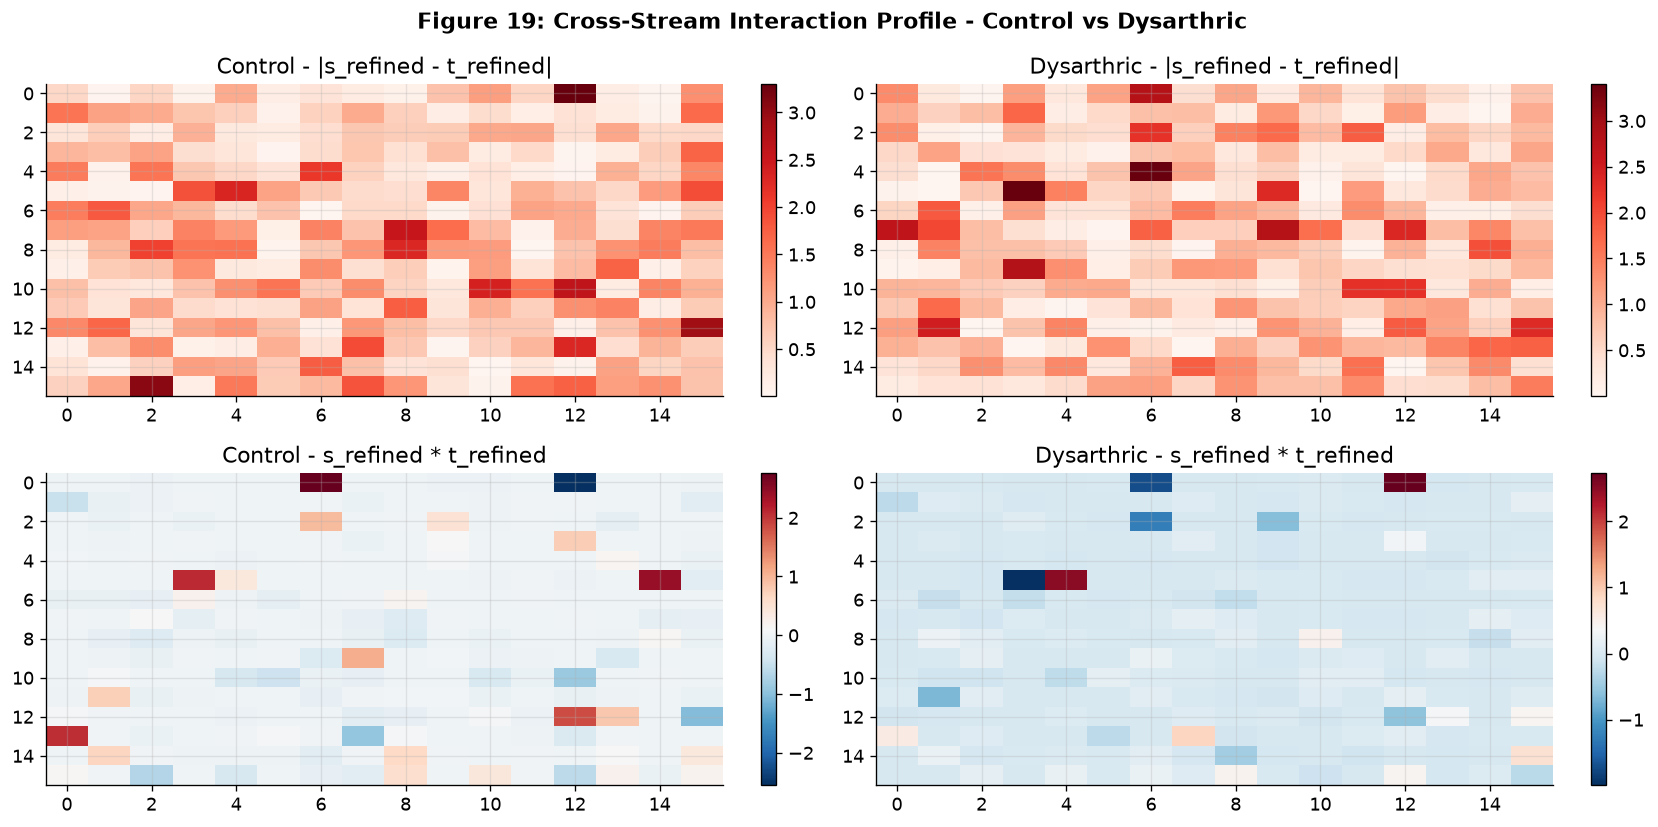

Figure 19 saved.


In [111]:
# ── Figure 19: cross-stream interaction profile, dysarthric vs control ───────
ctrl_row = meta[(meta["label"] == 0)].iloc[[0]]
dys_row = meta[(meta["label"] == 1)].iloc[[0]]
sample_pair = pd.concat([ctrl_row, dys_row])

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
fig.suptitle("Figure 19: Cross-Stream Interaction Profile - Control vs Dysarthric",
             fontsize=13, fontweight='bold')

model.eval()
for col, (_, row) in enumerate(sample_pair.iterrows()):
    idx = row.name
    logmel_s = torch.from_numpy(logmels[idx:idx+1]).unsqueeze(1).to(DEVICE)
    traj_s = torch.from_numpy(trajs[idx:idx+1]).to(DEVICE)
    len_s = torch.tensor([int(meta.loc[idx, "valid_frames"])]).to(DEVICE)

    with torch.no_grad():
        s_refined = model.spectro_encoder(logmel_s, len_s)
        t_refined = model.traj_encoder(traj_s, len_s)

        # Element-wise cross-stream interaction profiles.
        diff = torch.abs(s_refined - t_refined)
        prod = s_refined * t_refined
    diff = diff.cpu().numpy().reshape(16, 16)
    prod = prod.cpu().numpy().reshape(16, 16)

    label_name = "Dysarthric" if row["label"] == 1 else "Control"

    im0 = axes[0, col].imshow(diff, cmap="Reds", aspect='auto')
    axes[0, col].set_title(f"{label_name} - |s_refined - t_refined|")
    fig.colorbar(im0, ax=axes[0, col], fraction=0.046)

    im1 = axes[1, col].imshow(prod, cmap="RdBu_r", aspect='auto')
    axes[1, col].set_title(f"{label_name} - s_refined * t_refined")
    fig.colorbar(im1, ax=axes[1, col], fraction=0.046)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig19_interaction_profile.png", bbox_inches='tight', dpi=150)
plt.show()
print("Figure 19 saved.")

In [112]:
def extract_advanced_features(audio, sr, n_mfcc=N_MFCC):
    '''
    Extract 126 acoustic features from a preprocessed audio clip.

    Feature groups
    --------------
    1. MFCCs                -> captures vocal-tract shape
    2. Delta-MFCCs          -> 1st derivative: rate of articulatory change
    3. Delta-Delta MFCCs    -> 2nd derivative: acceleration of articulation
    4. Zero-Crossing Rate   -> voiced vs. unvoiced ratio (roughness measure)
    5. RMS Energy           -> loudness variability across time
    6. Spectral Centroid    -> brightness / average frequency
    7. Spectral Bandwidth   -> frequency spread around centroid
    8. Spectral Rolloff     -> high-frequency energy concentration
    9. Spectral Contrast    -> proxy for Harmonic-to-Noise Ratio (HNR)
    10. Chroma              -> pitch-class energy (phoneme information)

    Returns: 1-D numpy array of shape (126,)
    '''
    feature_parts = []

    # 1. Base MFCCs
    mfccs = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=n_mfcc)
    feature_parts += [np.mean(mfccs, axis=1), np.std(mfccs, axis=1)]

    # 2. Delta-MFCCs (velocity of spectral change)
    delta_mfccs = _safe_librosa_delta(mfccs, order=1)
    feature_parts += [np.mean(delta_mfccs, axis=1), np.std(delta_mfccs, axis=1)]

    # 3. Delta-Delta MFCCs (acceleration of spectral change)
    delta2_mfccs = _safe_librosa_delta(mfccs, order=2)
    feature_parts += [np.mean(delta2_mfccs, axis=1), np.std(delta2_mfccs, axis=1)]

    # 4. Zero-Crossing Rate - captures consonant/fricative energy
    zcr = librosa.feature.zero_crossing_rate(audio)
    feature_parts += [np.array([np.mean(zcr)]), np.array([np.std(zcr)])]

    # 5. RMS Energy - dysarthric speakers show more energy variability
    rms = librosa.feature.rms(y=audio)
    feature_parts += [np.array([np.mean(rms)]), np.array([np.std(rms)])]

    # 6. Spectral Centroid - average spectral brightness
    cent = librosa.feature.spectral_centroid(y=audio, sr=sr)
    feature_parts += [np.array([np.mean(cent)]), np.array([np.std(cent)])]

    # 7. Spectral Bandwidth - how spread out the spectrum is
    bw = librosa.feature.spectral_bandwidth(y=audio, sr=sr)
    feature_parts += [np.array([np.mean(bw)]), np.array([np.std(bw)])]

    # 8. Spectral Rolloff - frequency below which 85% of energy lies
    rolloff = librosa.feature.spectral_rolloff(y=audio, sr=sr)
    feature_parts += [np.array([np.mean(rolloff)]), np.array([np.std(rolloff)])]

    # 9. Spectral Contrast - proxy for HNR across 7 sub-bands
    contrast = librosa.feature.spectral_contrast(y=audio, sr=sr)
    feature_parts += [np.mean(contrast, axis=1), np.std(contrast, axis=1)]

    # 10. Chroma - 12 pitch-class energies (vowel/consonant distinctions)
    chroma = librosa.feature.chroma_stft(y=audio, sr=sr)
    feature_parts += [np.mean(chroma, axis=1), np.std(chroma, axis=1)]

    return np.concatenate(feature_parts).astype(np.float32)

In [113]:
# =====================================================================
# 17a. Hand-crafted feature extraction — incremental cache
# =====================================================================
def extract_classical_features_matrix(
    meta_df, cache_path=None, force_recompute=False
):
    """
    Extract the exact original V3 126-dim feature vector for every recording.

    Successful recordings are cached individually. Failed recordings are not
    cached, so they are retried automatically on the next complete notebook run.
    """
    cache_path = cache_path or CLASSICAL_FEATURE_CACHE_PATH
    source_signature = dataframe_signature(
        meta_df, ["file_path", "mic_type", "label", "speaker_id", "gender"]
    )
    manifest_path = cache_path + ".manifest.json"

    if (
        (not force_recompute)
        and os.path.exists(cache_path)
        and os.path.exists(manifest_path)
    ):
        try:
            with open(manifest_path, "r", encoding="utf-8") as f:
                manifest = json.load(f)
            if (
                manifest.get("pipeline_signature") == PIPELINE_SIGNATURE
                and manifest.get("source_signature") == source_signature
                and manifest.get("complete") is True
            ):
                print(f"[CACHE] Loaded complete classical feature matrix: {cache_path}")
                return np.load(cache_path).astype(np.float32)
        except Exception as e:
            print("[CACHE] Classical aggregate cache could not be trusted:", e)

    feats = []
    n_cached = 0
    n_new = 0
    n_errors = 0

    for _, row in tqdm(
        meta_df.iterrows(),
        total=len(meta_df),
        desc="Classical features / cache",
    ):
        extra = {
            "sr": SAMPLE_RATE,
            "n_mfcc": N_MFCC,
            "hop_length": HOP_LENGTH,
            "win_length": WIN_LENGTH,
        }
        key = file_cache_key(row["file_path"], "classical_features", extra)
        shard_path = os.path.join(CLASSICAL_SHARD_DIR, f"{key}.npy")

        try:
            if os.path.exists(shard_path) and not force_recompute:
                feat = np.load(shard_path).astype(np.float32)
                n_cached += 1
            else:
                audio, sr = preprocess_audio(
                    row["file_path"], row["mic_type"]
                )
                feat = extract_advanced_features(audio, sr)
                if not np.isfinite(feat).all():
                    raise ValueError("non-finite classical features")
                atomic_numpy_save(feat.astype(np.float32), shard_path)
                n_new += 1

            feats.append(feat)

        except Exception as e:
            n_errors += 1
            print(f"  [WARN] Could not process {row['file_path']}: {e}")
            feats.append(np.full(126, np.nan, dtype=np.float32))

    if not feats:
        raise RuntimeError(
            "No classical features were produced. Fix the preprocessing/data issue and rerun."
        )

    X = np.vstack(feats).astype(np.float32)
    complete = (n_errors == 0)

    atomic_numpy_save(X, cache_path)
    atomic_json_dump(
        {
            "pipeline_signature": PIPELINE_SIGNATURE,
            "source_signature": source_signature,
            "complete": complete,
            "n_input": int(len(meta_df)),
            "n_output": int(len(X)),
            "n_cached_shards_used": int(n_cached),
            "n_new_shards_created": int(n_new),
            "n_errors": int(n_errors),
        },
        manifest_path,
    )

    print(
        f"Classical features ready: {len(X)} rows; "
        f"cached={n_cached}, newly processed={n_new}, errors={n_errors}."
    )
    if n_errors:
        raise RuntimeError(
            f"{n_errors} audio file(s) could not be processed for classical features. "
            "Successful feature vectors are already cached individually. Fix the issue "
            "and rerun; V4 will retry only the failed files."
        )
    return X


In [114]:
# =====================================================================
# 17b. Extract classical features
# =====================================================================
X_classical = extract_classical_features_matrix(
    meta,
    cache_path=CLASSICAL_FEATURE_CACHE_PATH,
    force_recompute=False,
)

valid_mask = ~np.isnan(X_classical).any(axis=1)
print(f"Classical features valid for {valid_mask.sum()} / {len(valid_mask)} utterances.")

train_idx_c = train_idx[valid_mask[train_idx]]
val_idx_c = val_idx[valid_mask[val_idx]]
test_idx_c = test_idx[valid_mask[test_idx]]

X_train_c = X_classical[train_idx_c]
y_train_c = meta.loc[train_idx_c, "label"].values
X_val_c = X_classical[val_idx_c]
y_val_c = meta.loc[val_idx_c, "label"].values
X_test_c = X_classical[test_idx_c]
y_test_c = meta.loc[test_idx_c, "label"].values

print(
    f"Classical train/val/test sizes: "
    f"{len(y_train_c)} / {len(y_val_c)} / {len(y_test_c)}"
)


Classical features / cache: 100%|██████████| 17631/17631 [02:53<00:00, 101.36it/s]

Classical features ready: 17631 rows; cached=0, newly processed=17631, errors=0.
Classical features valid for 17631 / 17631 utterances.
Classical train/val/test sizes: 13199 / 2004 / 2428


In [115]:
# =====================================================================
# 17c. Leakage-safe scaling and feature selection — cached
# =====================================================================
scaler_selector_source = dataframe_signature(
    pd.DataFrame({"idx": train_idx_c, "label": y_train_c}),
    ["idx", "label"],
)

_loaded_ss = None
if os.path.exists(SCALER_SELECTOR_CACHE_PATH):
    try:
        _loaded_ss = pickle.load(open(SCALER_SELECTOR_CACHE_PATH, "rb"))
    except Exception:
        _loaded_ss = None

if (
    _loaded_ss
    and _loaded_ss.get("pipeline_signature") == PIPELINE_SIGNATURE
    and _loaded_ss.get("source_signature") == scaler_selector_source
):
    scaler = _loaded_ss["scaler"]
    selector = _loaded_ss["selector"]
    K_FEATURES = int(_loaded_ss["K_FEATURES"])
    print("[CACHE] Loaded train-only scaler and feature selector.")
else:
    scaler = StandardScaler().fit(X_train_c)
    X_train_scaled = scaler.transform(X_train_c)
    K_FEATURES = min(60, X_train_scaled.shape[1])
    selector = SelectKBest(
        f_classif, k=K_FEATURES
    ).fit(X_train_scaled, y_train_c)

    atomic_pickle_dump(
        {
            "pipeline_signature": PIPELINE_SIGNATURE,
            "source_signature": scaler_selector_source,
            "scaler": scaler,
            "selector": selector,
            "K_FEATURES": K_FEATURES,
        },
        SCALER_SELECTOR_CACHE_PATH,
    )
    print("[CACHE] Created train-only scaler and feature selector.")

X_train_scaled = scaler.transform(X_train_c)
X_val_scaled = scaler.transform(X_val_c)
X_test_scaled = scaler.transform(X_test_c)

X_train_sel = selector.transform(X_train_scaled)
X_val_sel = selector.transform(X_val_scaled)
X_test_sel = selector.transform(X_test_scaled)

print(
    f"Selected {K_FEATURES} / {X_train_scaled.shape[1]} features "
    "via ANOVA F-score (train-only fit)."
)


[CACHE] Created train-only scaler and feature selector.
Selected 60 / 126 features via ANOVA F-score (train-only fit).


In [116]:
# =====================================================================
# 17d. Classical baselines — cached
# =====================================================================
def build_classical_models(X_train, y_train, seed=SEED):
    models = {}

    models["SVM (RBF)"] = SVC(
        kernel="rbf",
        class_weight="balanced",
        probability=True,
        random_state=seed,
    ).fit(X_train, y_train)

    models["Random Forest"] = RandomForestClassifier(
        n_estimators=500,
        class_weight="balanced",
        random_state=seed,
        n_jobs=-1,
    ).fit(X_train, y_train)

    stacking = StackingClassifier(
        estimators=[
            (
                "svm",
                SVC(
                    kernel="rbf",
                    probability=True,
                    class_weight="balanced",
                    random_state=seed,
                ),
            ),
            (
                "rf",
                RandomForestClassifier(
                    n_estimators=300,
                    class_weight="balanced",
                    random_state=seed,
                ),
            ),
        ],
        final_estimator=LogisticRegression(max_iter=1000),
        cv=5,
        n_jobs=-1,
    ).fit(X_train, y_train)

    models["Stacking Ensemble"] = stacking
    return models


classical_source = dataframe_signature(
    pd.DataFrame({
        "idx": train_idx_c,
        "label": y_train_c,
    }),
    ["idx", "label"],
)

_classical_bundle = None
if os.path.exists(CLASSICAL_MODELS_CACHE_PATH):
    try:
        _classical_bundle = pickle.load(
            open(CLASSICAL_MODELS_CACHE_PATH, "rb")
        )
    except Exception:
        _classical_bundle = None

if (
    _classical_bundle
    and _classical_bundle.get("pipeline_signature") == PIPELINE_SIGNATURE
    and _classical_bundle.get("source_signature") == classical_source
):
    classical_models = _classical_bundle["models"]
    print("[CACHE] Loaded classical baseline models.")
else:
    classical_models = build_classical_models(
        X_train_sel, y_train_c
    )
    atomic_pickle_dump(
        {
            "pipeline_signature": PIPELINE_SIGNATURE,
            "source_signature": classical_source,
            "models": classical_models,
        },
        CLASSICAL_MODELS_CACHE_PATH,
    )
    print("[CACHE] Trained and cached classical baseline models.")

print("Classical models:", list(classical_models.keys()))


[CACHE] Trained and cached classical baseline models.
Classical models: ['SVM (RBF)', 'Random Forest', 'Stacking Ensemble']


In [117]:
# =====================================================================
# 17e. Classical evaluation — cached
# =====================================================================
CLASSICAL_RESULTS_CACHE_PATH = os.path.join(
    STAGE_DIR, "classical_results.pkl"
)

if os.path.exists(CLASSICAL_RESULTS_CACHE_PATH):
    try:
        _cr = pickle.load(open(CLASSICAL_RESULTS_CACHE_PATH, "rb"))
    except Exception:
        _cr = None
else:
    _cr = None

if (
    _cr
    and _cr.get("pipeline_signature") == PIPELINE_SIGNATURE
    and _cr.get("source_signature") == classical_source
):
    classical_results = _cr["results"]
    print("[CACHE] Loaded classical evaluation results.")
else:
    classical_results = []
    for name, clf in classical_models.items():
        val_probs = clf.predict_proba(X_val_sel)[:, 1]
        thr = find_optimal_threshold(y_val_c, val_probs)
        test_probs = clf.predict_proba(X_test_sel)[:, 1]
        res = evaluate_model_full(
            y_test_c,
            test_probs,
            threshold=thr,
            model_name=name,
        )
        classical_results.append(res)

    atomic_pickle_dump(
        {
            "pipeline_signature": PIPELINE_SIGNATURE,
            "source_signature": classical_source,
            "results": classical_results,
        },
        CLASSICAL_RESULTS_CACHE_PATH,
    )
    print("[CACHE] Computed and cached classical evaluation results.")

classical_df = pd.DataFrame(
    [format_ci_row(r) for r in classical_results]
)
print(
    "Classical baseline performance (test set, 95% bootstrap CI):"
)
print(classical_df.to_string(index=False))


--- Evaluation Results: SVM (RBF) ---
              precision    recall  f1-score   support

     Control       1.00      0.18      0.30      1463
  Dysarthric       0.45      1.00      0.62       965

    accuracy                           0.51      2428
   macro avg       0.72      0.59      0.46      2428
weighted avg       0.78      0.51      0.43      2428

--- Evaluation Results: Random Forest ---
              precision    recall  f1-score   support

     Control       1.00      0.06      0.11      1463
  Dysarthric       0.41      1.00      0.58       965

    accuracy                           0.43      2428
   macro avg       0.71      0.53      0.35      2428
weighted avg       0.77      0.43      0.30      2428

--- Evaluation Results: Stacking Ensemble ---
              precision    recall  f1-score   support

     Control       1.00      0.00      0.00      1463
  Dysarthric       0.40      1.00      0.57       965

    accuracy                           0.40      2428
  

Final comparison table (point estimates):
                            Accuracy  F1_dysarthric  ROC_AUC  PR_AUC   Brier
Model                                                                       
SVM (RBF)                     0.5054         0.4601   0.9707  0.9588  0.0693
Random Forest                 0.4329         0.3473   0.9861  0.9810  0.0682
Stacking Ensemble             0.3979         0.2852   0.9764  0.9678  0.0909
Stream 1 Only (CNN-BiLSTM)    0.8402         0.8395   0.9835  0.9812  0.0437
Dual-Stream (Full)            0.7937         0.7936   0.9760  0.9729  0.0568


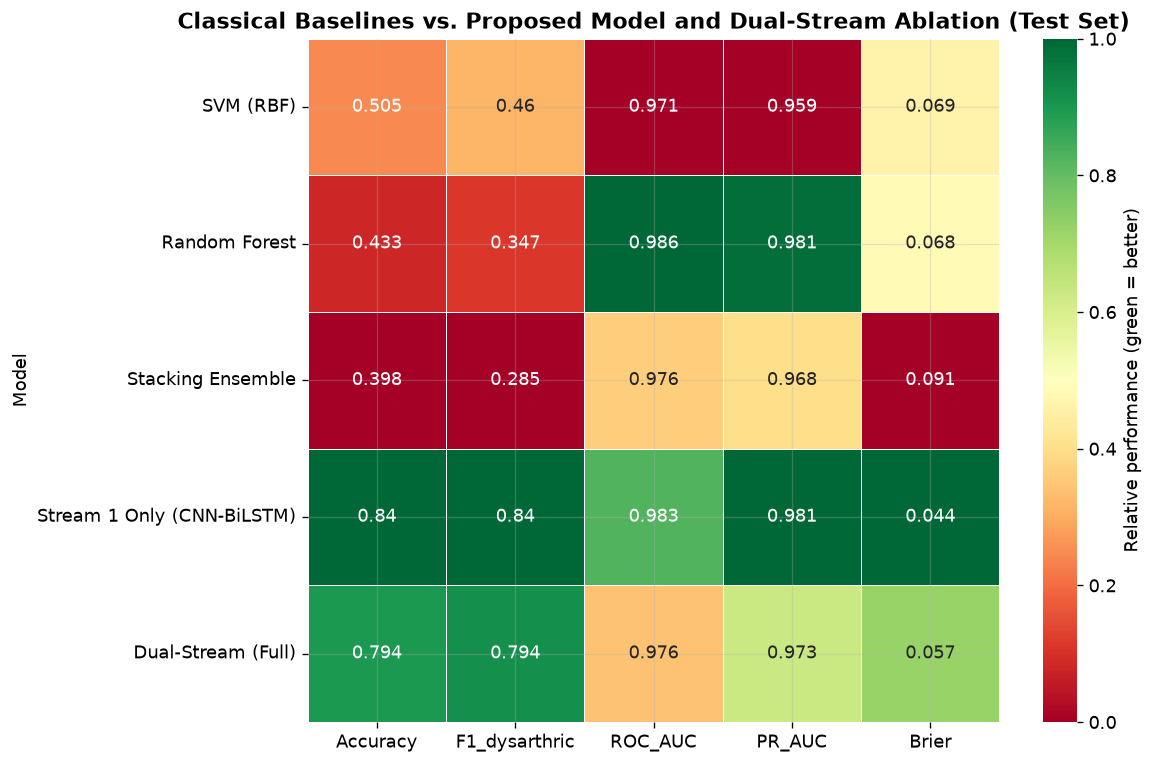

Figure 20 saved.


In [124]:
# ── Figure 20: final comparison table/heatmap - classical vs dual-stream ─────
#Fix7
#old
#comparison_all = classical_results + [dual_stream_results]
#new
comparison_all = classical_results + [ablation_stream1, dual_stream_results]

metric_cols = ["Accuracy", "F1_dysarthric", "ROC_AUC", "PR_AUC", "Brier"]

def metric_value(result, metric):
    aliases = {
        "Accuracy": ["Accuracy", "accuracy"],
        "F1_dysarthric": ["F1_dysarthric", "F1", "F1 (Macro)", "f1"],
        "ROC_AUC": ["ROC_AUC", "ROC-AUC", "roc_auc"],
        "PR_AUC": ["PR_AUC", "PR-AUC", "average_precision"],
        "Brier": ["Brier", "Brier Score"],
    }

    for key in aliases[metric]:
        if key in result:
            return float(result[key])

    raise KeyError(
        f"{metric} is missing for {result.get('Model', 'unknown model')}. "
        f"Available keys: {list(result.keys())}"
    )


heat_data = pd.DataFrame(
    [
        {
            "Model": r["Model"],
            **{m: metric_value(r, m) for m in metric_cols},
        }
        for r in comparison_all
    ]
).set_index("Model")

print("Final comparison table (point estimates):")
print(heat_data.round(4).to_string())

# Min-max normalise each column for coloring only (Brier inverted: lower is better)
norm_data = (heat_data - heat_data.min()) / (heat_data.max() - heat_data.min() + 1e-12)
norm_data["Brier"] = 1 - norm_data["Brier"]

fig, ax = plt.subplots(figsize=(10, 0.9 * len(heat_data) + 2))
sns.heatmap(norm_data, annot=heat_data.round(3), fmt="", cmap="RdYlGn",
            cbar_kws={"label": "Relative performance (green = better)"}, ax=ax,
            linewidths=0.5, linecolor='white')
#old
# ax.set_title("Figure 20: Classical Baselines vs. Dual-Stream Model (Test Set)", fontweight='bold')

#new
ax.set_title("Classical Baselines vs. Proposed Model and Dual-Stream Ablation (Test Set)", fontweight='bold')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig20_final_comparison.png", bbox_inches='tight', dpi=150)
plt.show()
print("Figure 20 saved.")

In [125]:
def extract_silence_segments(file_path, mic_type, sr=SAMPLE_RATE, min_silence_ms=200):
    '''
    Extract the non-speech (silent/noise) portions of an audio file - the
    inverse of what preprocess_audio's trimming step keeps.

    Args:
        file_path: str, path to the WAV file.
        mic_type: str, "head" or "array" (sets the trim threshold).
        sr: int, sample rate.
        min_silence_ms: int, minimum combined silence duration (ms) to keep;
            files with less are considered to have "no meaningful silence".

    Returns:
        (silence_audio, sr): 1-D np.ndarray of concatenated leading/trailing
        silence, or (None, sr) if there isn't enough silence to test.
    '''
    audio, sr = librosa.load(file_path, sr=sr)
    top_db = 35 if mic_type == "head" else 25

    _, (speech_start, speech_end) = librosa.effects.trim(audio, top_db=top_db)
    leading_silence = audio[:speech_start]
    trailing_silence = audio[speech_end:]
    silence_audio = np.concatenate([leading_silence, trailing_silence])

    min_samples = int(sr * min_silence_ms / 1000)
    if len(silence_audio) < min_samples:
        return None, sr
    return silence_audio, sr


def extract_features_from_silence(silence_audio, sr):
    '''Extract the classical 126-dim feature vector from a silence/noise segment.'''
    try:
        if np.max(np.abs(silence_audio)) > 0:
            silence_audio = librosa.util.normalize(silence_audio)
        return extract_advanced_features(silence_audio, sr)
    except Exception:
        return None


def extract_dual_stream_from_silence(silence_audio, sr):
    '''Extract the dual-stream (logmel, traj, valid_frames) triple from a silence segment.'''
    try:
        if np.max(np.abs(silence_audio)) > 0:
            silence_audio = librosa.util.normalize(silence_audio)
        logmel = extract_logmel(silence_audio, sr=sr)
        traj = extract_mfcc_trajectory(silence_audio, sr=sr)
        valid_frames = compute_valid_frames(silence_audio)
        return logmel, traj, valid_frames
    except Exception:
        return None, None, None

In [126]:
# ── Build a balanced silence test set from TEST-split speakers only ───────────
MAX_SILENCE_SAMPLES_PER_CLASS = 150
test_meta_all = meta.loc[test_idx]

ctrl_files = test_meta_all[test_meta_all["label"] == 0].sample(
    min(MAX_SILENCE_SAMPLES_PER_CLASS, (test_meta_all["label"] == 0).sum()), random_state=SEED)
dys_files = test_meta_all[test_meta_all["label"] == 1].sample(
    min(MAX_SILENCE_SAMPLES_PER_CLASS, (test_meta_all["label"] == 1).sum()), random_state=SEED)
silence_test_meta = pd.concat([ctrl_files, dys_files])

print(f"Files to process for silence test: {len(silence_test_meta)} "
      f"(control={len(ctrl_files)}, dysarthric={len(dys_files)})")

silence_classical_feats, silence_logmels, silence_trajs, silence_lengths, silence_labels = [], [], [], [], []
silence_skipped = silence_errors = 0

for _, row in tqdm(silence_test_meta.iterrows(), total=len(silence_test_meta), desc="Silence test extraction"):
    try:
        silence_audio, sr = extract_silence_segments(row["file_path"], row["mic_type"])
        if silence_audio is None:
            silence_skipped += 1
            continue
        classical_feat = extract_features_from_silence(silence_audio, sr)
        logmel, traj, valid_frames = extract_dual_stream_from_silence(silence_audio, sr)
        if classical_feat is None or logmel is None:
            silence_errors += 1
            continue
        silence_classical_feats.append(classical_feat)
        silence_logmels.append(logmel)
        silence_trajs.append(traj)
        silence_lengths.append(valid_frames)
        silence_labels.append(int(row["label"]))
    except Exception:
        silence_errors += 1

print(f"Silence segments extracted: {len(silence_labels)}  (skipped={silence_skipped}, errors={silence_errors})")

Files to process for silence test: 300 (control=150, dysarthric=150)


Silence test extraction: 100%|██████████| 300/300 [00:03<00:00, 86.23it/s] 

Silence segments extracted: 194  (skipped=106, errors=0)


In [128]:
# ── Run the silence segments through BOTH trained models ─────────────────────
if len(silence_labels) < 10:
    print("Not enough silence segments found - recordings have very little silence content, "
          "which itself reduces the risk of noise learning.")
    svm_silence_acc = stack_silence_acc = deep_silence_acc = None
else:
    silence_labels_arr = np.array(silence_labels)

    # Classical: Stacking Ensemble (best classical baseline), using the Section 17 scaler/selector
    X_silence_raw = np.vstack(silence_classical_feats)
    X_silence_sel = selector.transform(scaler.transform(X_silence_raw))
    stack_silence_preds = classical_models["Stacking Ensemble"].predict(X_silence_sel)
    stack_silence_probs = classical_models["Stacking Ensemble"].predict_proba(X_silence_sel)[:, 1]
    stack_silence_acc = accuracy_score(silence_labels_arr, stack_silence_preds)

    # Deep model
    logmels_silence_arr = np.stack(silence_logmels).astype(np.float32)
    trajs_silence_arr = np.stack(silence_trajs).astype(np.float32)
    lengths_silence_arr = np.array(silence_lengths, dtype=np.int64)
    #Fix8
    #old
    # model.eval()
    # deep_silence_probs = []
    # with torch.no_grad():
    #     for i in range(0, len(silence_labels_arr), BATCH_SIZE):
    #         lm = torch.from_numpy(logmels_silence_arr[i:i+BATCH_SIZE]).unsqueeze(1).to(DEVICE)
    #         tj = torch.from_numpy(trajs_silence_arr[i:i+BATCH_SIZE]).to(DEVICE)
    #         ln = torch.from_numpy(lengths_silence_arr[i:i+BATCH_SIZE]).to(DEVICE)
    #         dys_logits, _, _ = model(lm, tj, ln)
    #         deep_silence_probs.append(F.softmax(dys_logits, dim=1)[:, 1].cpu().numpy())
    # deep_silence_probs = np.concatenate(deep_silence_probs)
    # deep_silence_preds = (deep_silence_probs >= DECISION_THRESHOLD).astype(int)
    # deep_silence_acc = accuracy_score(silence_labels_arr, deep_silence_preds)
    #new
    model.eval()
    stream1_model.eval()
    deep_silence_probs = []
    with torch.no_grad():
        for i in range(0, len(silence_labels_arr), BATCH_SIZE):
            lm = torch.from_numpy(logmels_silence_arr[i:i+BATCH_SIZE]).unsqueeze(1).to(DEVICE)
            tj = torch.from_numpy(trajs_silence_arr[i:i+BATCH_SIZE]).to(DEVICE)
            ln = torch.from_numpy(lengths_silence_arr[i:i+BATCH_SIZE]).to(DEVICE)
            dys_logits, _, _ = stream1_model(lm, tj, ln)
            deep_silence_probs.append(F.softmax(dys_logits, dim=1)[:, 1].cpu().numpy())
    deep_silence_probs = np.concatenate(deep_silence_probs)

    stream1_threshold = ablation_stream1.get("Threshold")
    if stream1_threshold is None:
        y_true_val_s1, y_prob_val_s1 = get_predictions(
            stream1_model, val_loader, device=DEVICE
        )
        stream1_threshold = find_optimal_threshold(
            y_true_val_s1, y_prob_val_s1
        )

    deep_silence_preds = (
        deep_silence_probs >= float(stream1_threshold)
    ).astype(int)
    deep_silence_acc = accuracy_score(
        silence_labels_arr, deep_silence_preds
    )

    print("SILENCE TEST RESULTS")
    print(f"  Stacking Ensemble (classical) accuracy on SILENCE : {stack_silence_acc:.4f}")
    print(f"  Proposed Model accuracy on SILENCE            : {deep_silence_acc:.4f}")
    print(f"  Random-chance baseline                            : 0.5000")

    for model_name, silence_acc in [("Stacking Ensemble", stack_silence_acc), ("Proposed Model", deep_silence_acc)]:
        if silence_acc < 0.60:
            verdict = "PASS - near-random on silence -> learned speech, not noise."
        elif silence_acc < 0.75:
            verdict = "CAUTION - some noise memorisation possible."
        else:
            verdict = "FAIL - performs well on silence -> may rely on recording environment."
        print(f"  [{model_name}] silence accuracy = {silence_acc:.4f} -> {verdict}")

SILENCE TEST RESULTS
  Stacking Ensemble (classical) accuracy on SILENCE : 0.3711
  Proposed Model accuracy on SILENCE            : 0.6289
  Random-chance baseline                            : 0.5000
  [Stacking Ensemble] silence accuracy = 0.3711 -> PASS - near-random on silence -> learned speech, not noise.
  [Proposed Model] silence accuracy = 0.6289 -> CAUTION - some noise memorisation possible.


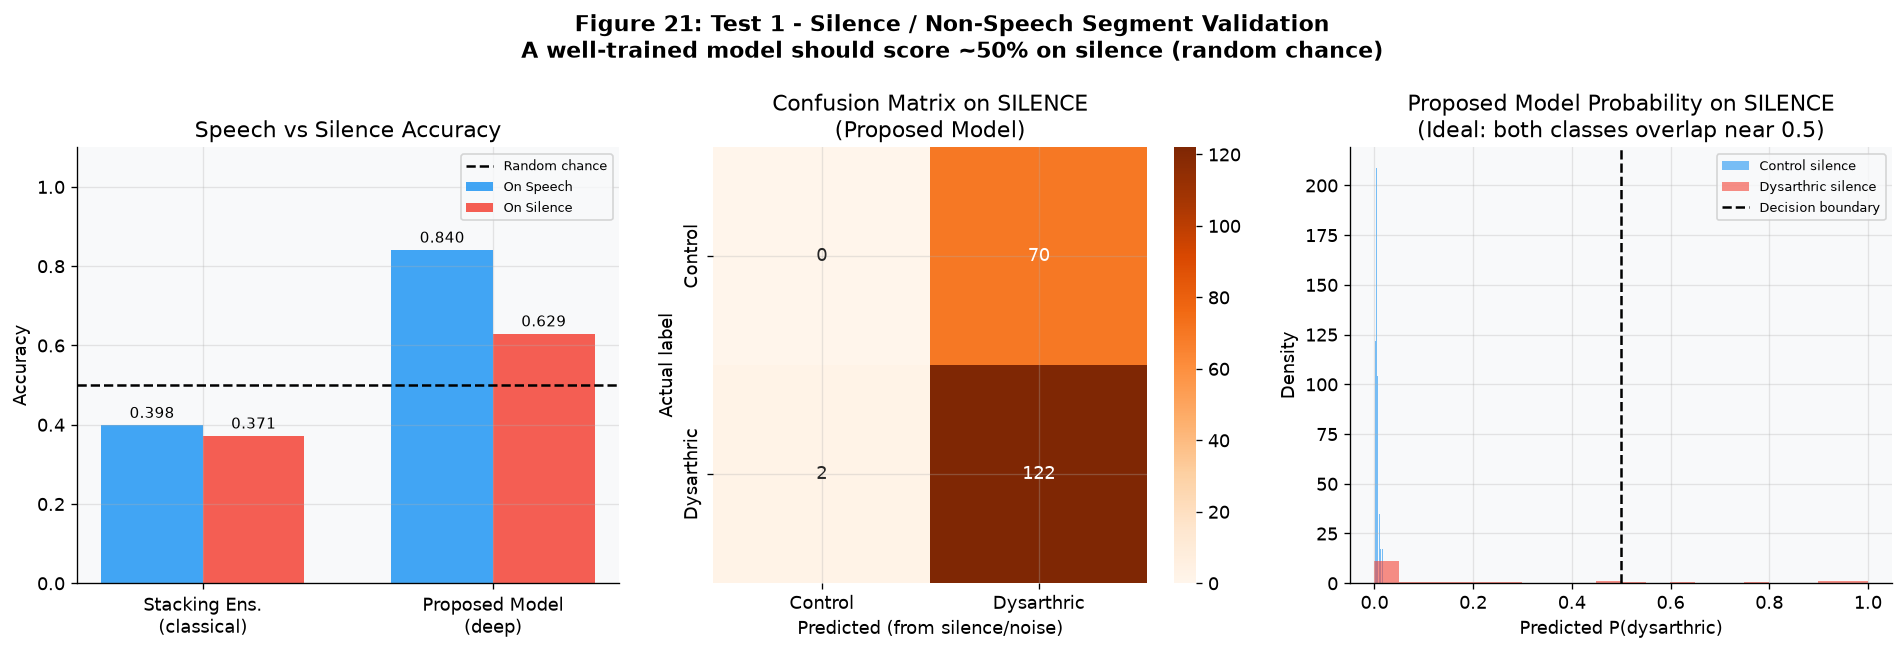

Figure 21 saved.


In [129]:
# ── Figure 21: Silence test visualisation ─────────────────────
if len(silence_labels) >= 10:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
    fig.suptitle("Figure 21: Test 1 - Silence / Non-Speech Segment Validation\n"
                 "A well-trained model should score ~50% on silence (random chance)",
                 fontsize=13, fontweight='bold')

    ax = axes[0]
    # speech_accs = [classical_results[2]["Accuracy"], dual_stream_results["Accuracy"]]  # Stacking, Dual-Stream
    speech_accs = [classical_results[2]["Accuracy"], ablation_stream1["Accuracy"]]  # Stacking, Proposed Model

    silence_accs = [stack_silence_acc, deep_silence_acc]
    model_labels = ["Stacking Ens.\n(classical)", "Proposed Model\n(deep)"]
    x = np.arange(len(model_labels)); width = 0.35
    b1 = ax.bar(x - width/2, speech_accs, width, label="On Speech", color=COLORS['control'], alpha=0.85)
    b2 = ax.bar(x + width/2, silence_accs, width, label="On Silence", color=COLORS['dysarthric'], alpha=0.85)
    ax.axhline(0.5, color='black', linestyle='--', linewidth=1.5, label='Random chance')
    ax.set_xticks(x); ax.set_xticklabels(model_labels)
    ax.set_ylabel("Accuracy"); ax.set_ylim(0, 1.1)
    ax.set_title("Speech vs Silence Accuracy")
    ax.legend(fontsize=8)
    for bar in list(b1) + list(b2):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)

    ax = axes[1]
    cm_silence = confusion_matrix(silence_labels_arr, deep_silence_preds)
    sns.heatmap(cm_silence, annot=True, fmt='d', cmap='Oranges', ax=ax,
                xticklabels=["Control", "Dysarthric"], yticklabels=["Control", "Dysarthric"])
    ax.set_title("Confusion Matrix on SILENCE\n(Proposed Model)")
    ax.set_xlabel("Predicted (from silence/noise)"); ax.set_ylabel("Actual label")

    ax = axes[2]
    ax.hist(deep_silence_probs[silence_labels_arr == 0], bins=20, alpha=0.6,
            color=COLORS['control'], label='Control silence', density=True)
    ax.hist(deep_silence_probs[silence_labels_arr == 1], bins=20, alpha=0.6,
            color=COLORS['dysarthric'], label='Dysarthric silence', density=True)
    ax.axvline(0.5, color='black', linestyle='--', linewidth=1.5, label='Decision boundary')
    ax.set_xlabel("Predicted P(dysarthric)"); ax.set_ylabel("Density")
    ax.set_title("Proposed Model Probability on SILENCE\n(Ideal: both classes overlap near 0.5)")
    ax.legend(fontsize=8)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "fig21_silence_test.png", bbox_inches='tight', dpi=150)
    plt.show()
    print("Figure 21 saved.")

In [130]:
# ── Permutation importance (classical, Stacking Ensemble) ────────────────────
FEATURE_NAMES_126 = [f"feat_{i:03d}" for i in range(126)]

def feature_idx_to_group(feat_name):
    '''Map a feat_NNN name to its human-readable feature-group label.'''
    idx = int(feat_name.replace("feat_", ""))
    if   idx < 13:  return "MFCC mean"
    elif idx < 26:  return "MFCC std"
    elif idx < 39:  return "Delta-MFCC mean"
    elif idx < 52:  return "Delta-MFCC std"
    elif idx < 65:  return "Delta2-MFCC mean"
    elif idx < 78:  return "Delta2-MFCC std"
    elif idx < 80:  return "ZCR"
    elif idx < 82:  return "RMS Energy"
    elif idx < 84:  return "Spectral Centroid"
    elif idx < 86:  return "Spectral Bandwidth"
    elif idx < 88:  return "Spectral Rolloff"
    elif idx < 102: return "Spectral Contrast"
    elif idx < 114: return "Chroma mean"
    else:           return "Chroma std"

print("Computing permutation importance for the Stacking Ensemble on the test set...")
perm_result = permutation_importance(
    classical_models["Stacking Ensemble"], X_test_sel, y_test_c,
    n_repeats=15, random_state=SEED, n_jobs=-1, scoring="f1")

selected_indices = np.where(selector.get_support())[0]
selected_names = [FEATURE_NAMES_126[i] for i in selected_indices]

perm_df = pd.DataFrame({
    "feature": selected_names,
    "importance": perm_result.importances_mean,
    "std": perm_result.importances_std,
    "group": [feature_idx_to_group(n) for n in selected_names],
}).sort_values("importance", ascending=False)

MFCC_GROUPS = {"MFCC mean", "MFCC std", "Delta-MFCC mean", "Delta-MFCC std",
               "Delta2-MFCC mean", "Delta2-MFCC std"}
mfcc_importance = perm_df[perm_df["group"].isin(MFCC_GROUPS)]["importance"].sum()
other_importance = perm_df[~perm_df["group"].isin(MFCC_GROUPS)]["importance"].sum()
total_importance = mfcc_importance + other_importance
mfcc_fraction = mfcc_importance / total_importance if total_importance > 0 else 0.5

print(f"\nTop 10 most important features (classical, Stacking Ensemble):")
print(perm_df[["feature", "group", "importance"]].head(10).to_string(index=False))
print(f"\nMFCC/delta family accounts for {mfcc_fraction*100:.1f}% of total permutation importance.")

Computing permutation importance for the Stacking Ensemble on the test set...

Top 10 most important features (classical, Stacking Ensemble):
 feature             group  importance
feat_081        RMS Energy    0.099503
feat_011         MFCC mean    0.083154
feat_013          MFCC std    0.083106
feat_101 Spectral Contrast    0.039663
feat_039    Delta-MFCC std    0.038282
feat_086  Spectral Rolloff    0.034120
feat_082 Spectral Centroid    0.028475
feat_080        RMS Energy    0.017213
feat_100 Spectral Contrast    0.012695
feat_093 Spectral Contrast    0.008525

MFCC/delta family accounts for 48.6% of total permutation importance.


In [131]:
# ── Gradient-based stream attribution (deep model) ────────────────────────────
def compute_stream_attribution(model, logmel, traj, lengths=None):
    '''
    Gradient-based attribution of the dysarthria logit to each stream's
    pooled embedding, used as the deep-model analogue of feature importance.

    Args:
        model: DualStreamDysarthriaModel.
        logmel, traj, lengths: a batch, as produced by TORGODualStreamDataset.

    Returns:
        (s_attr, t_attr): np.ndarray of shape (B,) each - the L2 norm of the
        gradient of the dysarthric-class logit w.r.t. the spectro-temporal
        embedding s and the trajectory embedding t, respectively.
    '''
    model.eval()
    with torch.enable_grad():
        s = model.spectro_encoder(logmel, lengths).detach().clone().requires_grad_(True)
        t = model.traj_encoder(traj, lengths).detach().clone().requires_grad_(True)
        emb = model.fusion(s, t)
        dys_logits = model.dysarthria_head(emb)
        score = dys_logits[:, 1].sum()
        s_grad, t_grad = torch.autograd.grad(score, [s, t])
    return s_grad.norm(dim=1).detach().cpu().numpy(), t_grad.norm(dim=1).detach().cpu().numpy()

In [132]:
# ── Run stream attribution over the test set ──────────────────────────────────
s_attrs, t_attrs, attr_labels = [], [], []
for logmel_b, traj_b, len_b, label_b, _ in test_loader:
    logmel_b, traj_b, len_b = logmel_b.to(DEVICE), traj_b.to(DEVICE), len_b.to(DEVICE)
    s_a, t_a = compute_stream_attribution(model, logmel_b, traj_b, len_b)
    s_attrs.append(s_a); t_attrs.append(t_a); attr_labels.append(label_b.numpy())

s_attrs = np.concatenate(s_attrs)
t_attrs = np.concatenate(t_attrs)
attr_labels = np.concatenate(attr_labels)

attr_summary = pd.DataFrame({
    "Class": [LABEL_MAP[l] for l in attr_labels],
    "Stream1_attr": s_attrs, "Stream2_attr": t_attrs,
}).groupby("Class")[["Stream1_attr", "Stream2_attr"]].mean()
print("Mean gradient-attribution magnitude by stream and class:")
print(attr_summary.to_string())

Mean gradient-attribution magnitude by stream and class:
            Stream1_attr  Stream2_attr
Class                                 
Control         1.632565      0.684251
Dysarthric      0.814428      0.490037


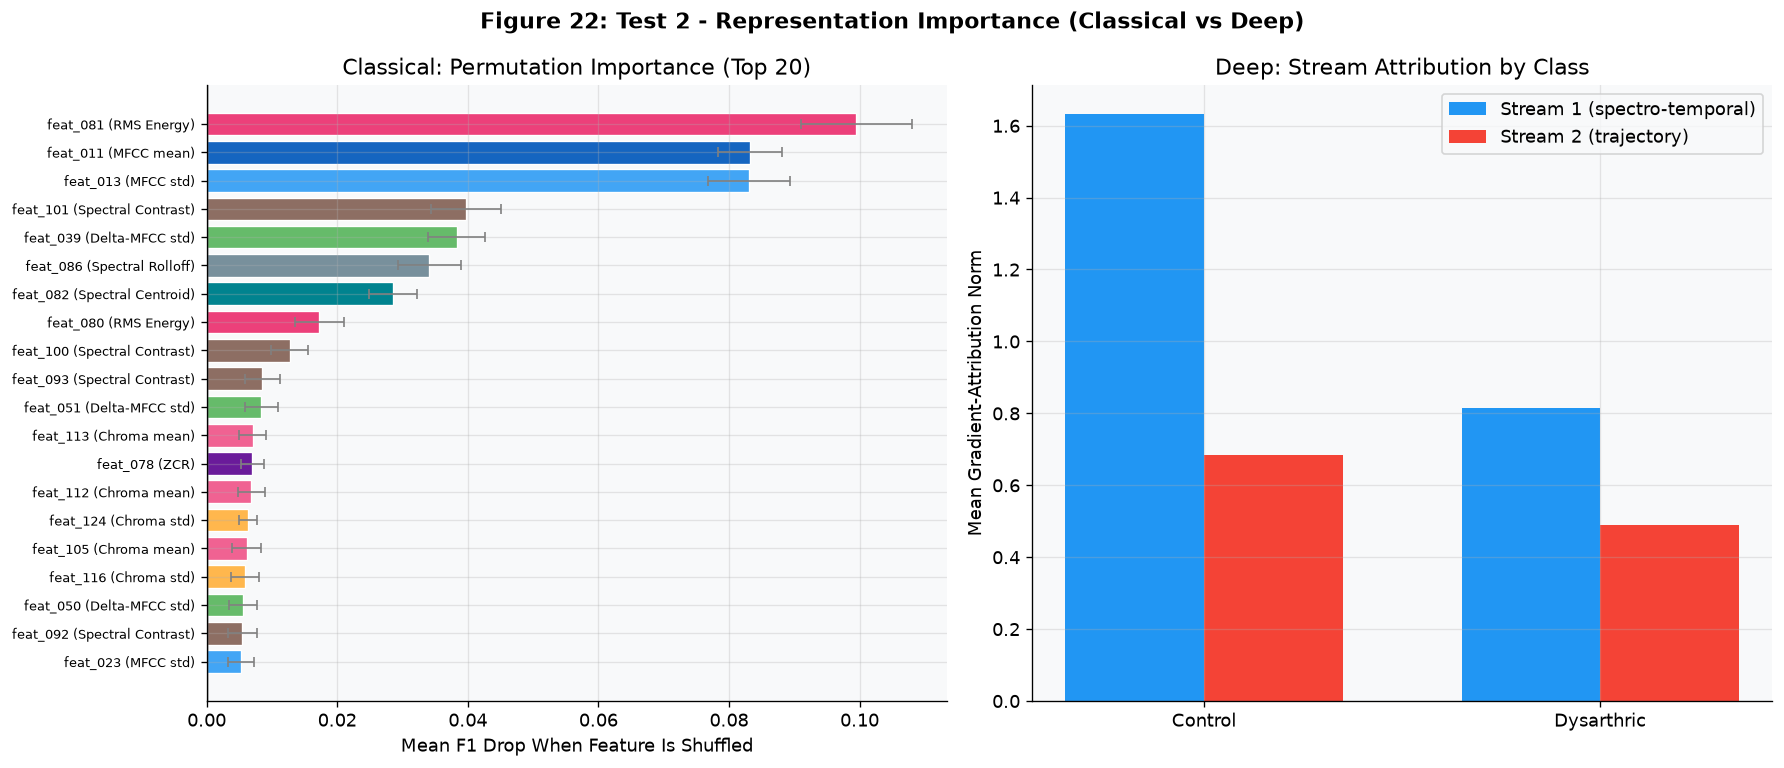

Figure 22 saved.


In [133]:
# ── Figure 22: permutation importance (classical) + stream attribution (deep) ──
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
fig.suptitle("Figure 22: Test 2 - Representation Importance (Classical vs Deep)",
             fontsize=13, fontweight='bold')

GROUP_COLORS = {
    "MFCC mean": "#1565C0", "MFCC std": "#42A5F5",
    "Delta-MFCC mean": "#2E7D32", "Delta-MFCC std": "#66BB6A",
    "Delta2-MFCC mean": "#E65100", "Delta2-MFCC std": "#FFA726",
    "ZCR": "#6A1B9A", "RMS Energy": "#EC407A",
    "Spectral Centroid": "#00838F", "Spectral Bandwidth": "#00ACC1",
    "Spectral Rolloff": "#78909C", "Spectral Contrast": "#8D6E63",
    "Chroma mean": "#F06292", "Chroma std": "#FFB74D",
}

ax = axes[0]
top_perm = perm_df.head(20)
bar_colors = [GROUP_COLORS.get(g, "#9E9E9E") for g in top_perm["group"]]
ax.barh(range(len(top_perm)), top_perm["importance"].values[::-1],
        xerr=top_perm["std"].values[::-1], color=bar_colors[::-1],
        edgecolor='white', linewidth=0.8, error_kw=dict(elinewidth=1, ecolor='gray', capsize=3))
ax.set_yticks(range(len(top_perm)))
ax.set_yticklabels([f"{n} ({g})" for n, g in zip(top_perm["feature"].values[::-1], top_perm["group"].values[::-1])],
                    fontsize=7.5)
ax.set_xlabel("Mean F1 Drop When Feature Is Shuffled")
ax.set_title("Classical: Permutation Importance (Top 20)")
ax.axvline(0, color='black', linewidth=0.8)

ax = axes[1]
categories = ["Control", "Dysarthric"]
stream1_means = [attr_summary.loc[c, "Stream1_attr"] for c in categories]
stream2_means = [attr_summary.loc[c, "Stream2_attr"] for c in categories]
x = np.arange(len(categories)); width = 0.35
ax.bar(x - width/2, stream1_means, width, label="Stream 1 (spectro-temporal)", color=COLORS['control'])
ax.bar(x + width/2, stream2_means, width, label="Stream 2 (trajectory)", color=COLORS['dysarthric'])
ax.set_xticks(x); ax.set_xticklabels(categories)
ax.set_ylabel("Mean Gradient-Attribution Norm")
ax.set_title("Deep: Stream Attribution by Class")
ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig22_representation_importance.png", bbox_inches='tight', dpi=150)
plt.show()
print("Figure 22 saved.")

In [134]:
# =====================================================================
# 18.3. Cross-microphone generalisation — classical model cache
# =====================================================================
def filter_by_mic(idx_array, mic_type, meta_df=meta):
    mask = (meta_df.loc[idx_array, "mic_type"] == mic_type).values
    return idx_array[mask]

def fit_mic_specific_svm(idx_train, seed=SEED):
    X_r = X_classical[idx_train]
    y_r = meta.loc[idx_train, "label"].values
    sc = StandardScaler().fit(X_r)
    sel = SelectKBest(
        f_classif, k=min(60, X_r.shape[1])
    ).fit(sc.transform(X_r), y_r)
    clf = SVC(
        kernel="rbf",
        class_weight="balanced",
        probability=True,
        random_state=seed,
    ).fit(sel.transform(sc.transform(X_r)), y_r)
    return sc, sel, clf

def eval_mic_specific(sc, sel, clf, idx_eval):
    X_e = X_classical[idx_eval]
    y_e = meta.loc[idx_eval, "label"].values
    preds = clf.predict(sel.transform(sc.transform(X_e)))
    return (
        accuracy_score(y_e, preds),
        f1_score(y_e, preds, zero_division=0),
    )

train_idx_head_c = filter_by_mic(train_idx_c, "head")
train_idx_array_c = filter_by_mic(train_idx_c, "array")
test_idx_head_c = filter_by_mic(test_idx_c, "head")
test_idx_array_c = filter_by_mic(test_idx_c, "array")

MIC_CLASSICAL_CACHE = os.path.join(
    STAGE_DIR, "mic_specific_classical.pkl"
)

_micc = None
if os.path.exists(MIC_CLASSICAL_CACHE):
    try:
        _micc = pickle.load(open(MIC_CLASSICAL_CACHE, "rb"))
    except Exception:
        _micc = None

if (
    _micc
    and _micc.get("pipeline_signature") == PIPELINE_SIGNATURE
    and _micc.get("source_signature") == classical_source
):
    (
        scaler_head_only,
        selector_head_only,
        svm_head_only,
        scaler_array_only,
        selector_array_only,
        svm_array_only,
        mic_results,
    ) = _micc["payload"]
    print("[CACHE] Loaded mic-specific classical models/results.")
else:
    scaler_head_only, selector_head_only, svm_head_only = fit_mic_specific_svm(
        train_idx_head_c, seed=SEED
    )
    scaler_array_only, selector_array_only, svm_array_only = fit_mic_specific_svm(
        train_idx_array_c, seed=SEED
    )

    mic_results = {
        "acc_h2h": eval_mic_specific(
            scaler_head_only, selector_head_only, svm_head_only, test_idx_head_c
        )[0],
        "f1_h2h": eval_mic_specific(
            scaler_head_only, selector_head_only, svm_head_only, test_idx_head_c
        )[1],
        "acc_h2a": eval_mic_specific(
            scaler_head_only, selector_head_only, svm_head_only, test_idx_array_c
        )[0],
        "f1_h2a": eval_mic_specific(
            scaler_head_only, selector_head_only, svm_head_only, test_idx_array_c
        )[1],
        "acc_a2a": eval_mic_specific(
            scaler_array_only, selector_array_only, svm_array_only, test_idx_array_c
        )[0],
        "f1_a2a": eval_mic_specific(
            scaler_array_only, selector_array_only, svm_array_only, test_idx_array_c
        )[1],
        "acc_a2h": eval_mic_specific(
            scaler_array_only, selector_array_only, svm_array_only, test_idx_head_c
        )[0],
        "f1_a2h": eval_mic_specific(
            scaler_array_only, selector_array_only, svm_array_only, test_idx_head_c
        )[1],
    }

    atomic_pickle_dump(
        {
            "pipeline_signature": PIPELINE_SIGNATURE,
            "source_signature": classical_source,
            "payload": (
                scaler_head_only,
                selector_head_only,
                svm_head_only,
                scaler_array_only,
                selector_array_only,
                svm_array_only,
                mic_results,
            ),
        },
        MIC_CLASSICAL_CACHE,
    )
    print("[CACHE] Trained and cached mic-specific classical models/results.")

acc_h2h = mic_results["acc_h2h"]
f1_h2h = mic_results["f1_h2h"]
acc_h2a = mic_results["acc_h2a"]
f1_h2a = mic_results["f1_h2a"]
acc_a2a = mic_results["acc_a2a"]
f1_a2a = mic_results["f1_a2a"]
acc_a2h = mic_results["acc_a2h"]
f1_a2h = mic_results["f1_a2h"]

print("Classical cross-mic generalisation:")
print(f"  Head -> Head   : Accuracy={acc_h2h:.4f} F1={f1_h2h:.4f}")
print(f"  Head -> Array  : Accuracy={acc_h2a:.4f} F1={f1_h2a:.4f}")
print(f"  Array -> Array : Accuracy={acc_a2a:.4f} F1={f1_a2a:.4f}")
print(f"  Array -> Head   : Accuracy={acc_a2h:.4f} F1={f1_a2h:.4f}")


[CACHE] Trained and cached mic-specific classical models/results.
Classical cross-mic generalisation:
  Head -> Head   : Accuracy=0.9682 F1=0.9660
  Head -> Array  : Accuracy=0.6995 F1=0.6382
  Array -> Array : Accuracy=0.9419 F1=0.9062
  Array -> Head   : Accuracy=0.4176 F1=0.5751


In [135]:
# =====================================================================
# 18.3b. Cross-microphone generalisation — deep model cache
# =====================================================================
def make_loader(idx_array, augment=False, batch_size=BATCH_SIZE, shuffle=False):
    ds = TORGODualStreamDataset(
        logmels[idx_array],
        trajs[idx_array],
        meta.loc[idx_array, "label"].values,
        meta.loc[idx_array, "gender"].values,
        lengths=meta.loc[idx_array, "valid_frames"].values,
        augment=augment,
    )
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=False,
    )

def train_mic_specific_deep_model(
    idx_train_mic,
    stage_name,
    seed,
    epochs=20,
    patience=5,
):
    loader = make_loader(
        idx_train_mic,
        augment=True,
        shuffle=False,
    )
    m = SingleStreamModel(stream="spectro").to(DEVICE)

    resume_path = os.path.join(
        CHECKPOINT_DIR, f"{stage_name}_resume.pt"
    )
    final_path = os.path.join(
        CHECKPOINT_DIR, f"{stage_name}_final.pt"
    )

    m, _, thr = finetune_supervised(
        m,
        loader,
        val_loader,
        epochs=epochs,
        patience=patience,
        device=DEVICE,
        checkpoint_path=resume_path,
        final_path=final_path,
        train_indices=idx_train_mic,
        stage_name=stage_name,
        seed=seed,
        checkpoint_every_batch=CHECKPOINT_INTERVAL_BATCHES,
    )
    return m, thr

train_idx_head = filter_by_mic(train_idx, "head")
train_idx_array = filter_by_mic(train_idx, "array")
test_idx_head = filter_by_mic(test_idx, "head")
test_idx_array = filter_by_mic(test_idx, "array")

test_loader_head = make_loader(test_idx_head)
test_loader_array = make_loader(test_idx_array)

MIC_DEEP_RESULT_CACHE = os.path.join(
    STAGE_DIR, "mic_specific_deep_results.pkl"
)

_micd = None
if os.path.exists(MIC_DEEP_RESULT_CACHE):
    try:
        _micd = pickle.load(open(MIC_DEEP_RESULT_CACHE, "rb"))
    except Exception:
        _micd = None

if (
    _micd
    and _micd.get("pipeline_signature") == PIPELINE_SIGNATURE
):
    mic_deep_results = _micd["results"]

    # The final model files are authoritative for loading the trained models.
    deep_model_head = SingleStreamModel(stream="spectro").to(DEVICE)
    deep_model_array = SingleStreamModel(stream="spectro").to(DEVICE)

    _head_bundle = safe_torch_load(
        os.path.join(
            CHECKPOINT_DIR, "mic_deep_head_final.pt"
        )
    )
    _array_bundle = safe_torch_load(
        os.path.join(
            CHECKPOINT_DIR, "mic_deep_array_final.pt"
        )
    )

    deep_model_head.load_state_dict(_head_bundle["model_state_dict"])
    deep_model_array.load_state_dict(_array_bundle["model_state_dict"])
    thr_head = float(_head_bundle["threshold"])
    thr_array = float(_array_bundle["threshold"])

    print("[CACHE] Loaded cross-mic deep models/results.")
else:
    torch.manual_seed(SEED + 10)
    deep_model_head, thr_head = train_mic_specific_deep_model(
        train_idx_head,
        stage_name="mic_deep_head",
        seed=SEED + 10,
    )

    torch.manual_seed(SEED + 11)
    deep_model_array, thr_array = train_mic_specific_deep_model(
        train_idx_array,
        stage_name="mic_deep_array",
        seed=SEED + 11,
    )

    def eval_deep_on_loader(m, loader, thr):
        yt, yp = get_predictions(m, loader, device=DEVICE)
        preds = (yp >= thr).astype(int)
        return (
            accuracy_score(yt, preds),
            f1_score(yt, preds, zero_division=0),
        )

    mic_deep_results = {
        "deep_acc_h2h": eval_deep_on_loader(
            deep_model_head, test_loader_head, thr_head
        )[0],
        "deep_f1_h2h": eval_deep_on_loader(
            deep_model_head, test_loader_head, thr_head
        )[1],
        "deep_acc_h2a": eval_deep_on_loader(
            deep_model_head, test_loader_array, thr_head
        )[0],
        "deep_f1_h2a": eval_deep_on_loader(
            deep_model_head, test_loader_array, thr_head
        )[1],
        "deep_acc_a2a": eval_deep_on_loader(
            deep_model_array, test_loader_array, thr_array
        )[0],
        "deep_f1_a2a": eval_deep_on_loader(
            deep_model_array, test_loader_array, thr_array
        )[1],
        "deep_acc_a2h": eval_deep_on_loader(
            deep_model_array, test_loader_head, thr_array
        )[0],
        "deep_f1_a2h": eval_deep_on_loader(
            deep_model_array, test_loader_head, thr_array
        )[1],
    }

    atomic_pickle_dump(
        {
            "pipeline_signature": PIPELINE_SIGNATURE,
            "results": mic_deep_results,
        },
        MIC_DEEP_RESULT_CACHE,
    )
    print("[CACHE] Trained and cached cross-mic deep models/results.")

deep_acc_h2h = mic_deep_results["deep_acc_h2h"]
deep_f1_h2h = mic_deep_results["deep_f1_h2h"]
deep_acc_h2a = mic_deep_results["deep_acc_h2a"]
deep_f1_h2a = mic_deep_results["deep_f1_h2a"]
deep_acc_a2a = mic_deep_results["deep_acc_a2a"]
deep_f1_a2a = mic_deep_results["deep_f1_a2a"]
deep_acc_a2h = mic_deep_results["deep_acc_a2h"]
deep_f1_a2h = mic_deep_results["deep_f1_a2h"]

cross_drop_h2a_classical = acc_h2h - acc_h2a
cross_drop_a2h_classical = acc_a2a - acc_a2h
cross_drop_h2a_deep = deep_acc_h2h - deep_acc_h2a
cross_drop_a2h_deep = deep_acc_a2a - deep_acc_a2h

print("\nDeep-model cross-mic generalisation:")
print(f"  Head -> Head   : Accuracy={deep_acc_h2h:.4f} F1={deep_f1_h2h:.4f}")
print(f"  Head -> Array  : Accuracy={deep_acc_h2a:.4f} F1={deep_f1_h2a:.4f}")
print(f"  Array -> Array : Accuracy={deep_acc_a2a:.4f} F1={deep_f1_a2a:.4f}")
print(f"  Array -> Head   : Accuracy={deep_acc_a2h:.4f} F1={deep_f1_a2h:.4f}")


Epoch 001/20 | train=0.3375 | val=1.4035 | val_acc=0.5454 | val_f1=0.7058 | gate=nan


Epoch 002/20 | train=0.2523 | val=1.4596 | val_acc=0.5734 | val_f1=0.7177 | gate=nan


Epoch 003/20 | train=0.2154 | val=2.2166 | val_acc=0.5758 | val_f1=0.7189 | gate=nan


Epoch 004/20 | train=0.2235 | val=2.6750 | val_acc=0.5454 | val_f1=0.7058 | gate=nan


Epoch 005/20 | train=0.2134 | val=1.2191 | val_acc=0.5763 | val_f1=0.7192 | gate=nan


...

Epoch 005/20 | train=0.3158 | val=3.8424 | val_acc=0.5469 | val_f1=0.7060 | gate=nan


Epoch 006/20 | train=0.2866 | val=2.0409 | val_acc=0.5459 | val_f1=0.7061 | gate=nan


Epoch 007/20 | train=0.2681 | val=2.0012 | val_acc=0.5484 | val_f1=0.7061 | gate=nan


Epoch 008/20 | train=0.2320 | val=1.8992 | val_acc=0.5454 | val_f1=0.7058 | gate=nan


Epoch 009/20 | train=0.2206 | val=2.4412 | val_acc=0.5459 | val_f1=0.7061 | gate=nan
Early stopping at epoch 9.
[DONE] mic_deep_array cached at /Users/Noor/dysarthria-v4/cache/dysarthria_detection_v4/run_e1eb4e70a21d7fc1/checkpoints/mic_deep_array_final.pt
[CACHE] Trained and cached cross-mic deep models/results.

Deep-model cross-mic generalisation:
  Head -> Head   : Accuracy=0.5690 F1=0.6904
  Head -> Array  : Accuracy=0.2818 F1=0.4397
  Array -> Array : Accuracy=0.4079 F1=0.4876
  Array -> Head   : Accuracy=0.4798 F1=0.6485


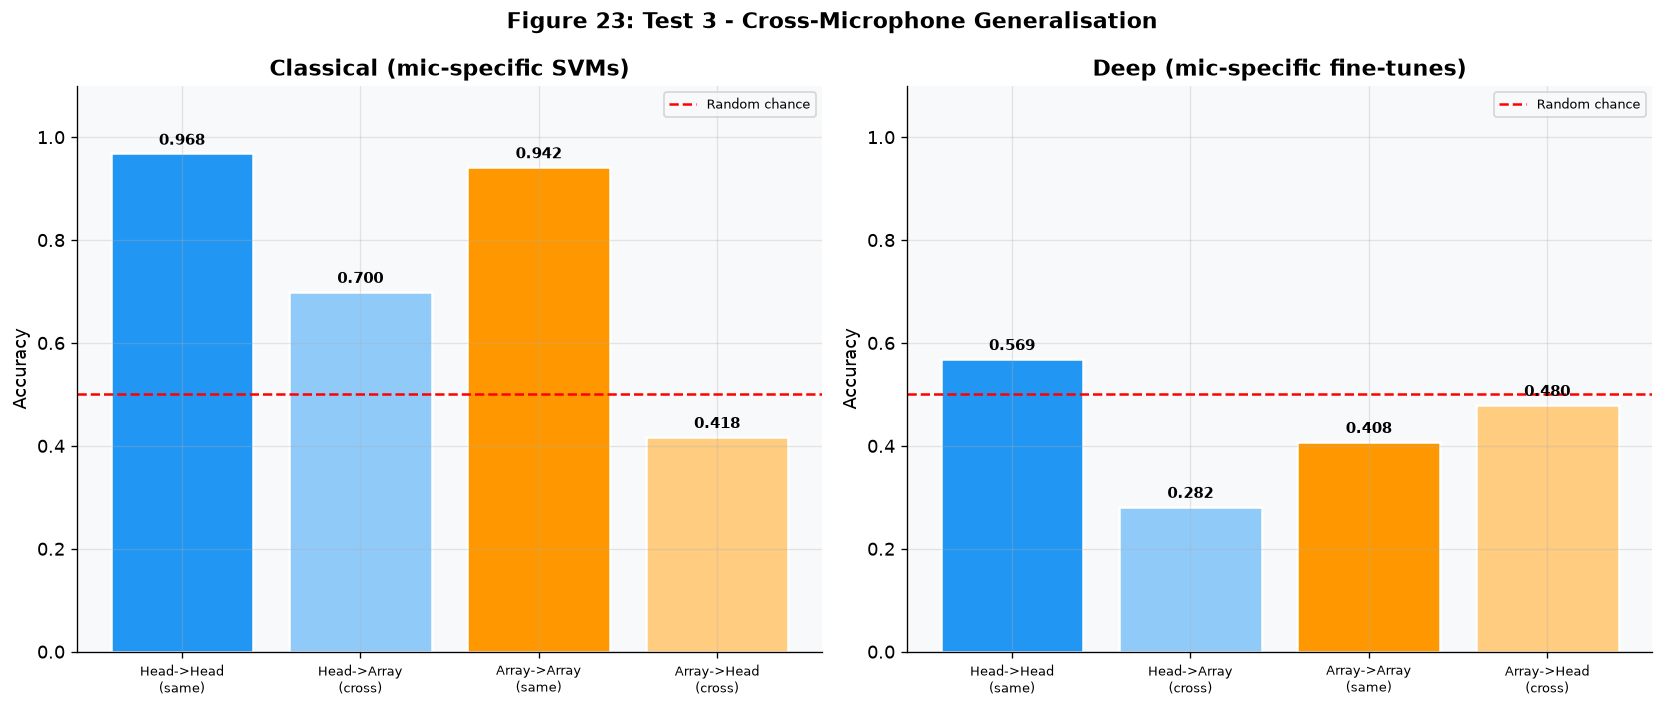

Figure 23 saved.


In [136]:
# ── Figure 23: cross-mic generalisation, classical vs deep ────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Figure 23: Test 3 - Cross-Microphone Generalisation", fontsize=13, fontweight='bold')

categories = ["Head->Head\n(same)", "Head->Array\n(cross)", "Array->Array\n(same)", "Array->Head\n(cross)"]
bar_colors_c = ['#2196F3', '#90CAF9', '#FF9800', '#FFCC80']

for ax, values, title in [
        (axes[0], [acc_h2h, acc_h2a, acc_a2a, acc_a2h], "Classical (mic-specific SVMs)"),
        (axes[1], [deep_acc_h2h, deep_acc_h2a, deep_acc_a2a, deep_acc_a2h], "Deep (mic-specific fine-tunes)")]:
    bars = ax.bar(categories, values, color=bar_colors_c, edgecolor='white', linewidth=1.5)
    ax.axhline(0.5, color='red', linestyle='--', linewidth=1.5, label='Random chance')
    ax.set_ylabel("Accuracy"); ax.set_ylim(0, 1.1)
    ax.set_title(title, fontweight='bold')
    ax.legend(fontsize=8)
    ax.tick_params(axis='x', labelsize=8)
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig23_cross_mic_test.png", bbox_inches='tight', dpi=150)
plt.show()
print("Figure 23 saved.")

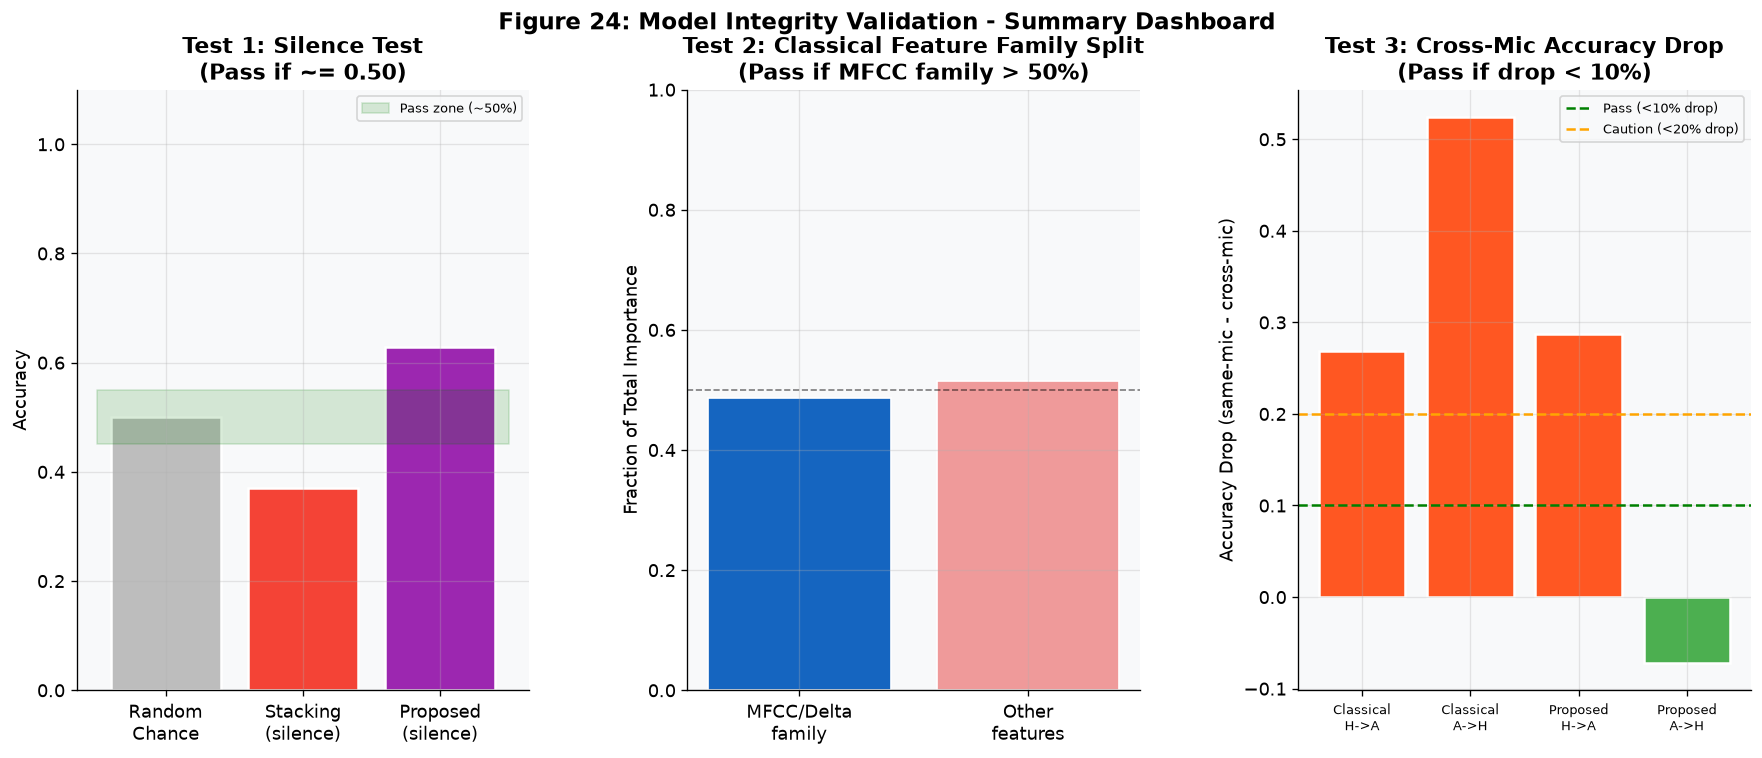

Figure 24 saved.


In [137]:
# ── Figure 24: three-test summary dashboard ───────────────────────────────────
fig = plt.figure(figsize=(18, 6.5))
fig.suptitle("Figure 24: Model Integrity Validation - Summary Dashboard", fontsize=14, fontweight='bold')
gs = gridspec.GridSpec(1, 3, figure=fig, wspace=0.35)

ax1 = fig.add_subplot(gs[0])
if deep_silence_acc is not None:
    t1_labels = ["Random\nChance", "Stacking\n(silence)", "Proposed\n(silence)"]
    t1_values = [0.5, stack_silence_acc, deep_silence_acc]
else:
    t1_labels = ["Random\nChance", "Stacking\n(N/A)", "Proposed\n(N/A)"]
    t1_values = [0.5, 0.5, 0.5]
ax1.bar(t1_labels, t1_values, color=['#BDBDBD', '#F44336', '#9C27B0'], edgecolor='white', linewidth=1.5)
ax1.fill_between([-0.5, 2.5], [0.45, 0.45], [0.55, 0.55], alpha=0.15, color='green', label='Pass zone (~50%)')
ax1.set_ylim(0, 1.1); ax1.set_ylabel("Accuracy")
ax1.set_title("Test 1: Silence Test\n(Pass if ~= 0.50)", fontweight='bold')
ax1.legend(fontsize=8)

ax2 = fig.add_subplot(gs[1])
ax2.bar(["MFCC/Delta\nfamily", "Other\nfeatures"], [mfcc_fraction, 1 - mfcc_fraction],
        color=['#1565C0', '#EF9A9A'], edgecolor='white')
ax2.axhline(0.5, color='black', linestyle='--', linewidth=1, alpha=0.5)
ax2.set_ylim(0, 1.0); ax2.set_ylabel("Fraction of Total Importance")
ax2.set_title("Test 2: Classical Feature Family Split\n(Pass if MFCC family > 50%)", fontweight='bold')

ax3 = fig.add_subplot(gs[2])
drop_labels = ["Classical\nH->A", "Classical\nA->H", "Proposed\nH->A", "Proposed\nA->H"]
drop_values = [cross_drop_h2a_classical, cross_drop_a2h_classical, cross_drop_h2a_deep, cross_drop_a2h_deep]
drop_colors = ['#FF5722' if d > 0.20 else '#4CAF50' if d < 0.10 else '#FF9800' for d in drop_values]
ax3.bar(drop_labels, drop_values, color=drop_colors, edgecolor='white', linewidth=1.5)
ax3.axhline(0.10, color='green', linestyle='--', linewidth=1.5, label='Pass (<10% drop)')
ax3.axhline(0.20, color='orange', linestyle='--', linewidth=1.5, label='Caution (<20% drop)')
ax3.set_ylabel("Accuracy Drop (same-mic - cross-mic)")
ax3.set_title("Test 3: Cross-Mic Accuracy Drop\n(Pass if drop < 10%)", fontweight='bold')
ax3.legend(fontsize=8)
ax3.tick_params(axis='x', labelsize=8)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig24_integrity_summary.png", bbox_inches='tight', dpi=150)
plt.show()
print("Figure 24 saved.")

In [138]:
# ── Printed final integrity verdict table ─────────────────────────────────────
def verdict_silence(acc):
    if acc is None: return "N/A"
    return "PASS" if acc < 0.60 else ("CAUTION" if acc < 0.75 else "FAIL")

def verdict_feature_split(frac):
    return "PASS" if frac > 0.50 else ("CAUTION" if frac > 0.35 else "FAIL")

def verdict_cross_mic(drop):
    return "PASS" if drop < 0.10 else ("CAUTION" if drop < 0.20 else "FAIL")

integrity_report = pd.DataFrame([
    {"Test": "Silence (Stacking)",    "Result": verdict_silence(stack_silence_acc), "Value": stack_silence_acc},
    {"Test": "Silence (Proposed Model)", "Result": verdict_silence(deep_silence_acc),  "Value": deep_silence_acc},
    {"Test": "Feature Family Split (Classical)", "Result": verdict_feature_split(mfcc_fraction), "Value": mfcc_fraction},
    {"Test": "Cross-Mic Classical (max drop)", "Result": verdict_cross_mic(max(cross_drop_h2a_classical, cross_drop_a2h_classical)),
     "Value": max(cross_drop_h2a_classical, cross_drop_a2h_classical)},
    {"Test": "Cross-Mic Proposed (max drop)", "Result": verdict_cross_mic(max(cross_drop_h2a_deep, cross_drop_a2h_deep)),
     "Value": max(cross_drop_h2a_deep, cross_drop_a2h_deep)},
])
print("FINAL MODEL INTEGRITY REPORT")
print(integrity_report.to_string(index=False))

FINAL MODEL INTEGRITY REPORT
                            Test  Result    Value
              Silence (Stacking)    PASS 0.371134
        Silence (Proposed Model) CAUTION 0.628866
Feature Family Split (Classical) CAUTION 0.485679
  Cross-Mic Classical (max drop)    FAIL 0.524321
   Cross-Mic Proposed (max drop)    FAIL 0.287229


In [139]:
# ── V3 gate diagnostic ────────────────────────────────────────
try:
    emb_test, gates_test, labels_test = get_embeddings_and_gates(model, test_loader, device=DEVICE)
    gate_mean = gates_test.mean(axis=0)
    print(f"Mean Stream-1 gate: {gate_mean.mean():.4f}")
    print(f"Gate std: {gate_mean.std():.4f}")
    print("Interpretation: values near 1 rely more on the proven CNN-BiLSTM stream;")
    print("values near 0 rely more on the trajectory Transformer.")
except Exception as e:
    print("Gate diagnostic unavailable:", e)


Mean Stream-1 gate: 0.4734
Gate std: 0.3875
Interpretation: values near 1 rely more on the proven CNN-BiLSTM stream;
values near 0 rely more on the trajectory Transformer.


In [141]:
# ── Consolidated results table across every model evaluated in this notebook ──
all_results = classical_results + ablation_results

metric_aliases = {
    "Accuracy": ["Accuracy", "accuracy"],
    "F1_dysarthric": ["F1_dysarthric", "F1", "F1 (Macro)", "f1"],
    "ROC_AUC": ["ROC_AUC", "ROC-AUC", "roc_auc"],
    "PR_AUC": ["PR_AUC", "PR-AUC", "average_precision"],
    "Brier": ["Brier", "Brier Score"],
}

def safe_metric(result, metric):
    for key in metric_aliases[metric]:
        if key in result:
            return float(result[key])
    return np.nan

final_summary = pd.DataFrame([
    {
        "Model": result.get("Model", "Unknown"),
        **{
            metric: safe_metric(result, metric)
            for metric in metric_aliases
        },
    }
    for result in all_results
]).drop_duplicates(
    subset="Model",
    keep="last"
).round(4)

print("Consolidated results (test set) across all models trained in this notebook:")
print(final_summary.to_string(index=False))
print(f"\nExpected Calibration Error (Dual-Stream, full): {test_ece:.4f}")
print(f"Gender-subgroup F1 (Dual-Stream, full):\n{fairness_df[['Group','F1','ROC_AUC']].to_string(index=False)}")

Consolidated results (test set) across all models trained in this notebook:
                       Model  Accuracy  F1_dysarthric  ROC_AUC  PR_AUC  Brier
                   SVM (RBF)    0.5054         0.4601   0.9707  0.9588 0.0693
               Random Forest    0.4329         0.3473   0.9861  0.9810 0.0682
           Stacking Ensemble    0.3979         0.2852   0.9764  0.9678 0.0909
  Stream 1 Only (CNN-BiLSTM)    0.8402         0.8395   0.9835  0.9812 0.0437
 Stream 2 Only (Transformer)    0.6660         0.6648   0.8907  0.8782 0.1260
Dual-Stream (No Pretraining)    0.8320         0.8312   0.9642  0.9586 0.0560
          Dual-Stream (Full)    0.7937         0.7936   0.9760  0.9729 0.0568

Expected Calibration Error (Dual-Stream, full): 0.0461
Gender-subgroup F1 (Dual-Stream, full):
 Group       F1  ROC_AUC
female 0.000000      NaN
  male 0.953394 0.989782


In [ ]:
# =====================================================================
# V4 cache status
# =====================================================================
print("\n" + "=" * 72)
print("V4 CACHE STATUS")
print("=" * 72)
print("Cache root:", CACHE_DIR)
print("Persistent root:", V4_ROOT)
print("Pretraining final:", PRETRAIN_FINAL_PATH, os.path.exists(PRETRAIN_FINAL_PATH))
print("Proposed fine-tune final:", FINETUNE_FINAL_PATH, os.path.exists(FINETUNE_FINAL_PATH))
print("Dual-stream aggregate:", FEATURE_CACHE_PATH, os.path.exists(FEATURE_CACHE_PATH))
print("Classical aggregate:", CLASSICAL_FEATURE_CACHE_PATH, os.path.exists(CLASSICAL_FEATURE_CACHE_PATH))
print("=" * 72)



V4 CACHE STATUS
Cache root: /Users/Noor/dysarthria-v4/cache/dysarthria_detection_v4/run_e1eb4e70a21d7fc1
Persistent root: /Users/Noor/dysarthria-v4/cache/dysarthria_detection_v4
Pretraining final: /Users/Noor/dysarthria-v4/cache/dysarthria_detection_v4/run_e1eb4e70a21d7fc1/checkpoints/v4_pretrain_final.pt True
Proposed fine-tune final: /Users/Noor/dysarthria-v4/cache/dysarthria_detection_v4/run_e1eb4e70a21d7fc1/checkpoints/v4_proposed_final.pt True
Dual-stream aggregate: /Users/Noor/dysarthria-v4/cache/dysarthria_detection_v4/run_e1eb4e70a21d7fc1/dual_stream_features.npz True
Classical aggregate: /Users/Noor/dysarthria-v4/cache/dysarthria_detection_v4/run_e1eb4e70a21d7fc1/classical_features.npy True


: 

## Local Mac run notes

V4 stores its features, metadata, splits, scalers, fitted models, training checkpoints, and evaluation caches under `v4/backups/dysarthria_detection_v4/`. Figures are written to `v4/outputs/`, and each run saves a timestamped notebook copy in `v4/backups/`. Set `DYSARTHRIA_V4_CACHE_ROOT` to override the cache location. A kernel or VS Code restart does not delete it.
